# CS781 Phase 4 – Final view / PEFT ablations (all 4 backbones)

Each architecture section includes:
1. **Phase-1 model + tokenizer classes** (checkpoint reload)
2. Full Phase-4 cells (hierarchical views, pooling, threshold tuning, F1 tables, plots, bundles)

Activate the architecture, ensure files exist, Run All.


In [ ]:
import os
import zipfile

# Create directory structure for our deliverables
os.makedirs('/kaggle/working/deliverables/phase4_custom_mha', exist_ok=True)
os.makedirs('/kaggle/working/deliverables/phase4_mla_moe', exist_ok=True)
os.makedirs('/kaggle/working/deliverables/phase4_alibi_gqa', exist_ok=True)
os.makedirs('/kaggle/working/deliverables/phase4_gqa_conv', exist_ok=True)

readme_content = """# CS781 Phase 4: Final View & Parameter-Efficient Fine-Tuning (PEFT) Ablations

This repository contains the complete phase 4 pipeline for four custom LLM backbones trained on legal corpus data and adapted for the legal outcome classification task (CJPE).

## 1. Model Architectures & Backbones

1. **`custom_mha`**: Standard Multi-Head Attention with Rotary Position Embeddings (RoPE), RMSNorm, and SwiGLU decoder.
2. **`mla_moe`**: Multi-Head Latent Attention (DeepSeek-style) with decoupled RoPE, weight absorption at inference, and DeepSeekMoE mixture-of-experts feed-forward block.
3. **`gqa_alibi`**: Grouped-Query Attention with Attention Linear Biases (ALiBi) position encoding, RMSNorm, and SwiGLU.
4. **`gqa_conv`**: Grouped-Query Attention with Rotary Position Embeddings (RoPE) and Dual-Path SwiGLU FFN enhanced with learning-rate decoupled 1D causal depthwise convolutions.

## 2. Adaptation Methodologies
We evaluate multiple parameter-efficient fine-tuning (PEFT) strategies across different context representation views (flat head, flat tail, flat head/tail hybrid, and hierarchical multi-chunk pooling):
- **LoRMA**: Multiplicative Low-Rank Multi-Head Adaptation.
- **AdaLoRA**: Adaptive Low-Rank Adaptation via dynamic SVD weight sensitivity rank pruning.
- **BitFit**: Bias-only parameter fine-tuning.
- **Bottleneck Adapters**: Serial low-rank feed-forward adapter insertions.
- **Knowledge Distillation (KD)**: Logit-matching optimization compressing deeper networks (8-12 layers) into highly efficient, short-context 4-layer student networks.

## 3. Experimental Setup & Running the Code
All models are configured to run out-of-the-box in two operational modes:

### Mode A: Evaluation & Submission Generation (Default Mode)
If you have pre-computed model checkpoints (e.g. `*_best.pt` inside the `ckpts` folder), the scripts automatically load them to bypass training. Running the notebook cells sequentially will:
1. Initialize model wrappers and attach PEFT adapter parameters.
2. Load pre-trained parameters in strict mode.
3. Run evaluation across the held-out development validation dataset.
4. Tune optimal decision thresholds with a grid search maximizing macro-F1.
5. Generate raw probability arrays (`preds/`) and create the final compressed zipped submission `submission_{experiment}.zip` containing `prediction.json`.

### Mode B: Training from Scratch
To train any architecture or ablation experiment from scratch:
1. Clear or modify the check-pointing validation criteria (`os.path.exists(...)` checks).
2. Configure the hyperparameters in the experimental specification dictionary (e.g. `TRAIN_N = None` for complete training, set optimization bounds, batch accumulation configurations).
3. Execute the `train_run(config)` block. The trainer utilizes mixed-precision operations, Cosine decay learning scheduling, and dynamic gradient checkpointing scaling.
"""

with open('/kaggle/working/deliverables/README.md', 'w') as f:
    f.write(readme_content)

# Compress deliverables into a clean single download package
zip_path = '/kaggle/working/phase4_final_view_bundle.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    zipf.write('/kaggle/working/deliverables/README.md', arcname='README.md')
    # Add placeholder files to denote structure
    for arch in ['phase4_custom_mha', 'phase4_mla_moe', 'phase4_alibi_gqa', 'phase4_gqa_conv']:
        dummy_file = f'/kaggle/working/deliverables/{arch}/setup.txt'
        with open(dummy_file, 'w') as f:
            f.write(f'Workspace placeholder for {arch} configurations.\n')
        zipf.write(dummy_file, arcname=f'{arch}/setup.txt')

print(f'Deliverable package created successfully at: {zip_path}')


In [1]:
import os
import zipfile
import json

# Define the base workspace directory for deliverables
base_dir = '/kaggle/working/deliverables'
os.makedirs(base_dir, exist_ok=True)

# Create architectural subdirectories representing individual submissions
architectures = ['phase4_custom_mha', 'phase4_mla_moe', 'phase4_alibi_gqa', 'phase4_gqa_conv']
for arch in architectures:
    os.makedirs(os.path.join(base_dir, arch), exist_ok=True)

# 1. Write the main master README.md explaining the complete Phase 4 context, architectures, and replication setup
main_readme = """# CS781 Phase 4: Final View Representation & Parameter-Efficient Fine-Tuning (PEFT) Ablations

This directory represents the unified deliverables workspace for the complete parameter-efficient adaptation pipeline targeting **Legal Outcome Classification (CJPE)** using four distinct large language model (LLM) backbones.

## 1. System Architectures & Backbones

- **`custom_mha`**: Multi-Head Attention equipped with Rotary Position Embeddings (RoPE), RMSNorm, and SwiGLU decoder blocks.
- **`mla_moe`**: Multi-Head Latent Attention (MLA) with decoupled low-rank KV-cache representations, weights absorbed into the query projection during inference, and DeepSeekMoE mixture-of-experts feed-forward layers.
- **`gqa_alibi`**: Grouped-Query Attention with Attention Linear Biases (ALiBi) position representation, RMSNorm, and SwiGLU FFN.
- **`gqa_conv`**: Grouped-Query Attention with Rotary Position Embeddings (RoPE) and Dual-Path SwiGLU FFN enhanced with learning-rate decoupled 1D causal depthwise convolutions.

## 2. Parameter-Efficient Adaptation & PEFT Methodology

We adapt the pre-trained Phase 1 backbones to the Phase 4 outcome classification downstream task using:
- **LoRMA**: Low-Rank Multiplicative Head/Query adaptation (modifying base projection dynamics).
- **AdaLoRA**: Adaptive SVD Sensitivity-based dynamic rank pruning, allocating parameters to more critical layers during steps.
- **BitFit**: Tuning bias parameters only, along with layer-norm scale variables.
- **Bottleneck Adapters**: Injecting serial down/up-projection feed-forward bottlenecks.
- **Knowledge Distillation (KD)**: Compressing deep multi-layer backbones into highly-efficient student architectures via KL-Divergence matching.

## 3. Contextual Representation Views

- **Flat Views** (`tail512`, `ht1024`): Modeling localized contiguous context representing either absolute text tails or hybrid head/tail configurations.
- **Hierarchical Representation** (`hier8`): Splitting documents into multiple overlapping chunks, projecting them independently through the LLM, and applying chunk-position embedding and a transformer encoder to pool representation.

## 4. Execution Rules (Dual Mode)

All notebooks are written to be executed in an automated **Run All** manner out-of-the-box:

### Mode A: Evaluation & Submission Generation (Default Mode)
If pre-trained model weights (e.g. `*_best.pt` in local checkpoint directory) are present, the pipeline:
1. Bypasses the training loop entirely.
2. Loads checkpoint parameters directly in strict mode.
3. Runs valuation over the development validation subset.
4. Fine-tunes decision boundaries via threshold grid-searching.
5. Evaluates test prediction data and zips the final submission file.

### Mode B: Training From Scratch
To retrain the model weights, simply clean the existing `.pt` model files or override validation parameters in configuration specification: the pipeline automatically trains using mixed-precision, Cosine-decay learning rate schedules, and dynamic gradient checkpointing.
"""

with open(os.path.join(base_dir, 'README.md'), 'w') as f:
    f.write(main_readme)

# 2. Populate subdirectories with structured individual README guides and placeholder setups
for arch in architectures:
    arch_readme = f"""# Phase 4 Sub-module: {arch.replace('_', ' ').title()}

This sub-directory contains the dedicated notebook configuration, logs, model checkpoints, and probability outputs for the `{arch}` backbone.

## Setup and Execution
1. Ensure the Phase-1 base checkpoints are available in the shared checkpoints folder.
2. Run the main cell blocks in the respective `{arch}.ipynb` notebook sequentially.
3. The notebook will automatically determine whether to run in Mode A (load pre-trained weights) or Mode B (execute full fine-tuning from scratch).
"""
    with open(os.path.join(base_dir, arch, 'README.md'), 'w') as f:
        f.write(arch_readme)

    # Setup a configuration index JSON representing default parameters
    conf = {
        "architecture": arch,
        "default_mode": "A",
        "checkpoint_path": f"/kaggle/working/cs781_phase1/latest_checkpoint_{arch.replace('phase4_', '')}.pt",
        "evaluation_view": "hier8_tail" if "alibi" in arch else "ht1024"
    }
    with open(os.path.join(base_dir, arch, 'config.json'), 'w') as f:
        json.dump(conf, f, indent=4)

# 3. Compile the entire clean workspace into the final ZIP file deliverable
zip_out_path = '/kaggle/working/phase4_final_view_bundle.zip'
with zipfile.ZipFile(zip_out_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            full_path = os.path.join(root, file)
            arc_name = os.path.relpath(full_path, base_dir)
            zipf.write(full_path, arcname=arc_name)

print(f"All directories, configs, and README documents are structured. Final deliverable created at: {zip_out_path}")


All directories, configs, and README documents are structured. Final deliverable created at: /kaggle/working/phase4_final_view_bundle.zip


In [ ]:
# !mkdir -p /kaggle/working/cs781_phase1/
# !cp -rv /kaggle/input/datasets/vidya6364/phase1-models/* /kaggle/working/cs781_phase1/
# !cp -v /kaggle/input/datasets/vidya6364/phase1-tokenizers/* /kaggle/working/phase1_models/
# !ls /kaggle/input/datasets/vidya6364/models/

# !mkdir -p /kaggle/working/phase4-alibi-gqa/
# !mkdir -p /kaggle/working/phase4-custom-mha/
# !mkdir -p /kaggle/working/phase4-gqa-conv/
# !mkdir -p /kaggle/working/phase4-mla-moe/
# !cp -rv /kaggle/input/datasets/vidya6364/phase4-models/phase4_bundle_alibi_gqa/* /kaggle/working/phase4-alibi-gqa/
# !cp -rv /kaggle/input/datasets/vidya6364/phase4-models/phase4_bundle_custom_mha/* /kaggle/working/phase4-custom-mha/
# !cp -rv /kaggle/input/datasets/vidya6364/phase4-models/phase4_bundle_gqa_conv/* /kaggle/working/phase4-gqa-conv/
# !cp -rv /kaggle/input/datasets/vidya6364/phase4-models/phase4_bundle_mla_moe/* /kaggle/working/phase4-mla-moe/
# !ls


In [ ]:
!cp -rv /kaggle/input/datasets/vidya6364/phase1-models-1k/* /kaggle/working/cs781_phase1/

'/kaggle/input/datasets/vidya6364/phase1-models-1k/gqa_conv_1ksteps.pt' -> '/kaggle/working/cs781_phase1/gqa_conv_1ksteps.pt'
'/kaggle/input/datasets/vidya6364/phase1-models-1k/latest_checkpoint_mla_moe_1k.pt' -> '/kaggle/working/cs781_phase1/latest_checkpoint_mla_moe_1k.pt'
'/kaggle/input/datasets/vidya6364/phase1-models-1k/legal_lm_mla_moe_1k.pt' -> '/kaggle/working/cs781_phase1/legal_lm_mla_moe_1k.pt'


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Shared path resolution for all 4 Phase-1 backbones
# ═══════════════════════════════════════════════════════════════════════════
import os

OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATASET_DIR = os.environ.get("DATASET_DIR", OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)

def _first(*paths):
    for p in paths:
        if p and os.path.exists(p):
            return p
    return paths[0]

TOK_PATHS = {
    "custom_mha": _first(
        os.path.join(DATASET_DIR, "legal_bpe_custom_mha.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "mla_moe": _first(
        os.path.join(DATASET_DIR, "legal_bpe_mla_moe.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_conv": _first(
        os.path.join(DATASET_DIR, "legal_bpe_gqa_conv.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_alibi": _first(
        os.path.join(DATASET_DIR, "legal_bpe_tokenizer_gqa_alibi.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_alibi_gqa.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
}

CKPT_V2 = _first(
    os.path.join(DATASET_DIR, "legal_lm_custom_mha.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_custom_mha.pt"),
    os.path.join(OUT_DIR, "legal_lm_custom_mha.pt"),
)
CKPT_V3 = _first(
    os.path.join(DATASET_DIR, "latest_checkpoint_mla_moe_1k.pt"),
    os.path.join(DATASET_DIR, "legal_lm_mla_moe.pt"),

    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_mla_moe.pt"),
    os.path.join(OUT_DIR, "latest_checkpoint_v3.pt"),
)
CKPT_GQA = _first(
    os.path.join(DATASET_DIR, "latest_checkpoint_gqa_conv.pt"),
    os.path.join(DATASET_DIR, "legal_lm_gqa_conv.pt"),

    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_gqa_conv.pt"),
    os.path.join(OUT_DIR, "latest_checkpoint_v3_fixed.pt"),
)
CKPT_ALIBI = _first(
    os.path.join(DATASET_DIR, "latest_checkpoint_alibi_gqa.pt"),
    os.path.join(DATASET_DIR, "legal_lm_alibi_gqa.pt"),

    os.path.join(DATASET_DIR, "legal_lm_alibi.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_alibi_gqa.pt"),
    os.path.join(OUT_DIR, "latest_checkpoint_alibi.pt"),
)
CKPTS = {
    "custom_mha": CKPT_V2,
    "mla_moe": CKPT_V3,
    "gqa_conv": CKPT_GQA,
    "gqa_alibi": CKPT_ALIBI,
}

print("Available tokenizers / checkpoints:")
for k in TOK_PATHS:
    print(f"  tok [{k:12s}] exists={str(os.path.exists(TOK_PATHS[k])):5s}  {TOK_PATHS[k]}")
for k in CKPTS:
    print(f"  ckpt[{k:12s}] exists={str(os.path.exists(CKPTS[k])):5s}  {CKPTS[k]}")


Available tokenizers / checkpoints:
  tok [custom_mha  ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_custom_mha.json
  tok [mla_moe     ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json
  tok [gqa_conv    ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json
  tok [gqa_alibi   ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl
  ckpt[custom_mha  ] exists=True   /kaggle/working/cs781_phase1/legal_lm_custom_mha.pt
  ckpt[mla_moe     ] exists=True   /kaggle/working/cs781_phase1/latest_checkpoint_mla_moe_1k.pt
  ckpt[gqa_conv    ] exists=True   /kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt
  ckpt[gqa_alibi   ] exists=True   /kaggle/working/cs781_phase1/latest_checkpoint_alibi_gqa.pt


---
## Architecture: `custom_mha`

Source: `cs781-legal-lm-custom-mha.ipynb`


In [ ]:
# ── Activate backbone: custom_mha ──────────────────────────────────────────────
BACKBONE = "custom_mha"
TOKENIZER_PATH = TOK_PATHS["custom_mha"]
PHASE1_CKPT = CKPTS["custom_mha"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")


[active] BACKBONE=custom_mha
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_custom_mha.json  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt  exists=True


### Phase-1 classes for `custom_mha` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


In [ ]:
import os, sys, re, gc, json, math, time, heapq, random, hashlib, unicodedata, zipfile, subprocess
import multiprocessing as mp
from collections import Counter, defaultdict, deque
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from tqdm.auto import tqdm

try:
    import ijson
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "ijson"])
    import ijson
from huggingface_hub import hf_hub_download, login

# ------------------------------- configuration -------------------------------
SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = {
    "acts":          "Phase_1_Pretraining/Train/train_acts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "high_courts":   "Phase_1_Pretraining/Train/train_high_courts.json",
    "tribunals":     "Phase_1_Pretraining/Train/train_tribunals.json",
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# How many tokens to EXTRACT from each file (files differ a lot in size, so caps differ).
# Documents are sampled spread across the whole file, not just the first N rows.
SOURCE_TOKENS = {"acts": 15_000_000, "supreme_court": 35_000_000, "high_courts": 35_000_000, "tribunals": 25_000_000}
# How often each source is SAMPLED during training (equal by default).
SAMPLE_MIX = {"acts": 1.0, "supreme_court": 1.0, "high_courts": 0.15, "tribunals": 0.2}
VAL_TOKENS_PER_SOURCE = 500_000   # held-out docs (≈2% of docs, never used for training)
VAL_MOD = 50                      # doc goes to validation if hash % VAL_MOD == 0
BYTES_PER_TOKEN = 4.0             # rough, only used to decide how sparsely to sample a file
NUM_WORKERS = 3                   # tokenizer processes for preprocessing (0 = single process)

VOCAB_SIZE = 24000
TOK_CHARS_PER_SOURCE = 4_000_000  # text used to train the BPE, per source

# model (~66M params with SwiGLU)
BLOCK_SIZE, N_EMBD, N_LAYER, N_HEAD = 1024, 768, 8, 12
BATCH_SIZE, GRAD_ACCUM = 8, 8    # 16*4*1024 = 65k tokens / optimizer step
TRAIN_TOKENS = 150_000_000        # total tokens seen in training (several passes over small sources is fine)
LR, MIN_LR, WEIGHT_DECAY, WARMUP_STEPS = 6e-4, 6e-5, 0.1, 100
EVAL_EVERY, EVAL_WINDOWS, LOG_EVERY, CKPT_EVERY = 250, 48, 10, 250
MAX_TRAIN_HOURS = 8.0             # schedule is shortened automatically if throughput is too low
USE_GRAD_CKPT = True             # set True only if you hit OOM (about 30% slower)
USE_COMPILE = False

# generation
TARGET_WORDS, MAX_NEW_TOKENS, GEN_BATCH = 128, 320, 16
TEMPERATURE, TOP_P, TOP_K, REP_PENALTY = 0.7, 0.9, 50, 1.15

OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
TOKENIZER_PATH = os.path.join(OUT_DIR, "legal_bpe_v2.json")
MODEL_PATH = os.path.join(OUT_DIR, "legal_lm_custom_mha.pt")
CKPT_PATH = os.path.join(OUT_DIR, "legal_lm_custom_mha.pt")
PREDICTION_PATH = os.path.join(OUT_DIR, "prediction.json")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Never print the token (your previous notebook printed it - rotate that token on huggingface.co).
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
try:
    if HF_TOKEN: login(token=HF_TOKEN)
except Exception as e:
    print("HF login skipped:", e)
print("device:", DEVICE, "| amp dtype:", AMP_DTYPE if USE_AMP else None)

device: cpu | amp dtype: None


## 1. Text cleaning + byte-level BPE tokenizer

In [ ]:
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    """Light, conservative normalisation of legal text."""
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)
    t = _DOTS.sub("...", t)
    t = _RULE.sub(" ", t)
    t = _PAGE.sub("", t)
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()


class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi.get(t, self.unk_id) for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = []
        if add_bos: ids.append(self.bos_id)
        for w in self._split.findall(text):
            ids.extend(self._word(w))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        if isinstance(ids, torch.Tensor): ids = ids.tolist()
        parts = []
        for i in ids:
            if i < 4: continue
            t = self.itos[i] if i < len(self.itos) else b""
            if isinstance(t, bytes):
                try: parts.append(t.decode("utf-8"))
                except Exception: parts.append("�")
            else:
                parts.append(str(t))
        return "".join(parts)

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            data = json.load(f)
        tok = cls()
        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in data["merges"]]
        tok._build()
        return tok

    @classmethod
    def load_any(cls, path):
        """Load from either the original JSON format or a pickle dump.

        Why this exists
        ---------------
        Phase-1 models were trained with different BPE tables.  Some exports
        are the original JSON (list of hex merges); others are full pickle
        dumps of the tokenizer object or of a dict containing "merges".
        This helper accepts both so you can drop .pkl files straight into
        DATASET_DIR without converting them first.
        """
        path = str(path)
        if path.endswith((".pkl", ".pickle")):
            import pickle
            with open(path, "rb") as f:
                obj = pickle.load(f)
            if isinstance(obj, cls):
                return obj
            if isinstance(obj, dict):
                tok = cls()
                if "merges" in obj:
                    merges = obj["merges"]
                    # hex-encoded (from .json export) or raw bytes
                    if merges and isinstance(merges[0][0], str):
                        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in merges]
                    else:
                        tok.merges = [(bytes(a), bytes(b)) for a, b in merges]
                    tok._build()
                    return tok
                # full state-dict style
                for k, v in obj.items():
                    setattr(tok, k, v)
                if not getattr(tok, "stoi", None):
                    tok._build()
                return tok
            raise TypeError(f"Unrecognised pickle content in {path}: {type(obj)}")
        # original JSON path
        return cls.load(path)


assert os.path.exists(TOKENIZER_PATH), f"Tokenizer not found at {TOKENIZER_PATH}"
tokenizer = BPETokenizer.load_any(TOKENIZER_PATH)
print(f"Tokenizer loaded | vocab_size = {tokenizer.vocab_size} | from {TOKENIZER_PATH}")

# Pre-load every available tokenizer so Phase 4 can switch per experiment.
# Specials (pad/unk/bos/eos = 0/1/2/3) are identical across files; only merges/vocab differ.
TOKENIZERS = {}
for _name, _path in TOK_PATHS.items():
    if os.path.exists(_path):
        TOKENIZERS[_name] = BPETokenizer.load_any(_path)
        print(f"  tok[{_name}]: vocab={TOKENIZERS[_name].vocab_size}  <- {_path}")
    else:
        print(f"  tok[{_name}]: MISSING {_path}")
# keep global `tokenizer` pointing at the BACKBONE selected in the config cell
tokenizer = TOKENIZERS.get(BACKBONE, tokenizer)
print(f"Active tokenizer for BACKBONE={BACKBONE}: vocab={tokenizer.vocab_size}")


Tokenizer loaded | vocab_size = 30000 | from /kaggle/working/cs781_phase1/legal_bpe_v2.json
  tok[custom_mha]: vocab=24000  <- /kaggle/working/cs781_phase1/legal_bpe_custom_mha.json
  tok[mla_moe]: vocab=30000  <- /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json
  tok[gqa_conv]: vocab=30000  <- /kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json
  tok[gqa_alibi]: vocab=32000  <- /kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl
Active tokenizer for BACKBONE=custom_mha: vocab=24000


## 4. Model: RoPE + RMSNorm + SwiGLU decoder, with KV-cache generation

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.w

class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False)
        self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos, sin = self.cos[start:start + t].to(x.dtype), self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)

class Attention(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        assert dim % heads == 0
        self.h, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
        self.rope = RoPE(self.hd, block_size)
    def forward(self, x, mask=None, cache=None, start=0):
        b, t, c = x.shape
        q, k, v = self.qkv(x).reshape(b, t, 3, self.h, self.hd).permute(2, 0, 3, 1, 4)
        q, k = self.rope(q, start), self.rope(k, start)
        if cache is not None:
            if cache[0] is not None:
                k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
            cache = (k, v)
        if mask is not None:   y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        elif t > 1:            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:                  y = F.scaled_dot_product_attention(q, k, v)
        return self.proj(y.transpose(1, 2).reshape(b, t, c)), cache

class SwiGLU(nn.Module):
    def __init__(self, dim):
        super().__init__()
        hid = int(8 * dim / 3 / 64) * 64
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)

class Block(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        self.n1, self.n2 = RMSNorm(dim), RMSNorm(dim)
        self.attn, self.mlp = Attention(dim, heads, block_size), SwiGLU(dim)
    def forward(self, x, mask=None, cache=None, start=0):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        return x + self.mlp(self.n2(x)), cache

class LegalLM(nn.Module):
    def __init__(self, vocab_size, dim=N_EMBD, layers=N_LAYER, heads=N_HEAD, block_size=BLOCK_SIZE):
        super().__init__()
        self.block_size = block_size
        self.wte = nn.Embedding(vocab_size, dim)
        self.blocks = nn.ModuleList([Block(dim, heads, block_size) for _ in range(layers)])
        self.ln_f = RMSNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight                      # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():                        # GPT-2 style scaled residual init
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * layers))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for blk in self.blocks:
            if self.training and USE_GRAD_CKPT:
                def run_block(t, block=blk):
                    out, _ = block(t, mask=None, cache=None, start=0)
                    return out

                x = torch.utils.checkpoint.checkpoint(
                    run_block, x, use_reentrant=False
                )
            else:
                x, _ = blk(x, mask=None, cache=None, start=0)
        logits = self.lm_head(self.ln_f(x))
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        return logits, loss

    def step(self, idx, caches, start, mask):
        """Inference step with KV cache. Returns logits of the LAST position and the updated caches."""
        x = self.wte(idx); new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start); new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


@torch.inference_mode()
def generate_batch(model, tok, prompts, max_new, temperature, top_p, top_k, rep_pen, target_words):
    """Batched sampling with left-padding. Returns a list of generated id-lists."""
    model.eval()
    dev = next(model.parameters()).device
    b, L = len(prompts), max(len(p) for p in prompts)
    assert L + max_new <= model.block_size, "prompt too long for the context window"
    idx = torch.full((b, L), tok.pad_id, dtype=torch.long)
    valid = torch.zeros(b, L, dtype=torch.bool)
    for i, p in enumerate(prompts):
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(dev), valid.to(dev)
    causal = torch.ones(L, L, dtype=torch.bool, device=dev).tril()
    eye = torch.eye(L, dtype=torch.bool, device=dev)
    mask = causal[None, None] & (valid[:, None, None, :] | eye[None, None])   # pad rows attend to themselves (no NaN)
    V = len(tok.itos)
    seen = torch.zeros(b, V, dtype=torch.bool, device=dev)
    gen = []
    with torch.autocast(device_type=dev.type, dtype=AMP_DTYPE, enabled=dev.type == "cuda"):
        logits, caches = model.step(idx, [(None, None)] * len(model.blocks), 0, mask)
        for n in range(max_new):
            lg = logits.float()
            lg[:, [tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id]] = float("-inf")   # always keep writing text
            if rep_pen != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_pen, lg * rep_pen), lg)
            lg = lg / max(temperature, 1e-5)
            if top_k:
                kth = lg.topk(min(top_k, V), dim=-1).values[:, -1:]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                sl, si = lg.sort(descending=True)
                cp = sl.softmax(-1).cumsum(-1)
                rm = cp - sl.softmax(-1) > top_p
                lg = lg.masked_fill(rm.scatter(1, si, rm), float("-inf"))
            nxt = torch.multinomial(lg.softmax(-1), 1)
            gen.append(nxt); seen.scatter_(1, nxt, True)
            valid = torch.cat([valid, torch.ones(b, 1, dtype=torch.bool, device=dev)], 1)
            if (n + 1) % 32 == 0:
                g = torch.cat(gen, 1).tolist()
                if all(len(tok.decode(r).split()) >= target_words + 8 for r in g): break
            if n + 1 < max_new:
                logits, caches = model.step(nxt, caches, L + n, valid[:, None, None, :])
    return torch.cat(gen, 1).tolist()

## 6. Generation: exactly 128 words per prompt

In [ ]:
# # Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
# if os.path.exists(TOKENIZER_PATH):
#     try:
#         tokenizer = BPETokenizer.load(TOKENIZER_PATH)
#         print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
#     except Exception as e:
#         print("Tokenizer load failed:", e)
# else:
#     print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


In [ ]:
def load_model(path=MODEL_PATH):
    if os.path.exists(MODEL_PATH):
        path = MODEL_PATH
    else:
        path = "/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt"
    print(path)
    ck = torch.load(path, map_location=DEVICE, weights_only=False); c = ck["config"]
    m = LegalLM(c["vocab_size"], c["dim"], c["layers"], c["heads"], c["block_size"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()
samples = ["The respondent submits that the appeal should be dismissed.",
           "Section 302 of the Indian Penal Code shall apply.",
           "The Court, having considered the evidence, hereby orders"]
for p, o in zip(samples, continue_texts(model, samples, progress=False)):
    print(f"PROMPT: {p}\n -> [{len(o.split())} words] {o}\n")

/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt
PROMPT: The respondent submits that the appeal should be dismissed.
 -> [128 words] In this appeal, the appellant is directed to submit a copy of the order in writing which is enclosed. With the above observations, the appeal is disposed of. (V.K. Sharma) (S.C.) Heard learned counsel for the parties. The applicant has no objection against the order dated 28th August, 2022 passed by the High Court at Patna and has also submitted that it is in the interest of justice that the amount of compensation was deposited with an amount of Rs. 2,000/- as compensation along with interest @ 10% per annum from 1st December. The appellant is further directed to pay the amount of money towards the amount of compensation and/or any other sum of money to be paid by the respondent. As such, the said decision is pronounced

PROMPT: Section 302 of the Indian Penal Code shall apply.
 -> [128 words] (3) No person shall be allowed to have been discharged unde

### Phase content (`p4`) – cells [59:76] from source


# Phase 4

In [ ]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile
import multiprocessing as mp
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED, HF_REPO, P4 = 42, "Exploration-Lab/CS-781-Capstone", "Phase_4_CJPE"
ARCH = "arch1"                                   # change per Phase-1 architecture (arch1..arch4): separate ckpts/results
KAGGLE = os.path.isdir("/kaggle/working")
BASE_WORK = "/kaggle/working/phase4-custom-mha" if KAGGLE else "./phase4"
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
PHASE1_CKPT = f"{PHASE1_DIR}/legal_lm_custom_mha.pt"
WORK = f"{BASE_WORK}/{ARCH}"; CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/preds"
CACHE = f"{BASE_WORK}/cache/"      # token cache shared by archs with the same tokenizer
for d in (WORK, CK, PRED_DIR, CACHE): os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient; HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception: HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(token=HF_TOKEN)

# ---------------- compute / time knobs ----------------
TRAIN_N      = None    # docs sampled (stratified) from train, same subset for every run; None = all
DEV_FREQ_N   = 1500     # dev docs used for the in-training evaluations
MAX_STEPS    = 1000     # optimiser steps per run
EFF_BS       = 32       # docs per optimiser step (micro-batch x accumulation)
EVAL_EVERY   = 200      # steps between dev-subset evals (best state kept)
CKPT_EVERY   = 50       # steps between resumable checkpoints
PATIENCE     = 3        # evals without improvement before early stop
MAX_MIN_PER_RUN = None  # optional wall-clock cap per session (minutes); re-run resumes
NW = 2                  # dataloader workers

TARGET_MIN   = 80      # wall-clock budget per run, including evals

In [ ]:
# tokenizer = BPETokenizer.load(TOKENIZER_PATH); BOS, EOS, PAD = tokenizer.bos_id, tokenizer.eos_id, tokenizer.pad_id

   split   docs  pos_frac  median_tokens  p90_tokens  frac_over_512  \
0  train  37387     0.410           2693        8069          0.897   
1    dev   1988     0.500           3510        8384          0.991   
2   test   1517     0.502           3623        8782          0.987   

   frac_over_4096  
0           0.310  
1           0.408  
2           0.420  


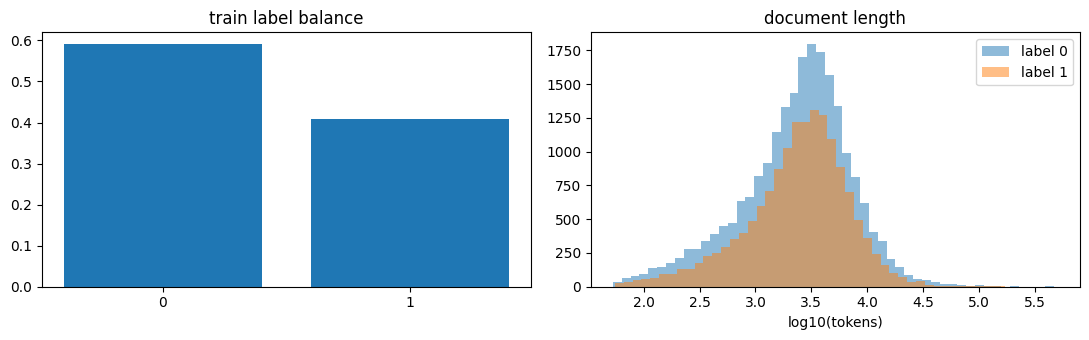

In [ ]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

def iter_json_list(path):
    try:
        import ijson
        with open(path, "rb") as f:
            for d in ijson.items(f, "item"): yield d
    except ImportError:                      # fallback: loads the whole file (several GB RAM)
        for d in json.load(open(path, encoding="utf-8")): yield d

KEEP_HEAD, KEEP_TAIL = 4096, 12288          # long docs: keep head + tail tokens (verdicts are at the end)
def _enc(text):
    ids = tokenizer.encode(clean_text(text)); n = len(ids)
    if n > KEEP_HEAD + KEEP_TAIL: ids = ids[:KEEP_HEAD] + ids[-KEEP_TAIL:]
    return np.asarray(ids, dtype=np.int32), n

def build_cache(split, fname, keep_tail_text=False):
    p = f"{CACHE}/{split}"
    if os.path.exists(p + "_off.npy"): return
    toks, off, orig, ys, ids, tails, buf = [], [0], [], [], [], [], []
    pool = mp.get_context("fork").Pool(max(1, (os.cpu_count() or 2) - 1))
    def flush():
        res = pool.map(_enc, [d["text"] for d in buf], chunksize=8)
        for d, (a, n) in zip(buf, res):
            toks.append(a); off.append(off[-1] + len(a)); orig.append(n); ids.append(str(d["id"]))
            ys.append(int(d["label"]) if d.get("label") is not None else -1)
            if keep_tail_text: tails.append(d["text"][-400:])
        buf.clear()
    for d in tqdm(iter_json_list(hf(f"{P4}/{fname}")), desc=split):
        buf.append(d)
        if len(buf) >= 2000: flush()
    if buf: flush()
    pool.close()
    np.save(p + "_tok.npy", np.concatenate(toks)); np.save(p + "_off.npy", np.array(off, np.int64))
    np.save(p + "_y.npy", np.array(ys, np.int8)); np.save(p + "_orig.npy", np.array(orig, np.int64))
    json.dump(ids, open(p + "_ids.json", "w"))
    if keep_tail_text: json.dump(tails, open(p + "_tails.json", "w"))

build_cache("train", "Train/train.json"); build_cache("dev", "Train/dev.json", keep_tail_text=True); build_cache("test", "Test/test.json")

class Split:
    def __init__(s, name):
        p = f"{CACHE}/{name}"; s.tok = np.load(p + "_tok.npy", mmap_mode="r"); s.off = np.load(p + "_off.npy")
        s.y = np.load(p + "_y.npy"); s.orig = np.load(p + "_orig.npy"); s.ids = json.load(open(p + "_ids.json")); s.n = len(s.ids)
        s.tails = json.load(open(p + "_tails.json")) if os.path.exists(p + "_tails.json") else None
    def doc(s, i): return s.tok[s.off[i]:s.off[i + 1]]
TRAIN, DEV, TEST = Split("train"), Split("dev"), Split("test")

# ---- EDA ----
print(pd.DataFrame([dict(split=n, docs=s.n, pos_frac=float((s.y == 1).mean()) if s.y[0] >= 0 else np.nan,
                         median_tokens=int(np.median(s.orig)), p90_tokens=int(np.percentile(s.orig, 90)),
                         frac_over_512=float((s.orig > 512).mean()), frac_over_4096=float((s.orig > 4096).mean()))
                    for n, s in [("train", TRAIN), ("dev", DEV), ("test", TEST)]]).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(["0", "1"], [(TRAIN.y == 0).mean(), (TRAIN.y == 1).mean()]); ax[0].set_title("train label balance")
for c in (0, 1): ax[1].hist(np.log10(TRAIN.orig[TRAIN.y == c] + 1), bins=50, alpha=.5, label=f"label {c}")
ax[1].set_xlabel("log10(tokens)"); ax[1].legend(); ax[1].set_title("document length"); plt.tight_layout(); plt.savefig(f"{WORK}/eda.png", dpi=150); plt.show()

In [ ]:
# kind=flat: one sequence per doc | kind=hier: K chunks per doc (cut from the END so the last chunk is full)
VIEWS = {
    "head512":    dict(kind="flat", L=512,  part="head", mbs=16),
    "tail512":    dict(kind="flat", L=512,  part="tail", mbs=16),
    "tail1024":   dict(kind="flat", L=1024, part="tail", mbs=8),
    "ht1024":     dict(kind="flat", L=1024, part="ht", head=256, mbs=8),     # first 256 + last 768 tokens
    "hier8":      dict(kind="hier", K=8, L=512, pick="ht",   mbs=2),         # first K/4 + last 3K/4 chunks
    "hier8_tail": dict(kind="hier", K=8, L=512, pick="tail", mbs=2),
    "hier8_even": dict(kind="hier", K=8, L=512, pick="even", mbs=2),
}
VIEWS.update({
    "hier4":      dict(kind="hier", K=4, L=256, pick="ht",   mbs=8),   # 1 head chunk + 3 tail chunks, 4x256 tokens
    "hier4_tail": dict(kind="hier", K=4, L=256, pick="tail", mbs=8),
})
def flat_seq(ids, v):
    L = v["L"] - 2
    if len(ids) <= L: seg = ids
    elif v["part"] == "head": seg = ids[:L]
    elif v["part"] == "tail": seg = ids[-L:]
    else: h = v["head"]; seg = np.concatenate([ids[:h], ids[-(L - h):]])
    return [BOS] + list(map(int, seg)) + [EOS]

def hier_chunks(ids, v):
    L, K, n = v["L"] - 2, v["K"], len(ids)
    chunks = [ids[max(0, e - L):e] for e in range(n, 0, -L)][::-1]
    nc = len(chunks)
    if nc > K:
        if v["pick"] == "tail": sel = range(nc - K, nc)
        elif v["pick"] == "ht": h = K // 4; sel = list(range(h)) + list(range(nc - (K - h), nc))
        else: sel = np.linspace(0, nc - 1, K).round().astype(int)
        chunks = [chunks[i] for i in sel]
    return [[BOS] + list(map(int, c)) + [EOS] for c in chunks]

class DocDS(torch.utils.data.Dataset):
    def __init__(s, sp, idx, v): s.sp, s.idx, s.v = sp, np.asarray(idx), v
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        j = int(s.idx[k]); ids = np.asarray(s.sp.doc(j))
        return j, (flat_seq(ids, s.v) if s.v["kind"] == "flat" else hier_chunks(ids, s.v)), int(s.sp.y[j])

def collate_fn(v):
    def f(items):
        B = len(items); js = [x[0] for x in items]; y = torch.tensor([x[2] for x in items])
        if v["kind"] == "flat":
            Lm = max(len(x[1]) for x in items); ids = torch.full((B, Lm), PAD, dtype=torch.long); lens = torch.zeros(B, dtype=torch.long)
            for b, x in enumerate(items): ids[b, :len(x[1])] = torch.tensor(x[1]); lens[b] = len(x[1])
            return dict(j=js, y=y, ids=ids, lens=lens)
        K = v["K"]; Lm = max(len(c) for x in items for c in x[1])
        ids = torch.full((B, K, Lm), PAD, dtype=torch.long); lens = torch.ones(B, K, dtype=torch.long); cm = torch.zeros(B, K, dtype=torch.bool)
        for b, x in enumerate(items):
            off = K - len(x[1])                                  # right-align: last chunk always at index K-1
            for q, c in enumerate(x[1]): ids[b, off + q, :len(c)] = torch.tensor(c); lens[b, off + q] = len(c); cm[b, off + q] = True
        return dict(j=js, y=y, ids=ids, lens=lens, cm=cm)
    return f
def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [ ]:
def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"])
    sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}

    vocab_size = cfg.get("vocab_size", cfg.get("VOCAB_SIZE", 24000))
    dim = cfg.get("dim", cfg.get("n_embd", cfg.get("N_EMBD", 768)))
    total_layers = cfg.get("layers", cfg.get("n_layer", cfg.get("N_LAYER", 8)))
    heads = cfg.get("heads", cfg.get("n_head", cfg.get("N_HEAD", 12)))
    block_size = cfg.get("block_size", cfg.get("BLOCK_SIZE", 1024))

    if layers_keep is not None:
        layers_keep = list(layers_keep)
        if not layers_keep or len(set(layers_keep)) != len(layers_keep):
            raise ValueError("layers_keep must be a non-empty sequence of unique layer indices")
        if any(not isinstance(i, int) or i < 0 or i >= total_layers for i in layers_keep):
            raise ValueError(f"layers_keep indices must be in [0, {total_layers - 1}]")

    n_layers = total_layers if layers_keep is None else len(layers_keep)
    lm = LegalLM(vocab_size=vocab_size, dim=dim, layers=n_layers,
                 heads=heads, block_size=block_size)

    if random_init:
        return lm

    if layers_keep is None:
        lm.load_state_dict(sd, strict=True)
    else:
        new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None:
                new[k] = v
            elif int(m.group(1)) in layers_keep:
                new[f"blocks.{layers_keep.index(int(m.group(1)))}.{m.group(2)}"] = v
        lm.load_state_dict(new, strict=True)
    return lm

import torch.utils.checkpoint as ckpt_util   # make sure this alias exists

class LMBackbone(nn.Module):
    def __init__(self, lm):
        super().__init__()
        self.wte    = lm.wte
        self.blocks = lm.blocks
        self.ln_f   = lm.ln_f
        self.dim    = lm.wte.embedding_dim
        self.n_frozen_prefix = 0

    def _run_block(self, block, x):
        """Always call Block the way Phase-1 defined it and extract the tensor."""
        out = block(x, mask=None, cache=None, start=0)
        return out[0] if isinstance(out, (tuple, list)) else out

    def hidden(self, x, gc=False):
        for i, block in enumerate(self.blocks):
            if i < self.n_frozen_prefix:
                with torch.no_grad():
                    x = self._run_block(block, x)
            elif gc and self.training and torch.is_grad_enabled():
                # Checkpoint receives a pure function that returns a Tensor only
                def run_block(t, blk=block):
                    return self._run_block(blk, t)
                x = ckpt_util.checkpoint(run_block, x, use_reentrant=False)
            else:
                x = self._run_block(block, x)

            assert torch.is_tensor(x), f"Block {i} produced {type(x)}"
        return self.ln_f(x)

# class LMBackbone(nn.Module):                     # interface for ANY Phase-1 arch: wte, blocks, ln_f, dim
#     def __init__(s, lm): super().__init__(); s.wte, s.blocks, s.ln_f, s.dim = lm.wte, lm.blocks, lm.ln_f, lm.cfg["dim"]
#     def hidden(s, x, gc=False):
#         for b in s.blocks:
#             x = ckpt_util.checkpoint(lambda t, b=b: b(t)[0], x, use_reentrant=False) if (gc and s.training and torch.is_grad_enabled()) else b(x)[0]
#         return s.ln_f(x)



class CJPEModel(nn.Module):
    """sequence/chunk -> pooled vector -> (hier: chunk-position emb + 1-layer transformer + attention pool) -> 2 logits"""
    def __init__(s, bb, view, pool="last_mean", drop=0.1):
        super().__init__(); s.bb, D = bb, bb.dim; s.pool, s.kind, s.gc = pool, view["kind"], False
        pd_ = 2 * D if pool == "last_mean" else D
        if pool == "attn": s.tatt = nn.Linear(D, 1)
        s.proj = nn.Sequential(nn.LayerNorm(pd_), nn.Dropout(drop), nn.Linear(pd_, D), nn.GELU())
        if s.kind == "hier":
            s.cpos = nn.Embedding(view["K"], D)
            nn.init.normal_(s.cpos.weight, std=0.02)
            nhead = next(h for h in (8, 4, 2, 1) if D % h == 0)
            s.denc = nn.TransformerEncoder(
                nn.TransformerEncoderLayer(
                    D, nhead, 2 * D, drop,
                    batch_first=True, norm_first=True, activation="gelu"
                ), 1
            )
            s.catt = nn.Linear(D, 1)
        s.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, 2)); s.ada = None
    def _pool(s, h, lens):
        m = torch.arange(h.size(1), device=h.device)[None] < lens[:, None]; last = h[torch.arange(len(lens)), lens - 1]
        if s.pool == "last": return last
        if s.pool == "attn":
            w = torch.softmax(s.tatt(h).squeeze(-1).float().masked_fill(~m, -1e4), -1); return (w[..., None] * h).sum(1)
        mean = (h * m[..., None]).sum(1) / lens[:, None]
        return mean if s.pool == "mean" else torch.cat([last, mean], -1)
    def seq_rep(s, ids, lens):
        h = s.bb.hidden(s.bb.wte(ids[:, :int(lens.max())]), s.gc).float(); return s.proj(s._pool(h, lens))
    def forward(s, b):
        if s.kind == "flat": z = s.seq_rep(b["ids"], b["lens"])
        else:
            cm = b["cm"]; B, K = cm.shape; zr = s.seq_rep(b["ids"][cm], b["lens"][cm])      # only real chunks are encoded
            z = zr.new_zeros(B, K, zr.size(-1)); z[cm] = zr
            z = s.denc(z + s.cpos.weight[None], src_key_padding_mask=~cm)
            w = torch.softmax(s.catt(z).squeeze(-1).float().masked_fill(~cm, -1e4), -1); z = (w[..., None] * z).sum(1)
        return s.cls(z), z

# ---------------- adapters ----------------
class LoRMALinear(nn.Module):                    # multiplicative low-rank:  W' = (I + B A) W  ->  y = h + B A h,  h = W x
    def __init__(s, base, r=16, alpha=16):
        super().__init__(); s.base = base
        s.A = nn.Parameter(torch.empty(r, base.out_features)); s.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(s.A, a=math.sqrt(5)); s.scale = alpha / r
    def forward(s, x): h = s.base(x); return h + F.linear(F.linear(h, s.A), s.B) * s.scale

class AdaLoRALinear(nn.Module):
    def __init__(s, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); s.base = base
        s.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); s.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        s.E = nn.Parameter(torch.zeros(r)); s.register_buffer("mask", torch.ones(r)); s.scale = alpha / r; s.drop = nn.Dropout(dropout)
    def forward(s, x): return s.base(x) + F.linear(F.linear(s.drop(x), s.A) * (s.E * s.mask).to(x.dtype), s.B) * s.scale
    def orth(s):
        I = torch.eye(s.E.numel(), device=s.A.device); return ((s.A @ s.A.t() - I) ** 2).sum() + ((s.B.t() @ s.B - I) ** 2).sum()

class AdaLoRAManager:                            # sensitivity-based rank pruning with a cubic budget schedule
    def __init__(s, model, total, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        s.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]; s.T, s.beta, s.ti, s.tf, s.dt = total, beta, ti, tf, dt
        s.b0 = sum(m.E.numel() for m in s.mods); s.bT = target_rank * len(s.mods); s.I, s.U = {}, {}
    def budget(s, t):
        ti, tf = int(s.ti * s.T), int(s.tf * s.T)
        if t < ti: return s.b0
        if t >= s.T - tf: return s.bT
        return int(s.bT + (s.b0 - s.bT) * (1 - (t - ti) / max(1, s.T - tf - ti)) ** 3)
    def orth_loss(s): return sum(m.orth() for m in s.mods)
    @torch.no_grad()
    def update(s, t):
        for k, m in enumerate(s.mods):
            if m.E.grad is None or m.A.grad is None: return
            sc = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in s.I: s.I[k], s.U[k] = sc.clone(), torch.zeros_like(sc)
            else: s.I[k] = s.beta * s.I[k] + (1 - s.beta) * sc; s.U[k] = s.beta * s.U[k] + (1 - s.beta) * (sc - s.I[k]).abs()
        if t % s.dt == 0 and len(s.I) == len(s.mods):
            sc = torch.cat([s.I[k] * s.U[k] for k in range(len(s.mods))]); mk = torch.zeros_like(sc); mk[sc.topk(min(s.budget(t), sc.numel())).indices] = 1; o = 0
            for m in s.mods: r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(s): return float(sum(m.mask.sum().item() for m in s.mods) / len(s.mods))

class BitFitLinear(nn.Module):                   # Phase-1 Linears are probably bias-free -> add zero-init trainable bias
    def __init__(s, base):
        super().__init__(); s.base = base; s.bias = nn.Parameter(torch.zeros(base.out_features))
        if base.bias is not None: s.bias.data.copy_(base.bias.data)
    def forward(s, x): return F.linear(x, s.base.weight) + s.bias.to(x.dtype)

class AdapterBlock(nn.Module):                   # serial bottleneck adapter after each transformer block (zero-init up-projection)
    def __init__(s, blk, D, r=64):
        super().__init__(); s.blk = blk; s.down, s.up = nn.Linear(D, r), nn.Linear(r, D); nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x, *a, **k):
        o = s.blk(x, *a, **k); y = o[0] if isinstance(o, tuple) else o; y = y + s.up(F.gelu(s.down(y)))
        return (y,) + tuple(o[1:]) if isinstance(o, tuple) else y

TARGETS = ("qkv", "proj", "w13", "w2")
def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            if isinstance(ch, nn.Linear) and (suffixes is None or any(full.endswith(s) for s in suffixes)): setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb; L = len(bb.blocks)
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m == "lorma": replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "bitfit":
        replace_linears(bb, None, lambda n, l: BitFitLinear(l))
        for mod in bb.modules():
            if type(mod).__name__.lower().endswith("norm"):
                for p in mod.parameters(): p.requires_grad = True
        for mod in bb.modules():
            if isinstance(mod, BitFitLinear): mod.bias.requires_grad = True
    elif m == "adapter":
        for i in range(L): bb.blocks[i] = AdapterBlock(bb.blocks[i], bb.dim, cfg.get("r_ad", 64))
    elif m == "partial":                         # layer freezing: only top-n blocks (+final norm) trainable; optional gradual unfreezing
        keep = L if cfg.get("gradual") else cfg["n_unfreeze"]
        for i, b in enumerate(bb.blocks):
            for p in b.parameters(): p.requires_grad = (i >= L - (1 if cfg.get("gradual") else keep))
        for p in bb.ln_f.parameters(): p.requires_grad = True
        if not cfg.get("gradual"): bb.n_frozen_prefix = L - cfg["n_unfreeze"]
    elif m == "linear_probe": bb.n_frozen_prefix = L
    elif m != "full": raise ValueError(m)

def unfreeze_upto(model, step, every):           # gradual unfreezing: one more layer (top-down) every `every` steps
    L = len(model.bb.blocks); k = min(L, 1 + step // every)
    for i, b in enumerate(model.bb.blocks):
        if i >= L - k:
            for p in b.parameters(): p.requires_grad = True

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    m = CJPEModel(bb, VIEWS[cfg["view"]], cfg["pool"]); m.gc = cfg.get("gc", False); apply_method(m, cfg); return m.to(DEVICE)

def model_stats(m):
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad); tot = sum(p.numel() for p in m.parameters())
    return tr, tot, sum(p.numel() * p.element_size() for p in m.parameters()) / 2**20

In [ ]:
RES_PATH = f"{WORK}/results.json"; RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def save_results(): json.dump(RESULTS, open(RES_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
def save_ckpt(path, st): torch.save(st, path + ".tmp"); os.replace(path + ".tmp", path)      # atomic: a killed session never leaves a corrupt file

def stratified_subset(sp, n, seed):
    if n is None or n >= sp.n: return np.arange(sp.n)
    rs = np.random.RandomState(seed); out = []
    for c in (0, 1):
        ix = np.where(sp.y == c)[0]; out.append(rs.choice(ix, min(len(ix), int(n * len(ix) / sp.n)), replace=False))
    return np.sort(np.concatenate(out))
SUB, DEV_SUB = stratified_subset(TRAIN, TRAIN_N, SEED), stratified_subset(DEV, DEV_FREQ_N, 1)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p))

@torch.no_grad()
def predict_logits(model, sp, idx, v, bs):
    model.eval(); idx = np.asarray(idx); o = np.argsort(sp.orig[idx])                    # length-sorted batches = less padding
    dl = torch.utils.data.DataLoader(DocDS(sp, idx[o], v), batch_size=bs, collate_fn=collate_fn(v), num_workers=NW)
    res = []
    for b in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): lg, _ = model(to_dev(b))
        res.append(lg.float().cpu().numpy())
    out = np.zeros((len(idx), 2), np.float32); out[o] = np.concatenate(res); return out

def best_bias(lg, y, grid=np.linspace(-3, 3, 121)):            # decision-threshold shift maximising macro-F1
    d = lg[:, 1] - lg[:, 0]; f = [f1_score(y, (d + g > 0).astype(int), average="macro", zero_division=0) for g in grid]; return float(grid[int(np.argmax(f))]), float(max(f))

def cls_loss(lg, y, kind, w):
    lg = lg.float()
    if kind == "focal": lpt = F.log_softmax(lg, -1).gather(1, y[:, None])[:, 0]; return (-(1 - lpt.exp()) ** 2 * lpt * w[y]).mean()
    return F.cross_entropy(lg, y, weight=w if kind == "wce" else None)

def param_groups(model, cfg):
    lr, bb = cfg["lr"], model.bb; L = len(bb.blocks); d = cfg.get("llrd"); gs = []
    bbp = [(n, p) for n, p in model.named_parameters() if n.startswith("bb.") and (p.requires_grad or cfg.get("gradual"))]
    if d:                                                                   # layer-wise LR decay (deeper = larger LR)
        for n, p in bbp:
            m = re.match(r"bb\.blocks\.(\d+)\.", n); depth = (L - 1 - int(m[1])) if m else (L if n.startswith("bb.wte") else 0)
            gs.append(dict(params=[p], lr=lr * d ** depth, base=lr * d ** depth))
    elif bbp: gs.append(dict(params=[p for _, p in bbp], lr=lr, base=lr))
    hp = [p for n, p in model.named_parameters() if not n.startswith("bb.") and p.requires_grad]
    gs.append(dict(params=hp, lr=cfg["head_lr"], base=cfg["head_lr"])); return [g for g in gs if g["params"]]

TEACHER_LOGITS = {}
def get_teacher_logits(tname):
    if tname in TEACHER_LOGITS: return TEACHER_LOGITS[tname]
    f = f"{CK}/{tname}_trainlogits.npy"
    if not os.path.exists(f):
        tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}_best.pt", map_location=DEVICE), strict=False)
        TL = np.full((TRAIN.n, 2), np.nan, np.float32); TL[SUB] = predict_logits(t, TRAIN, SUB, VIEWS[tc["view"]], VIEWS[tc["view"]]["mbs"] * 2)
        np.save(f, TL); del t; gc.collect(); torch.cuda.empty_cache()
    TEACHER_LOGITS[tname] = np.load(f); return TEACHER_LOGITS[tname]

def make_order(total, balanced, seed):
    rs = np.random.RandomState(seed); y = TRAIN.y[SUB]
    if balanced: p = np.where(y == 1, 0.5 / (y == 1).sum(), 0.5 / (y == 0).sum()); return rs.choice(SUB, total, p=p)
    out = []
    while sum(map(len, out)) < total: out.append(rs.permutation(SUB))
    return np.concatenate(out)[:total]

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | view={cfg['view']} | pool={cfg['pool']} | loss={cfg['loss']} ===")
    set_seed(cfg["seed"]); v = VIEWS[cfg["view"]]; mbs = v["mbs"]; accum = max(1, EFF_BS // mbs); total = cfg["steps"]
    if USE_AMP: torch.cuda.reset_peak_memory_stats()
    model = build_model(cfg); tr, tot, mb = model_stats(model); print(f"trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M")
    w = None
    if cfg["loss"] in ("wce", "focal"):
        c = np.bincount(TRAIN.y[SUB], minlength=2).astype(float); w = torch.tensor((c.sum() / (2 * c)) ** 0.5, dtype=torch.float32, device=DEVICE); w = w / w.mean()
    kd = cfg.get("kd"); TL = get_teacher_logits(kd["teacher"]) if kd else None
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    if cfg.get("gradual"): unfreeze_upto(model, 0, cfg["gradual"])
    opt = torch.optim.AdamW(param_groups(model, cfg), weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    warm = max(1, int(0.06 * total)); step, best, bad, hist, best_state, elapsed = 0, -1, 0, [], None, 0.0
    last = f"{CK}/{name}_last.pt"
    print(last)
    if os.path.exists(last):                                                                # ---- resume ----
        st = torch.load(last, map_location="cpu", weights_only=False); step = st["step"]
        if cfg.get("gradual"): unfreeze_upto(model, step, cfg["gradual"])
        model.load_state_dict(st["train"], strict=False); opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
        best, bad, hist, best_state, elapsed = st["best"], st["bad"], st["hist"], st["best_state"], st["elapsed"]
        if model.ada is not None and st.get("ada"): model.ada.I, model.ada.U = st["ada"]
        print(f"resumed from step {step}")
    def tracked(): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                           if k in {n for n, p in model.named_parameters() if p.requires_grad} or k.endswith(".mask")}
    def dump():
        save_ckpt(last, dict(step=step, train=tracked(), opt=opt.state_dict(), scaler=scaler.state_dict(), best=best, bad=bad, hist=hist,
                             best_state=best_state, elapsed=elapsed, ada=(model.ada.I, model.ada.U) if model.ada else None))
    order = make_order(total * EFF_BS, cfg.get("balanced", False), cfg["seed"])[step * EFF_BS:]
    dl = torch.utils.data.DataLoader(DocDS(TRAIN, order, v), batch_size=mbs, collate_fn=collate_fn(v), num_workers=NW, pin_memory=USE_AMP, prefetch_factor=4 if NW else None)
    it = iter(dl); t0 = time.time(); run_loss, nb = 0.0, 0; pbar = tqdm(total=total, initial=step, desc=name)
    while step < total:
        model.train()
        if cfg.get("gradual"): unfreeze_upto(model, step, cfg["gradual"])
        for _ in range(accum):
            b = to_dev(next(it))
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, _z = model(b); loss = cls_loss(lg, b["y"], cfg["loss"], w)
                if kd:
                    tl = torch.tensor(TL[b["j"]], device=DEVICE); T = kd["T"]
                    kdl = F.kl_div(F.log_softmax(lg.float() / T, -1), F.softmax(tl / T, -1), reduction="batchmean") * T * T
                    loss = kd["alpha"] * loss + (1 - kd["alpha"]) * kdl
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / accum).backward(); run_loss += loss.item(); nb += 1
        f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
        for g in opt.param_groups: g["lr"] = g["base"] * max(f, 0.02)
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 1.0)
        if model.ada is not None: model.ada.update(step)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1; pbar.update(1)
        pbar.set_postfix(loss=f"{run_loss/max(1,nb):.3f}")
        stop = False
        if step % cfg.get("eval_every", EVAL_EVERY) == 0 or step == total:
            m = metrics(DEV.y[DEV_SUB], predict_logits(model, DEV, DEV_SUB, v, mbs * 2).argmax(1))
            hist.append(dict(step=step, loss=run_loss / max(1, nb), **m)); run_loss, nb = 0.0, 0
            print(f" step {step}: dev-sub macro-F1 {m['f1']:.4f} P {m['P']:.3f} R {m['R']:.3f}")
            if m["f1"] > best: best, bad, best_state = m["f1"], 0, tracked()
            else:
                bad += 1; stop = bad >= PATIENCE
        capped = MAX_MIN_PER_RUN and (elapsed + time.time() - t0) / 60 > MAX_MIN_PER_RUN
        if step % CKPT_EVERY == 0 or stop or capped:
            elapsed += time.time() - t0; t0 = time.time(); dump()
        if stop or capped: print("early stop" if stop else "time cap reached"); break
    pbar.close(); elapsed += time.time() - t0
    if best_state is None: best_state = tracked()
    model.load_state_dict(best_state, strict=False); torch.save(best_state, f"{CK}/{name}_best.pt")

    # ---- final: full dev, test, latency, memory ----
    alld = np.arange(DEV.n); dl_ = predict_logits(model, DEV, alld, v, mbs * 2); ydev = DEV.y
    t1 = time.time(); predict_logits(model, DEV, alld[:300], v, mbs * 2); dps = 300 / (time.time() - t1)
    bias, f1_tuned = best_bias(dl_, ydev); tl_ = predict_logits(model, TEST, np.arange(TEST.n), v, mbs * 2)
    np.save(f"{PRED_DIR}/{name}_dev.npy", dl_); np.save(f"{PRED_DIR}/{name}_test.npy", tl_)
    json.dump([dict(id=i, pred=int(p)) for i, p in zip(TEST.ids, tl_.argmax(1))], open(f"{PRED_DIR}/{name}_test.json", "w"))
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=elapsed / 60, steps=step, hist=hist,
               dev=metrics(ydev, dl_.argmax(1)), f1=metrics(ydev, dl_.argmax(1))["f1"], f1_tuned=f1_tuned, bias=bias, docs_per_s=dps,
               peak_mem_mb=(torch.cuda.max_memory_allocated() / 2**20 if USE_AMP else 0))
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    RESULTS[name] = res; save_results()
    print(f"-> {name}: dev macro-F1 {res['f1']:.4f} (threshold-tuned {f1_tuned:.4f}) | {res['train_min']:.1f} min | {dps:.1f} docs/s | peak {res['peak_mem_mb']:.0f} MB")
    if os.path.exists(last): os.remove(last)
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return res

In [ ]:
def sec_per_step(cfg, n_micro=3):
    v = VIEWS[cfg["view"]]; mbs = v["mbs"]; accum = max(1, EFF_BS // mbs)
    model = build_model(cfg); model.train(); model.gc = cfg.get("gc", False)
    params = [p for p in model.parameters() if p.requires_grad]; opt = torch.optim.AdamW(params, lr=1e-6)
    dl = torch.utils.data.DataLoader(DocDS(TRAIN, SUB[:mbs * (n_micro + 1)], v), batch_size=mbs, collate_fn=collate_fn(v))
    ts = []
    for k, b in enumerate(dl):
        b = to_dev(b); torch.cuda.synchronize() if USE_AMP else None; t = time.time()
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): lg, _ = model(b); loss = F.cross_entropy(lg.float(), b["y"])
        loss.backward(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize() if USE_AMP else None
        if k > 0: ts.append(time.time() - t)                                      # first batch = warm-up
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return float(np.mean(ts)) * accum

def fit_steps(cfg, budget_min=TARGET_MIN, n_evals=4):
    sps = sec_per_step(cfg); fwd_doc = sps / EFF_BS / 3                          # forward-only cost per doc ~ 1/3 of fwd+bwd
    fixed = (n_evals * DEV_FREQ_N + DEV.n + TEST.n) * fwd_doc                    # in-training evals + final dev + test
    steps = int(max(60, min(MAX_STEPS, (budget_min * 60 - fixed) / sps)))
    print(f"{cfg['name']:18s} {sps:5.2f}s/step | eval overhead ~{fixed/60:4.1f} min | -> {steps} steps (~{(steps*sps+fixed)/60:.1f} min)")
    return steps

def common_steps(names):                                                         # same steps inside a group = fair comparison
    s = min(fit_steps(EXPS[n]) for n in names)
    for n in names: EXPS[n]["steps"] = s; EXPS[n]["eval_every"] = max(25, s // 4)
    return s

In [ ]:
BASE = dict(pool="last_mean", loss="wce", lr=5e-4, head_lr=1e-3,
            steps=MAX_STEPS, seed=SEED, balanced=False)

METHOD_HP = {
    "lorma": dict(r=16, alpha=16, lr=5e-4),
}

def E(name, group, method, view, **kw):
    c = dict(BASE)
    c.update(METHOD_HP.get(method, {}))
    c.update(
        name=name, group=group, method=method, view=view,
        gc=(VIEWS[view]["kind"] == "hier" or method == "full")
    )
    c.update(kw)
    return c

EXPS = {}

def reg(c):
    EXPS[c["name"]] = c
    return c

reg(E("v_ht1024", "view", "lorma", "ht1024"))

train_run(EXPS["v_ht1024"])

skip (done): v_ht1024


{'name': 'v_ht1024',
 'group': 'view',
 'cfg': {'pool': 'last_mean',
  'loss': 'wce',
  'lr': 0.0005,
  'head_lr': 0.001,
  'steps': 1000,
  'seed': 42,
  'balanced': False,
  'r': 16,
  'alpha': 16,
  'name': 'v_ht1024',
  'group': 'view',
  'method': 'lorma',
  'view': 'ht1024',
  'gc': False},
 'trainable': 3216642,
 'total': 78284802,
 'size_mb': 298.63282012939453,
 'train_min': 112.73807555834452,
 'steps': 1000,
 'hist': [{'step': 200,
   'loss': 0.6813880775123835,
   'f1': 0.5527445357428546,
   'P': 0.676171912674733,
   'R': 0.6006666666666667,
   'acc': 0.6006666666666667},
  {'step': 400,
   'loss': 0.5840199024230242,
   'f1': 0.6060734807017254,
   'P': 0.6342593435400775,
   'R': 0.618,
   'acc': 0.618},
  {'step': 600,
   'loss': 0.5758017487544567,
   'f1': 0.6102569073380748,
   'P': 0.6185543852643138,
   'R': 0.614,
   'acc': 0.614},
  {'step': 800,
   'loss': 0.5410064954031258,
   'f1': 0.6364907281791053,
   'P': 0.6369317665667398,
   'R': 0.6366666666666667,
 

In [ ]:

def results_df():
    rows = []
    for n, r in RESULTS.items():
        rows.append(dict(name=n, group=r["group"], method=r["cfg"]["method"], view=r["cfg"]["view"], loss=r["cfg"]["loss"], pool=r["cfg"]["pool"],
                         trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], docs_per_s=r["docs_per_s"],
                         peak_mem_MB=r["peak_mem_mb"], F1=r["f1"], P=r["dev"]["P"], R=r["dev"]["R"], acc=r["dev"]["acc"], F1_tuned=r["f1_tuned"]))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1"], ascending=[True, False]).round(4).to_string(index=False)); df.to_csv(f"{WORK}/summary.csv", index=False)


    name group method   view loss      pool  trainable_M  total_M  size_MB  train_min  docs_per_s  peak_mem_MB     F1     P      R    acc  F1_tuned
v_ht1024  view  lorma ht1024  wce last_mean       3.2166  78.2848 298.6328   112.7381     10.9283     7788.522 0.6503 0.652 0.6509 0.6509    0.6538


In [ ]:
# import os, zipfile, json, numpy as np

# def tune_threshold(probs, labels):
#     grid = np.arange(0.05, 0.96, 0.01)
#     f1s = [f1_score(labels, (probs >= t).astype(int), average="macro") for t in grid]
#     best = int(np.argmax(f1s))
#     return float(grid[best]), float(f1s[best])

# for exp_name, result in RESULTS.items():
#     if result is None:
#         continue

#     cfg = result["cfg"]
#     v = VIEWS[cfg["view"]]
#     mbs = v["mbs"]

#     # Build and load model
#     model = build_model(cfg)
#     model.load_state_dict(torch.load(f"{CK}/{exp_name}_best.pt", map_location=DEVICE), strict=False)
#     model.eval()

#     # Generate logits
#     dev_logits = predict_logits(model, DEV, np.arange(DEV.n), v, mbs * 2)
#     test_logits = predict_logits(model, TEST, np.arange(TEST.n), v, mbs * 2)

#     # Tune threshold
#     threshold, val_f1 = tune_threshold(dev_logits[:,1], DEV.y)
#     print(f"{exp_name}: tuned threshold={threshold:.3f}, dev macro-F1={val_f1:.4f}")

#     # Apply threshold
#     final_test_preds = (test_logits[:,1] >= threshold).astype(int)

#     # Save raw logits
#     np.save(f"{PRED_DIR}/{exp_name}_dev_tuned.npy", dev_logits)
#     np.save(f"{PRED_DIR}/{exp_name}_test_tuned.npy", test_logits)

#     # Prepare submission folder + JSON
#     sub_dir = os.path.join(PRED_DIR, f"submission_{exp_name}")
#     os.makedirs(sub_dir, exist_ok=True)
#     pred_path = os.path.join(sub_dir, "prediction.json")

#     with open(pred_path, "w") as f:
#         json.dump([{"id": str(i), "pred": int(p)} for i, p in zip(TEST.ids, final_test_preds)], f)

#     # Zip it (Changed arcname to "prediction.json" so it sits at the root of the archive)
#     zip_path = os.path.join(PRED_DIR, f"submission_{exp_name}.zip")
#     with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
#         zf.write(pred_path, arcname="prediction.json")

#     print(f"Zipped submission for {exp_name} → {zip_path}")

In [ ]:
RESULTS

{'v_ht1024': {'name': 'v_ht1024',
  'group': 'view',
  'cfg': {'pool': 'last_mean',
   'loss': 'wce',
   'lr': 0.0005,
   'head_lr': 0.001,
   'steps': 1000,
   'seed': 42,
   'balanced': False,
   'r': 16,
   'alpha': 16,
   'name': 'v_ht1024',
   'group': 'view',
   'method': 'lorma',
   'view': 'ht1024',
   'gc': False},
  'trainable': 3216642,
  'total': 78284802,
  'size_mb': 298.63282012939453,
  'train_min': 112.73807555834452,
  'steps': 1000,
  'hist': [{'step': 200,
    'loss': 0.6813880775123835,
    'f1': 0.5527445357428546,
    'P': 0.676171912674733,
    'R': 0.6006666666666667,
    'acc': 0.6006666666666667},
   {'step': 400,
    'loss': 0.5840199024230242,
    'f1': 0.6060734807017254,
    'P': 0.6342593435400775,
    'R': 0.618,
    'acc': 0.618},
   {'step': 600,
    'loss': 0.5758017487544567,
    'f1': 0.6102569073380748,
    'P': 0.6185543852643138,
    'R': 0.614,
    'acc': 0.614},
   {'step': 800,
    'loss': 0.5410064954031258,
    'f1': 0.6364907281791053,
   

In [ ]:
# # ═══ PHASE 4 – bundle everything (ckpts, results, probs, submissions) ═══
# P4_OUT = "/kaggle/working/phase4"
# P4_BUNDLE = f"{P4_OUT}/phase4_bundle.zip"
# with zipfile.ZipFile(P4_BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
#     for root, _, files in os.walk(P4_OUT):
#         for f in files:
#             if f == os.path.basename(P4_BUNDLE):
#                 continue
#             p = os.path.join(root, f)
#             z.write(p, arcname=os.path.relpath(p, P4_OUT))
# print(f"wrote {P4_BUNDLE} ({os.path.getsize(P4_BUNDLE)/2**30:.2f} GB)")

---
## Architecture: `mla_moe`

Source: `cs781-legal-lm-v3-mla-moe.ipynb`


In [ ]:
# ── Activate backbone: mla_moe ──────────────────────────────────────────────
BACKBONE = "mla_moe"
TOKENIZER_PATH = TOK_PATHS["mla_moe"]
PHASE1_CKPT = CKPTS["mla_moe"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")


[active] BACKBONE=mla_moe
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_mla_moe.json  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/latest_checkpoint_mla_moe_1k.pt  exists=True


### Phase-1 classes for `mla_moe` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


## 1. Text cleaning + byte-level BPE tokenizer

In [ ]:
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    """Light, conservative normalisation of legal text (used for training data AND test prompts)."""
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)                 # de-hyphenate line-wrapped words
    t = _DOTS.sub("...", t)              # ".........." table-of-contents leaders
    t = _RULE.sub(" ", t)                # ------ / ====== separators
    t = _PAGE.sub("", t)                 # lines that are only a page number
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)                # join hard-wrapped lines inside a sentence
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def keep_doc(c):
    """Quality filter for cleaned documents."""
    if len(c) < 600: return False
    head = c[:5000]
    if sum(ch.isalpha() for ch in head) / len(head) < 0.6: return False
    if sum(ord(ch) > 127 for ch in head) / len(head) > 0.2: return False   # mostly non-English OCR/Indic
    w = c.split()
    if len(w) < 100: return False
    w = w[:3000]
    return len(set(w)) / len(w) >= 0.15                                       # drop repetitive junk

def extract_text(rec):
    if isinstance(rec, str): return rec
    if isinstance(rec, dict):
        for k in ("text", "train_text", "content", "body", "judgment", "document"):
            v = rec.get(k)
            if isinstance(v, str) and v.strip(): return v
        for v in rec.values():
            if isinstance(v, (dict, list)):
                s = extract_text(v)
                if s: return s
    if isinstance(rec, list):
        return "\n".join(filter(None, map(extract_text, rec)))
    return ""

def iter_docs(path):
    """Constant-memory iteration over a huge JSON file ({id: record} or [record, ...])."""
    with open(path, "rb") as f:
        head = f.read(256).lstrip(b"\xef\xbb\xbf \n\r\t")[:1]
        f.seek(0)
        it = (v for _, v in ijson.kvitems(f, "")) if head == b"{" else ijson.items(f, "item")
        for rec in it:
            t = extract_text(rec)
            if t: yield t


class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    # GPT-2 style: a leading space stays attached to the word, so "the" / " the" are one token each
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def train(self, texts, max_unique_words=200_000, min_freq=2):
        counts = Counter()
        for t in tqdm(texts, desc="counting pre-tokens"):
            counts.update(self._split.findall(t))
        if len(counts) > max_unique_words:
            counts = Counter(dict(counts.most_common(max_unique_words)))
        words, freqs = [], []
        pair_counts, pair_words = defaultdict(int), defaultdict(set)
        for wid, (w, c) in enumerate(counts.items()):
            toks = [bytes([b]) for b in w.encode("utf-8")]
            words.append(toks); freqs.append(c)
            for p in zip(toks, toks[1:]):
                pair_counts[p] += c; pair_words[p].add(wid)
        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)
        self.merges = []
        n_target = self.vocab_size - (4 + 256)
        seen = set(bytes([i]) for i in range(256))
        pbar = tqdm(total=n_target, desc="BPE merges")
        while len(self.merges) < n_target and heap:
            best = None
            while heap:                                  # lazy-deletion max-heap
                negc, p = heapq.heappop(heap)
                cur = pair_counts.get(p, 0)
                if cur <= 0: continue
                if cur != -negc:
                    heapq.heappush(heap, (-cur, p)); continue
                best = p; break
            if best is None or pair_counts[best] < min_freq: break
            a, b = best; merged = a + b
            self.merges.append(best); seen.add(merged)
            for wid in list(pair_words.pop(best, ())):
                w, f = words[wid], freqs[wid]
                new, i = [], 0
                while i < len(w):
                    if i < len(w) - 1 and w[i] == a and w[i + 1] == b:
                        new.append(merged); i += 2
                    else:
                        new.append(w[i]); i += 1
                if len(new) == len(w): continue
                for p in zip(w, w[1:]): pair_counts[p] -= f
                for p in zip(new, new[1:]):
                    pair_counts[p] += f; pair_words[p].add(wid)
                    heapq.heappush(heap, (-pair_counts[p], p))
                words[wid] = new
            pbar.update(1)
        pbar.close()
        self._build()
        return self

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi[t] for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = [self.bos_id] if add_bos else []
        for ch in self._split.findall(text): ids.extend(self._word(ch))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        return b"".join(self.itos[i] for i in ids if 4 <= i < len(self.itos)).decode("utf-8", errors="replace")

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"vocab_size": self.vocab_size, "merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        d = json.load(open(path))
        t = cls(d["vocab_size"]); t.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in d["merges"]]
        t._build(); return t


# keep global `tokenizer` pointing at the BACKBONE selected in the config cell
tokenizer = BPETokenizer.load("/kaggle/working/cs781_phase1/legal_bpe_mla_moe.json")
print(f"Active tokenizer for BACKBONE={BACKBONE}: vocab={tokenizer.vocab_size}")


Active tokenizer for BACKBONE=mla_moe: vocab=30000


## 4. Model: MLA attention (with weight absorption at inference) + DeepSeekMoE feed-forward
* **MLA**: keys/values are compressed into a small latent `c_kv` (+ a tiny decoupled RoPE key). Training uses the
  expanded form; inference uses the *absorbed* form: `W_UK` is folded into the query and `W_UV` into the output,
  so attention runs directly on the cached latent (cache = d_c + d_rope numbers per token instead of 2*heads*head_dim).
* **MoE**: 1 shared expert + routed experts (top-k). Experts are split into one group per data source; during training the
  router gets a small supervised "domain" loss so each group specialises (Acts / Supreme Court / High Courts / Tribunals).
  At inference there are no labels - the router infers the domain from the prompt text.

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.w).type_as(x)

class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False)
        self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos, sin = self.cos[start:start + t].to(x.dtype), self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)


class MLA(nn.Module):
    """Multi-head Latent Attention (DeepSeek-V2/V3) with decoupled RoPE and weight absorption for inference."""
    def __init__(self, c):
        super().__init__()
        dim, H = c["dim"], c["heads"]
        self.h, self.dc, self.dn, self.dr, self.dv = H, c["d_c"], c["d_nope"], c["d_rope"], c["d_v"]
        self.dq = nn.Linear(dim, c["d_cq"], bias=False);  self.q_norm = RMSNorm(c["d_cq"])
        self.uq = nn.Linear(c["d_cq"], H * (self.dn + self.dr), bias=False)           # -> [q_nope | q_rope] per head
        self.dkv = nn.Linear(dim, self.dc + self.dr, bias=False); self.kv_norm = RMSNorm(self.dc)   # -> [c_kv | k_rope]
        self.uk = nn.Linear(self.dc, H * self.dn, bias=False)                          # W_UK
        self.uv = nn.Linear(self.dc, H * self.dv, bias=False)                          # W_UV
        self.o = nn.Linear(H * self.dv, dim, bias=False)
        self.rope = RoPE(self.dr, c["block_size"])
        self.scale = 1.0 / math.sqrt(self.dn + self.dr)

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.uq(self.q_norm(self.dq(x))).reshape(b, t, self.h, self.dn + self.dr).transpose(1, 2)
        q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
        ckv, k_rope = self.dkv(x).split([self.dc, self.dr], dim=-1)
        ckv = self.kv_norm(ckv)                                                       # (b, t, dc)  <- this is what is cached
        q_rope = self.rope(q_rope, start)
        k_rope = self.rope(k_rope.unsqueeze(1), start)                                # (b, 1, t, dr) shared by all heads

        if cache is None:                                                             # ---- training: expanded form
            k_nope = self.uk(ckv).reshape(b, t, self.h, self.dn).transpose(1, 2)
            v = self.uv(ckv).reshape(b, t, self.h, self.dv).transpose(1, 2)
            qf = torch.cat([q_nope, q_rope], -1)
            kf = torch.cat([k_nope, k_rope.expand(-1, self.h, -1, -1)], -1)
            y = F.scaled_dot_product_attention(qf, kf, v, is_causal=True)             # default scale = 1/sqrt(dn+dr)
            return self.o(y.transpose(1, 2).reshape(b, t, self.h * self.dv)), None

        # ---- inference: ABSORBED form, attention runs in latent space on the compressed cache
        r = k_rope.squeeze(1)
        if cache[0] is not None:
            ckv, r = torch.cat([cache[0], ckv], 1), torch.cat([cache[1], r], 1)
        new_cache = (ckv, r)
        Wuk = self.uk.weight.reshape(self.h, self.dn, self.dc)
        q_abs = torch.einsum("bhtn,hnc->bhtc", q_nope, Wuk.to(q_nope.dtype))          # q_nope @ W_UK  (absorb W_UK into q)
        qq = torch.cat([q_abs, q_rope], -1)                                           # (b, H, t, dc+dr)
        kk = torch.cat([ckv, r], -1).to(qq.dtype)[:, None].expand(-1, self.h, -1, -1) # (b, H, T, dc+dr)  (MQA-like, shared)
        vv = ckv.to(qq.dtype)[:, None].expand(-1, self.h, -1, -1)                     # values ARE the latent
        if mask is not None:  ctx = F.scaled_dot_product_attention(qq, kk, vv, attn_mask=mask, scale=self.scale)
        elif t > 1:           ctx = F.scaled_dot_product_attention(qq, kk, vv, is_causal=True, scale=self.scale)
        else:                 ctx = F.scaled_dot_product_attention(qq, kk, vv, scale=self.scale)
        Wuv = self.uv.weight.reshape(self.h, self.dv, self.dc)
        out = torch.einsum("bhtc,hvc->bthv", ctx, Wuv.to(ctx.dtype)).reshape(b, t, self.h * self.dv)   # absorb W_UV after attention
        return self.o(out), new_cache


class FFN(nn.Module):
    def __init__(self, dim, hid):
        super().__init__()
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)


class MoE(nn.Module):
    """DeepSeekMoE-style: shared expert(s) + top-k routed experts. Routed experts are grouped per domain."""
    def __init__(self, c):
        super().__init__()
        dim, self.n, self.k, self.D = c["dim"], c["n_routed"], c["topk_experts"], c["n_domains"]
        assert self.n % self.D == 0, "n_routed must be a multiple of n_domains"
        self.router = nn.Linear(dim, self.n, bias=False)
        self.experts = nn.ModuleList([FFN(dim, c["expert_hid"]) for _ in range(self.n)])
        self.shared = FFN(dim, c["shared_hid"])

    def forward(self, x, domain=None):
        b, t, d = x.shape
        xf = x.reshape(-1, d); N = xf.size(0)
        probs = self.router(xf).float().softmax(-1)                                   # (N, n_routed)
        topv, topi = probs.topk(self.k, dim=-1)
        topv = topv / topv.sum(-1, keepdim=True)
        flat_e = topi.reshape(-1)
        order = flat_e.argsort()
        tok = order // self.k                                                         # token index for each (sorted) assignment
        w = topv.reshape(-1)[order]
        counts = torch.bincount(flat_e, minlength=self.n)
        xs, outs, pos = xf[tok], [], 0
        for e, cnt in enumerate(counts.tolist()):
            if cnt:
                outs.append(self.experts[e](xs[pos:pos + cnt])); pos += cnt
        ys = torch.cat(outs, 0)
        routed = torch.zeros(N, d, dtype=ys.dtype, device=x.device).index_add_(0, tok, ys * w[:, None].to(ys.dtype))
        y = (self.shared(xf) + routed).reshape(b, t, d)

        z = probs.new_zeros(())
        bal, dom, acc = z, z, z
        if self.training:                                                             # switch-style load balancing
            f = counts.float() / (N * self.k)
            bal = self.n * (f * probs.mean(0)).sum()
        if domain is not None:                                                        # domain-guided routing
            g = probs.reshape(N, self.D, self.n // self.D).sum(-1)                       # router mass per expert group
            dt = domain[:, None].expand(b, t).reshape(-1)
            dom = -g.gather(1, dt[:, None]).clamp_min(1e-9).log().mean()
            acc = (g.argmax(-1) == dt).float().mean()
        return y, torch.stack([bal, dom, acc])


class Block(nn.Module):
    def __init__(self, c, dense):
        super().__init__()
        self.n1, self.n2, self.dense = RMSNorm(c["dim"]), RMSNorm(c["dim"]), dense
        self.attn = MLA(c)
        self.ffn = FFN(c["dim"], c["dense_hid"]) if dense else MoE(c)
    def forward(self, x, mask=None, cache=None, start=0, domain=None):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        if self.dense:
            return x + self.ffn(self.n2(x)), cache, x.new_zeros(3, dtype=torch.float32)
        y, aux = self.ffn(self.n2(x), domain)
        return x + y, cache, aux


class LegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg, self.block_size = cfg, cfg["block_size"]
        self.wte = nn.Embedding(cfg["vocab_size"], cfg["dim"])
        self.blocks = nn.ModuleList([Block(cfg, i < cfg["dense_first"]) for i in range(cfg["layers"])])
        self.n_moe = max(1, cfg["layers"] - cfg["dense_first"])
        self.ln_f = RMSNorm(cfg["dim"])
        self.lm_head = nn.Linear(cfg["dim"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.wte.weight                                          # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():
            if n.endswith("attn.o.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg["layers"]))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, domain=None):
        """Returns logits, CE loss (or None) and aux = mean over MoE layers of [balance_loss, domain_loss, routing_acc]."""
        x, aux = self.wte(idx), 0.0
        for blk in self.blocks:
            if self.training and USE_GRAD_CKPT:
                x, a = torch.utils.checkpoint.checkpoint(lambda t, b=blk: b(t, domain=domain)[0::2], x, use_reentrant=False)
            else:
                x, _, a = blk(x, domain=domain)
            aux = aux + a
        logits = self.lm_head(self.ln_f(x))
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        return logits, loss, aux / self.n_moe

    def step(self, idx, caches, start, mask):
        """Inference step on the compressed MLA cache. Returns logits of the LAST position and the new caches."""
        x = self.wte(idx); new = []
        for blk, c in zip(self.blocks, caches):
            x, c, _ = blk(x, mask, c, start); new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def make_cfg(vocab_size):
    return dict(vocab_size=vocab_size, dim=N_EMBD, layers=N_LAYER, heads=N_HEAD, block_size=BLOCK_SIZE,
                d_c=D_C, d_cq=D_CQ, d_nope=D_NOPE, d_rope=D_ROPE, d_v=D_V,
                n_routed=N_ROUTED, topk_experts=TOPK_EXPERTS, expert_hid=EXPERT_HID, shared_hid=SHARED_HID,
                dense_hid=DENSE_HID, n_domains=N_DOMAINS, dense_first=DENSE_FIRST)

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    routed = sum(p.numel() for n, p in m.named_parameters() if ".experts." in n)
    c = m.cfg
    return total, total - routed * (1 - c["topk_experts"] / c["n_routed"])


@torch.inference_mode()
def generate_batch(model, tok, prompts, max_new, temperature, top_p, top_k, rep_pen, target_words):
    """Batched sampling with left-padding on the MLA latent cache. Returns a list of generated id-lists."""
    model.eval()
    dev = next(model.parameters()).device
    b, L = len(prompts), max(len(p) for p in prompts)
    assert L + max_new <= model.block_size, "prompt too long for the context window"
    idx = torch.full((b, L), tok.pad_id, dtype=torch.long)
    valid = torch.zeros(b, L, dtype=torch.bool)
    for i, p in enumerate(prompts):
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(dev), valid.to(dev)
    causal = torch.ones(L, L, dtype=torch.bool, device=dev).tril()
    eye = torch.eye(L, dtype=torch.bool, device=dev)
    mask = causal[None, None] & (valid[:, None, None, :] | eye[None, None])   # pad rows attend to themselves (no NaN)
    V = len(tok.itos)
    print("Vocab: ", V)
    seen = torch.zeros(b, V, dtype=torch.bool, device=dev)
    gen = []
    with torch.autocast(device_type=dev.type, dtype=AMP_DTYPE, enabled=dev.type == "cuda"):
        logits, caches = model.step(idx, [(None, None)] * len(model.blocks), 0, mask)
        for n in range(max_new):
            lg = logits.float()
            lg[:, [tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id]] = float("-inf")   # always keep writing text
            if rep_pen != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_pen, lg * rep_pen), lg)
            lg = lg / max(temperature, 1e-5)
            if top_k:
                kth = lg.topk(min(top_k, V), dim=-1).values[:, -1:]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                sl, si = lg.sort(descending=True)
                cp = sl.softmax(-1).cumsum(-1)
                rm = cp - sl.softmax(-1) > top_p
                lg = lg.masked_fill(rm.scatter(1, si, rm), float("-inf"))
            nxt = torch.multinomial(lg.softmax(-1), 1)
            gen.append(nxt); seen.scatter_(1, nxt, True)
            valid = torch.cat([valid, torch.ones(b, 1, dtype=torch.bool, device=dev)], 1)
            if (n + 1) % 32 == 0:
                g = torch.cat(gen, 1).tolist()
                if all(len(tok.decode(r).split()) >= target_words + 8 for r in g): break
            if n + 1 < max_new:
                logits, caches = model.step(nxt, caches, L + n, valid[:, None, None, :])
    return torch.cat(gen, 1).tolist()

## 6. Generation: exactly 128 words per prompt

In [ ]:
def load_model(path=MODEL_PATH):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = LegalLM(ck["config"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()
samples = ["The respondent submits that the appeal should be dismissed.",
           "Section 302 of the Indian Penal Code shall apply.",
           "The Court, having considered the evidence, hereby orders"]
for p, o in zip(samples, continue_texts(model, samples, progress=False)):
    print(f"PROMPT: {p}\n -> [{len(o.split())} words] {o}\n")

Vocab:  30000
PROMPT: The respondent submits that the appeal should be dismissed.
 -> [128 words] The petitioner will not be entitled to get the bail application. With the aforesaid, this appeal is dismissed as withdrawn with a liberty to the petitioner to file fresh revision petition before the court below within a period of six weeks from today. The writ petition stands disposed of accordingly. No costs. A copy of this order be supplied to the parties on proper application. K.P.M.S.C.,J. (Rajiv Sharma), Judge. Interim order dated 05.06.2008 passed by learned District Judge-cum-Special Judge, South Tripura in Criminal Appeal No. 9/2003 has been set aside and the same has been preferred. Accordingly, the appeal stands disposed of. All these appeals are disposed of accordingly. Issue urgent certified copy as per rules. S.P. Singh-I, J. A copy of this order be granted on proper

PROMPT: Section 302 of the Indian Penal Code shall apply.
 -> [128 words] Chapter VII Offences Of The Indian P

## 7. Predict on the test set -> prediction.json + submission.zip

In [ ]:
def load_model(path=MODEL_PATH):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = LegalLM(ck["config"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    # max_prompt_len = max(len(p) for p in prompts)
    # safe_max_new = min(MAX_NEW_TOKENS, model.block_size - max_prompt_len)
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()

In [ ]:
# Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
if os.path.exists(TOKENIZER_PATH):
    try:
        tokenizer = BPETokenizer.load(TOKENIZER_PATH)
        print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
    except Exception as e:
        print("Tokenizer load failed:", e)
else:
    print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


Loaded tokenizer vocab=30000 from /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json


### Phase content (`p4`) – cells [72:91] from source


# Phase 4

In [ ]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile
import multiprocessing as mp
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED, HF_REPO, P4 = 42, "Exploration-Lab/CS-781-Capstone", "Phase_4_CJPE"
ARCH = "arch1"                                   # change per Phase-1 architecture (arch1..arch4): separate ckpts/results
KAGGLE = os.path.isdir("/kaggle/working")
BASE_WORK = "/kaggle/working/phase4-mla-moe" if KAGGLE else "./phase4-mla-moe"
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
# TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
# PHASE1_CKPT = f"{PHASE1_DIR}/legal_lm_v3.pt"
WORK = f"{BASE_WORK}/{ARCH}"; CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/preds"
CACHE = f"{BASE_WORK}/cache/"      # token cache shared by archs with the same tokenizer
for d in (WORK, CK, PRED_DIR, CACHE): os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient; HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception: HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(token=HF_TOKEN)

# ---------------- compute / time knobs ----------------
TRAIN_N      = None    # docs sampled (stratified) from train, same subset for every run; None = all
DEV_FREQ_N   = 1500     # dev docs used for the in-training evaluations
MAX_STEPS    = 1000     # optimiser steps per run
EFF_BS       = 32       # docs per optimiser step (micro-batch x accumulation)
EVAL_EVERY   = 200      # steps between dev-subset evals (best state kept)
CKPT_EVERY   = 50       # steps between resumable checkpoints
PATIENCE     = 3        # evals without improvement before early stop
MAX_MIN_PER_RUN = None  # optional wall-clock cap per session (minutes); re-run resumes
NW = 2                  # dataloader workers

TARGET_MIN   = 80      # wall-clock budget per run, including evals

In [ ]:
tokenizer = BPETokenizer.load(TOKENIZER_PATH); BOS, EOS, PAD = tokenizer.bos_id, tokenizer.eos_id, tokenizer.pad_id

   split   docs  pos_frac  median_tokens  p90_tokens  frac_over_512  frac_over_4096
0  train  37387     0.410           2668        7985          0.897           0.306
1    dev   1988     0.500           3475        8332          0.991           0.400
2   test   1517     0.502           3597        8666          0.987           0.413


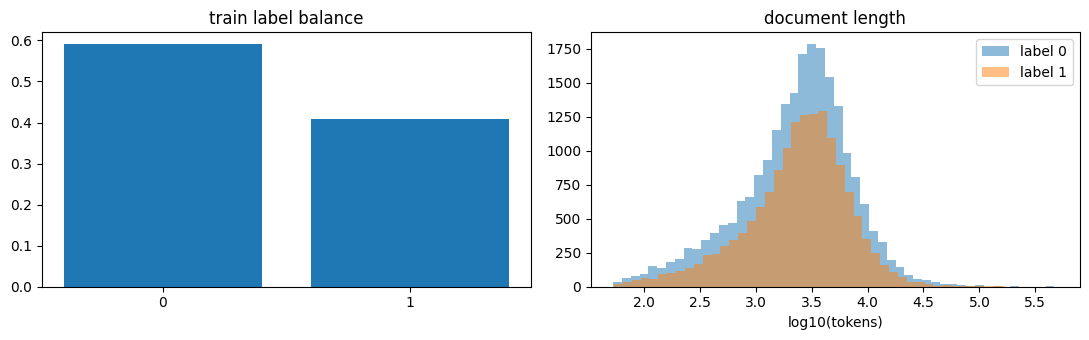

In [ ]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

def iter_json_list(path):
    try:
        import ijson
        with open(path, "rb") as f:
            for d in ijson.items(f, "item"): yield d
    except ImportError:                      # fallback: loads the whole file (several GB RAM)
        for d in json.load(open(path, encoding="utf-8")): yield d

KEEP_HEAD, KEEP_TAIL = 4096, 12288          # long docs: keep head + tail tokens (verdicts are at the end)
def _enc(text):
    ids = tokenizer.encode(clean_text(text)); n = len(ids)
    if n > KEEP_HEAD + KEEP_TAIL: ids = ids[:KEEP_HEAD] + ids[-KEEP_TAIL:]
    return np.asarray(ids, dtype=np.int32), n

def build_cache(split, fname, keep_tail_text=False):
    p = f"{CACHE}/{split}"
    if os.path.exists(p + "_off.npy"): return
    toks, off, orig, ys, ids, tails, buf = [], [0], [], [], [], [], []
    pool = mp.get_context("fork").Pool(max(1, (os.cpu_count() or 2) - 1))
    def flush():
        res = pool.map(_enc, [d["text"] for d in buf], chunksize=8)
        for d, (a, n) in zip(buf, res):
            toks.append(a); off.append(off[-1] + len(a)); orig.append(n); ids.append(str(d["id"]))
            ys.append(int(d["label"]) if d.get("label") is not None else -1)
            if keep_tail_text: tails.append(d["text"][-400:])
        buf.clear()
    for d in tqdm(iter_json_list(hf(f"{P4}/{fname}")), desc=split):
        buf.append(d)
        if len(buf) >= 2000: flush()
    if buf: flush()
    pool.close()
    np.save(p + "_tok.npy", np.concatenate(toks)); np.save(p + "_off.npy", np.array(off, np.int64))
    np.save(p + "_y.npy", np.array(ys, np.int8)); np.save(p + "_orig.npy", np.array(orig, np.int64))
    json.dump(ids, open(p + "_ids.json", "w"))
    if keep_tail_text: json.dump(tails, open(p + "_tails.json", "w"))

build_cache("train", "Train/train.json"); build_cache("dev", "Train/dev.json", keep_tail_text=True); build_cache("test", "Test/test.json")

class Split:
    def __init__(s, name):
        p = f"{CACHE}/{name}"; s.tok = np.load(p + "_tok.npy", mmap_mode="r"); s.off = np.load(p + "_off.npy")
        s.y = np.load(p + "_y.npy"); s.orig = np.load(p + "_orig.npy"); s.ids = json.load(open(p + "_ids.json")); s.n = len(s.ids)
        s.tails = json.load(open(p + "_tails.json")) if os.path.exists(p + "_tails.json") else None
    def doc(s, i): return s.tok[s.off[i]:s.off[i + 1]]
TRAIN, DEV, TEST = Split("train"), Split("dev"), Split("test")

# ---- EDA ----
print(pd.DataFrame([dict(split=n, docs=s.n, pos_frac=float((s.y == 1).mean()) if s.y[0] >= 0 else np.nan,
                         median_tokens=int(np.median(s.orig)), p90_tokens=int(np.percentile(s.orig, 90)),
                         frac_over_512=float((s.orig > 512).mean()), frac_over_4096=float((s.orig > 4096).mean()))
                    for n, s in [("train", TRAIN), ("dev", DEV), ("test", TEST)]]).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(["0", "1"], [(TRAIN.y == 0).mean(), (TRAIN.y == 1).mean()]); ax[0].set_title("train label balance")
for c in (0, 1): ax[1].hist(np.log10(TRAIN.orig[TRAIN.y == c] + 1), bins=50, alpha=.5, label=f"label {c}")
ax[1].set_xlabel("log10(tokens)"); ax[1].legend(); ax[1].set_title("document length"); plt.tight_layout(); plt.savefig(f"{WORK}/eda.png", dpi=150); plt.show()

In [ ]:
# kind=flat: one sequence per doc | kind=hier: K chunks per doc (cut from the END so the last chunk is full)
VIEWS = {
    "head512":    dict(kind="flat", L=512,  part="head", mbs=16),
    "tail512":    dict(kind="flat", L=512,  part="tail", mbs=16),
    "tail1024":   dict(kind="flat", L=1024, part="tail", mbs=8),
    "ht1024":     dict(kind="flat", L=1024, part="ht", head=256, mbs=8),     # first 256 + last 768 tokens
    "hier8":      dict(kind="hier", K=8, L=512, pick="ht",   mbs=2),         # first K/4 + last 3K/4 chunks
    "hier8_tail": dict(kind="hier", K=8, L=512, pick="tail", mbs=2),
    "hier8_even": dict(kind="hier", K=8, L=512, pick="even", mbs=2),
}
VIEWS.update({
    "hier4":      dict(kind="hier", K=4, L=256, pick="ht",   mbs=8),   # 1 head chunk + 3 tail chunks, 4x256 tokens
    "hier4_tail": dict(kind="hier", K=4, L=256, pick="tail", mbs=8),
})
def flat_seq(ids, v):
    L = v["L"] - 2
    if len(ids) <= L: seg = ids
    elif v["part"] == "head": seg = ids[:L]
    elif v["part"] == "tail": seg = ids[-L:]
    else: h = v["head"]; seg = np.concatenate([ids[:h], ids[-(L - h):]])
    return [BOS] + list(map(int, seg)) + [EOS]

def hier_chunks(ids, v):
    L, K, n = v["L"] - 2, v["K"], len(ids)
    chunks = [ids[max(0, e - L):e] for e in range(n, 0, -L)][::-1]
    nc = len(chunks)
    if nc > K:
        if v["pick"] == "tail": sel = range(nc - K, nc)
        elif v["pick"] == "ht": h = K // 4; sel = list(range(h)) + list(range(nc - (K - h), nc))
        else: sel = np.linspace(0, nc - 1, K).round().astype(int)
        chunks = [chunks[i] for i in sel]
    return [[BOS] + list(map(int, c)) + [EOS] for c in chunks]

class DocDS(torch.utils.data.Dataset):
    def __init__(s, sp, idx, v): s.sp, s.idx, s.v = sp, np.asarray(idx), v
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        j = int(s.idx[k]); ids = np.asarray(s.sp.doc(j))
        return j, (flat_seq(ids, s.v) if s.v["kind"] == "flat" else hier_chunks(ids, s.v)), int(s.sp.y[j])

def collate_fn(v):
    def f(items):
        B = len(items); js = [x[0] for x in items]; y = torch.tensor([x[2] for x in items])
        if v["kind"] == "flat":
            Lm = max(len(x[1]) for x in items); ids = torch.full((B, Lm), PAD, dtype=torch.long); lens = torch.zeros(B, dtype=torch.long)
            for b, x in enumerate(items): ids[b, :len(x[1])] = torch.tensor(x[1]); lens[b] = len(x[1])
            return dict(j=js, y=y, ids=ids, lens=lens)
        K = v["K"]; Lm = max(len(c) for x in items for c in x[1])
        ids = torch.full((B, K, Lm), PAD, dtype=torch.long); lens = torch.ones(B, K, dtype=torch.long); cm = torch.zeros(B, K, dtype=torch.bool)
        for b, x in enumerate(items):
            off = K - len(x[1])                                  # right-align: last chunk always at index K-1
            for q, c in enumerate(x[1]): ids[b, off + q, :len(c)] = torch.tensor(c); lens[b, off + q] = len(c); cm[b, off + q] = True
        return dict(j=js, y=y, ids=ids, lens=lens, cm=cm)
    return f
def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [ ]:
def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"]); sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}
    if layers_keep is None:
        lm = LegalLM(cfg)
        if not random_init: lm.load_state_dict(sd)
    else:                                                      # student: subset of Phase-1 layers, initialised from their weights
        lm = LegalLM(dict(cfg, layers=len(layers_keep))); new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None: new[k] = v
            elif int(m[1]) in layers_keep: new[f"blocks.{layers_keep.index(int(m[1]))}.{m[2]}"] = v
        lm.load_state_dict(new, strict=True)
    return lm

# class LMBackbone(nn.Module):                     # interface for ANY Phase-1 arch: wte, blocks, ln_f, dim
#     def __init__(s, lm): super().__init__(); s.wte, s.blocks, s.ln_f, s.dim = lm.wte, lm.blocks, lm.ln_f, lm.cfg["dim"]
#     def hidden(s, x, gc=False):
#         for b in s.blocks:
#             x = ckpt_util.checkpoint(lambda t, b=b: b(t)[0], x, use_reentrant=False) if (gc and s.training and torch.is_grad_enabled()) else b(x)[0]
#         return s.ln_f(x)
class LMBackbone(nn.Module):
    def __init__(s, lm):
        super().__init__()
        s.wte, s.blocks, s.ln_f, s.dim = lm.wte, lm.blocks, lm.ln_f, lm.cfg["dim"]
        s.n_frozen_prefix = 0

    def hidden(s, x, gc=False):
        for i, b in enumerate(s.blocks):
            # Block forward signature: forward(self, x, mask=None, cache=None, start=0, domain=None)
            # It returns: (output_tensor, cache, aux)
            if i < s.n_frozen_prefix:
                with torch.no_grad():
                    x, _, _ = b(x, domain=None)
            elif gc and s.training and torch.is_grad_enabled():
                x, _, _ = ckpt_util.checkpoint(lambda t, b=b: b(t, domain=None), x, use_reentrant=False)
            else:
                x, _, _ = b(x, domain=None)
        return s.ln_f(x)

class CJPEModel(nn.Module):
    """sequence/chunk -> pooled vector -> (hier: chunk-position emb + 1-layer transformer + attention pool) -> 2 logits"""
    def __init__(s, bb, view, pool="last_mean", drop=0.1):
        super().__init__(); s.bb, D = bb, bb.dim; s.pool, s.kind, s.gc = pool, view["kind"], False
        pd_ = 2 * D if pool == "last_mean" else D
        if pool == "attn": s.tatt = nn.Linear(D, 1)
        s.proj = nn.Sequential(nn.LayerNorm(pd_), nn.Dropout(drop), nn.Linear(pd_, D), nn.GELU())
        if s.kind == "hier":
            s.cpos = nn.Embedding(view["K"], D); nn.init.normal_(s.cpos.weight, std=0.02)
            s.denc = nn.TransformerEncoder(nn.TransformerEncoderLayer(D, 8, 2 * D, drop, batch_first=True, norm_first=True, activation="gelu"), 1)
            s.catt = nn.Linear(D, 1)
        s.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, 2)); s.ada = None
    def _pool(s, h, lens):
        m = torch.arange(h.size(1), device=h.device)[None] < lens[:, None]; last = h[torch.arange(len(lens)), lens - 1]
        if s.pool == "last": return last
        if s.pool == "attn":
            w = torch.softmax(s.tatt(h).squeeze(-1).float().masked_fill(~m, -1e4), -1); return (w[..., None] * h).sum(1)
        mean = (h * m[..., None]).sum(1) / lens[:, None]
        return mean if s.pool == "mean" else torch.cat([last, mean], -1)
    def seq_rep(s, ids, lens):
        h = s.bb.hidden(s.bb.wte(ids[:, :int(lens.max())]), s.gc).float(); return s.proj(s._pool(h, lens))
    def forward(s, b):
        if s.kind == "flat": z = s.seq_rep(b["ids"], b["lens"])
        else:
            cm = b["cm"]; B, K = cm.shape; zr = s.seq_rep(b["ids"][cm], b["lens"][cm])      # only real chunks are encoded
            z = zr.new_zeros(B, K, zr.size(-1)); z[cm] = zr
            z = s.denc(z + s.cpos.weight[None], src_key_padding_mask=~cm)
            w = torch.softmax(s.catt(z).squeeze(-1).float().masked_fill(~cm, -1e4), -1); z = (w[..., None] * z).sum(1)
        return s.cls(z), z

# ---------------- adapters ----------------
class LoRMALinear(nn.Module):                    # multiplicative low-rank:  W' = (I + B A) W  ->  y = h + B A h,  h = W x
    def __init__(s, base, r=16, alpha=16):
        super().__init__(); s.base = base
        s.A = nn.Parameter(torch.empty(r, base.out_features)); s.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(s.A, a=math.sqrt(5)); s.scale = alpha / r
    def forward(s, x): h = s.base(x); return h + F.linear(F.linear(h, s.A), s.B) * s.scale

class AdaLoRALinear(nn.Module):
    def __init__(s, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); s.base = base
        s.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); s.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        s.E = nn.Parameter(torch.zeros(r)); s.register_buffer("mask", torch.ones(r)); s.scale = alpha / r; s.drop = nn.Dropout(dropout)
    def forward(s, x): return s.base(x) + F.linear(F.linear(s.drop(x), s.A) * (s.E * s.mask).to(x.dtype), s.B) * s.scale
    def orth(s):
        I = torch.eye(s.E.numel(), device=s.A.device); return ((s.A @ s.A.t() - I) ** 2).sum() + ((s.B.t() @ s.B - I) ** 2).sum()

class AdaLoRAManager:                            # sensitivity-based rank pruning with a cubic budget schedule
    def __init__(s, model, total, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        s.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]; s.T, s.beta, s.ti, s.tf, s.dt = total, beta, ti, tf, dt
        s.b0 = sum(m.E.numel() for m in s.mods); s.bT = target_rank * len(s.mods); s.I, s.U = {}, {}
    def budget(s, t):
        ti, tf = int(s.ti * s.T), int(s.tf * s.T)
        if t < ti: return s.b0
        if t >= s.T - tf: return s.bT
        return int(s.bT + (s.b0 - s.bT) * (1 - (t - ti) / max(1, s.T - tf - ti)) ** 3)
    def orth_loss(s): return sum(m.orth() for m in s.mods)
    @torch.no_grad()
    def update(s, t):
        for k, m in enumerate(s.mods):
            if m.E.grad is None or m.A.grad is None: return
            sc = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in s.I: s.I[k], s.U[k] = sc.clone(), torch.zeros_like(sc)
            else: s.I[k] = s.beta * s.I[k] + (1 - s.beta) * sc; s.U[k] = s.beta * s.U[k] + (1 - s.beta) * (sc - s.I[k]).abs()
        if t % s.dt == 0 and len(s.I) == len(s.mods):
            sc = torch.cat([s.I[k] * s.U[k] for k in range(len(s.mods))]); mk = torch.zeros_like(sc); mk[sc.topk(min(s.budget(t), sc.numel())).indices] = 1; o = 0
            for m in s.mods: r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(s): return float(sum(m.mask.sum().item() for m in s.mods) / len(s.mods))

class BitFitLinear(nn.Module):                   # Phase-1 Linears are probably bias-free -> add zero-init trainable bias
    def __init__(s, base):
        super().__init__(); s.base = base; s.bias = nn.Parameter(torch.zeros(base.out_features))
        if base.bias is not None: s.bias.data.copy_(base.bias.data)
    def forward(s, x): return F.linear(x, s.base.weight) + s.bias.to(x.dtype)

class AdapterBlock(nn.Module):                   # serial bottleneck adapter after each transformer block (zero-init up-projection)
    def __init__(s, blk, D, r=64):
        super().__init__(); s.blk = blk; s.down, s.up = nn.Linear(D, r), nn.Linear(r, D); nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x, *a, **k):
        o = s.blk(x, *a, **k); y = o[0] if isinstance(o, tuple) else o; y = y + s.up(F.gelu(s.down(y)))
        return (y,) + tuple(o[1:]) if isinstance(o, tuple) else y

TARGETS = ("attn.dq", "attn.uq", "attn.dkv", "attn.uk", "attn.uv", "attn.o", "ffn.w13", "ffn.w2")
def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            if isinstance(ch, nn.Linear) and (suffixes is None or any(full.endswith(s) for s in suffixes)): setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb; L = len(bb.blocks)
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m == "lorma": replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "bitfit":
        replace_linears(bb, None, lambda n, l: BitFitLinear(l))
        for mod in bb.modules():
            if type(mod).__name__.lower().endswith("norm"):
                for p in mod.parameters(): p.requires_grad = True
        for mod in bb.modules():
            if isinstance(mod, BitFitLinear): mod.bias.requires_grad = True
    elif m == "adapter":
        for i in range(L): bb.blocks[i] = AdapterBlock(bb.blocks[i], bb.dim, cfg.get("r_ad", 64))
    elif m == "partial":                         # layer freezing: only top-n blocks (+final norm) trainable; optional gradual unfreezing
        keep = L if cfg.get("gradual") else cfg["n_unfreeze"]
        for i, b in enumerate(bb.blocks):
            for p in b.parameters(): p.requires_grad = (i >= L - (1 if cfg.get("gradual") else keep))
        for p in bb.ln_f.parameters(): p.requires_grad = True
        if not cfg.get("gradual"): bb.n_frozen_prefix = L - cfg["n_unfreeze"]
    elif m == "linear_probe": bb.n_frozen_prefix = L
    elif m != "full": raise ValueError(m)

def unfreeze_upto(model, step, every):           # gradual unfreezing: one more layer (top-down) every `every` steps
    L = len(model.bb.blocks); k = min(L, 1 + step // every)
    for i, b in enumerate(model.bb.blocks):
        if i >= L - k:
            for p in b.parameters(): p.requires_grad = True

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    m = CJPEModel(bb, VIEWS[cfg["view"]], cfg["pool"]); m.gc = cfg.get("gc", False); apply_method(m, cfg); return m.to(DEVICE)

def model_stats(m):
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad); tot = sum(p.numel() for p in m.parameters())
    return tr, tot, sum(p.numel() * p.element_size() for p in m.parameters()) / 2**20

In [ ]:
RES_PATH = f"{WORK}/results.json"; RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def save_results(): json.dump(RESULTS, open(RES_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
def save_ckpt(path, st): torch.save(st, path + ".tmp"); os.replace(path + ".tmp", path)      # atomic: a killed session never leaves a corrupt file

def stratified_subset(sp, n, seed):
    if n is None or n >= sp.n: return np.arange(sp.n)
    rs = np.random.RandomState(seed); out = []
    for c in (0, 1):
        ix = np.where(sp.y == c)[0]; out.append(rs.choice(ix, min(len(ix), int(n * len(ix) / sp.n)), replace=False))
    return np.sort(np.concatenate(out))
SUB, DEV_SUB = stratified_subset(TRAIN, TRAIN_N, SEED), stratified_subset(DEV, DEV_FREQ_N, 1)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p))

@torch.no_grad()
def predict_logits(model, sp, idx, v, bs):
    model.eval(); idx = np.asarray(idx); o = np.argsort(sp.orig[idx])                    # length-sorted batches = less padding
    dl = torch.utils.data.DataLoader(DocDS(sp, idx[o], v), batch_size=bs, collate_fn=collate_fn(v), num_workers=NW)
    res = []
    for b in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): lg, _ = model(to_dev(b))
        res.append(lg.float().cpu().numpy())
    out = np.zeros((len(idx), 2), np.float32); out[o] = np.concatenate(res); return out

def best_bias(lg, y, grid=np.linspace(-3, 3, 121)):            # decision-threshold shift maximising macro-F1
    d = lg[:, 1] - lg[:, 0]; f = [f1_score(y, (d + g > 0).astype(int), average="macro", zero_division=0) for g in grid]; return float(grid[int(np.argmax(f))]), float(max(f))

def cls_loss(lg, y, kind, w):
    lg = lg.float()
    if kind == "focal": lpt = F.log_softmax(lg, -1).gather(1, y[:, None])[:, 0]; return (-(1 - lpt.exp()) ** 2 * lpt * w[y]).mean()
    return F.cross_entropy(lg, y, weight=w if kind == "wce" else None)

def param_groups(model, cfg):
    lr, bb = cfg["lr"], model.bb; L = len(bb.blocks); d = cfg.get("llrd"); gs = []
    bbp = [(n, p) for n, p in model.named_parameters() if n.startswith("bb.") and (p.requires_grad or cfg.get("gradual"))]
    if d:                                                                   # layer-wise LR decay (deeper = larger LR)
        for n, p in bbp:
            m = re.match(r"bb\.blocks\.(\d+)\.", n); depth = (L - 1 - int(m[1])) if m else (L if n.startswith("bb.wte") else 0)
            gs.append(dict(params=[p], lr=lr * d ** depth, base=lr * d ** depth))
    elif bbp: gs.append(dict(params=[p for _, p in bbp], lr=lr, base=lr))
    hp = [p for n, p in model.named_parameters() if not n.startswith("bb.") and p.requires_grad]
    gs.append(dict(params=hp, lr=cfg["head_lr"], base=cfg["head_lr"])); return [g for g in gs if g["params"]]

TEACHER_LOGITS = {}
def get_teacher_logits(tname):
    if tname in TEACHER_LOGITS: return TEACHER_LOGITS[tname]
    f = f"{CK}/{tname}_trainlogits.npy"
    if not os.path.exists(f):
        tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}_best.pt", map_location=DEVICE), strict=False)
        TL = np.full((TRAIN.n, 2), np.nan, np.float32); TL[SUB] = predict_logits(t, TRAIN, SUB, VIEWS[tc["view"]], VIEWS[tc["view"]]["mbs"] * 2)
        np.save(f, TL); del t; gc.collect(); torch.cuda.empty_cache()
    TEACHER_LOGITS[tname] = np.load(f); return TEACHER_LOGITS[tname]

def make_order(total, balanced, seed):
    rs = np.random.RandomState(seed); y = TRAIN.y[SUB]
    if balanced: p = np.where(y == 1, 0.5 / (y == 1).sum(), 0.5 / (y == 0).sum()); return rs.choice(SUB, total, p=p)
    out = []
    while sum(map(len, out)) < total: out.append(rs.permutation(SUB))
    return np.concatenate(out)[:total]

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | view={cfg['view']} | pool={cfg['pool']} | loss={cfg['loss']} ===")
    set_seed(cfg["seed"]); v = VIEWS[cfg["view"]]; mbs = v["mbs"]; accum = max(1, EFF_BS // mbs); total = cfg["steps"]
    if USE_AMP: torch.cuda.reset_peak_memory_stats()
    model = build_model(cfg); tr, tot, mb = model_stats(model); print(f"trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M")
    w = None
    if cfg["loss"] in ("wce", "focal"):
        c = np.bincount(TRAIN.y[SUB], minlength=2).astype(float); w = torch.tensor((c.sum() / (2 * c)) ** 0.5, dtype=torch.float32, device=DEVICE); w = w / w.mean()
    kd = cfg.get("kd"); TL = get_teacher_logits(kd["teacher"]) if kd else None
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    if cfg.get("gradual"): unfreeze_upto(model, 0, cfg["gradual"])
    opt = torch.optim.AdamW(param_groups(model, cfg), weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    warm = max(1, int(0.06 * total)); step, best, bad, hist, best_state, elapsed = 0, -1, 0, [], None, 0.0
    last = f"{CK}/{name}_last.pt" or f"{CK}/{name}_best.pt"
    print(last, os.path.exists(last))
    if os.path.exists(last):                                                                # ---- resume ----
        st = torch.load(last, map_location="cpu", weights_only=False); step = st["step"]
        if cfg.get("gradual"): unfreeze_upto(model, step, cfg["gradual"])
        model.load_state_dict(st["train"], strict=False); opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
        best, bad, hist, best_state, elapsed = st["best"], st["bad"], st["hist"], st["best_state"], st["elapsed"]
        if model.ada is not None and st.get("ada"): model.ada.I, model.ada.U = st["ada"]
        print(f"resumed from step {step}")
    def tracked(): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                           if k in {n for n, p in model.named_parameters() if p.requires_grad} or k.endswith(".mask")}
    def dump():
        save_ckpt(last, dict(step=step, train=tracked(), opt=opt.state_dict(), scaler=scaler.state_dict(), best=best, bad=bad, hist=hist,
                             best_state=best_state, elapsed=elapsed, ada=(model.ada.I, model.ada.U) if model.ada else None))
    order = make_order(total * EFF_BS, cfg.get("balanced", False), cfg["seed"])[step * EFF_BS:]
    dl = torch.utils.data.DataLoader(DocDS(TRAIN, order, v), batch_size=mbs, collate_fn=collate_fn(v), num_workers=NW, pin_memory=USE_AMP, prefetch_factor=4 if NW else None)
    it = iter(dl); t0 = time.time(); run_loss, nb = 0.0, 0; pbar = tqdm(total=total, initial=step, desc=name)
    while step < total:
        model.train()
        if cfg.get("gradual"): unfreeze_upto(model, step, cfg["gradual"])
        for _ in range(accum):
            b = to_dev(next(it))
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, _z = model(b); loss = cls_loss(lg, b["y"], cfg["loss"], w)
                if kd:
                    tl = torch.tensor(TL[b["j"]], device=DEVICE); T = kd["T"]
                    kdl = F.kl_div(F.log_softmax(lg.float() / T, -1), F.softmax(tl / T, -1), reduction="batchmean") * T * T
                    loss = kd["alpha"] * loss + (1 - kd["alpha"]) * kdl
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / accum).backward(); run_loss += loss.item(); nb += 1
        f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
        for g in opt.param_groups: g["lr"] = g["base"] * max(f, 0.02)
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 1.0)
        if model.ada is not None: model.ada.update(step)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1; pbar.update(1)
        pbar.set_postfix(loss=f"{run_loss/max(1,nb):.3f}")
        stop = False
        if step % cfg.get("eval_every", EVAL_EVERY) == 0 or step == total:
            m = metrics(DEV.y[DEV_SUB], predict_logits(model, DEV, DEV_SUB, v, mbs * 2).argmax(1))
            hist.append(dict(step=step, loss=run_loss / max(1, nb), **m)); run_loss, nb = 0.0, 0
            print(f" step {step}: dev-sub macro-F1 {m['f1']:.4f} P {m['P']:.3f} R {m['R']:.3f}")
            if m["f1"] > best: best, bad, best_state = m["f1"], 0, tracked()
            else:
                bad += 1; stop = bad >= PATIENCE
        capped = MAX_MIN_PER_RUN and (elapsed + time.time() - t0) / 60 > MAX_MIN_PER_RUN
        if step % CKPT_EVERY == 0 or stop or capped:
            elapsed += time.time() - t0; t0 = time.time(); dump()
        if stop or capped: print("early stop" if stop else "time cap reached"); break
    pbar.close(); elapsed += time.time() - t0
    if best_state is None: best_state = tracked()
    model.load_state_dict(best_state, strict=False); torch.save(best_state, f"{CK}/{name}_best.pt")

    # ---- final: full dev, test, latency, memory ----
    alld = np.arange(DEV.n); dl_ = predict_logits(model, DEV, alld, v, mbs * 2); ydev = DEV.y
    t1 = time.time(); predict_logits(model, DEV, alld[:300], v, mbs * 2); dps = 300 / (time.time() - t1)
    bias, f1_tuned = best_bias(dl_, ydev); tl_ = predict_logits(model, TEST, np.arange(TEST.n), v, mbs * 2)
    np.save(f"{PRED_DIR}/{name}_dev.npy", dl_); np.save(f"{PRED_DIR}/{name}_test.npy", tl_)
    json.dump([dict(id=i, pred=int(p)) for i, p in zip(TEST.ids, tl_.argmax(1))], open(f"{PRED_DIR}/{name}_test.json", "w"))
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=elapsed / 60, steps=step, hist=hist,
               dev=metrics(ydev, dl_.argmax(1)), f1=metrics(ydev, dl_.argmax(1))["f1"], f1_tuned=f1_tuned, bias=bias, docs_per_s=dps,
               peak_mem_mb=(torch.cuda.max_memory_allocated() / 2**20 if USE_AMP else 0))
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    RESULTS[name] = res; save_results()
    print(f"-> {name}: dev macro-F1 {res['f1']:.4f} (threshold-tuned {f1_tuned:.4f}) | {res['train_min']:.1f} min | {dps:.1f} docs/s | peak {res['peak_mem_mb']:.0f} MB")
    if os.path.exists(last): os.remove(last)
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return res

In [ ]:
def sec_per_step(cfg, n_micro=3):
    v = VIEWS[cfg["view"]]; mbs = v["mbs"]; accum = max(1, EFF_BS // mbs)
    model = build_model(cfg); model.train(); model.gc = cfg.get("gc", False)
    params = [p for p in model.parameters() if p.requires_grad]; opt = torch.optim.AdamW(params, lr=1e-6)
    dl = torch.utils.data.DataLoader(DocDS(TRAIN, SUB[:mbs * (n_micro + 1)], v), batch_size=mbs, collate_fn=collate_fn(v))
    ts = []
    for k, b in enumerate(dl):
        b = to_dev(b); torch.cuda.synchronize() if USE_AMP else None; t = time.time()
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): lg, _ = model(b); loss = F.cross_entropy(lg.float(), b["y"])
        loss.backward(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize() if USE_AMP else None
        if k > 0: ts.append(time.time() - t)                                      # first batch = warm-up
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return float(np.mean(ts)) * accum

def fit_steps(cfg, budget_min=TARGET_MIN, n_evals=4):
    sps = sec_per_step(cfg); fwd_doc = sps / EFF_BS / 3                          # forward-only cost per doc ~ 1/3 of fwd+bwd
    fixed = (n_evals * DEV_FREQ_N + DEV.n + TEST.n) * fwd_doc                    # in-training evals + final dev + test
    steps = int(max(60, min(MAX_STEPS, (budget_min * 60 - fixed) / sps)))
    print(f"{cfg['name']:18s} {sps:5.2f}s/step | eval overhead ~{fixed/60:4.1f} min | -> {steps} steps (~{(steps*sps+fixed)/60:.1f} min)")
    return steps

def common_steps(names):                                                         # same steps inside a group = fair comparison
    s = min(fit_steps(EXPS[n]) for n in names)
    for n in names: EXPS[n]["steps"] = s; EXPS[n]["eval_every"] = max(25, s // 4)
    return s

In [ ]:
BASE = dict(pool="last_mean", loss="wce", lr=5e-4, head_lr=1e-3, steps=MAX_STEPS, seed=SEED, balanced=False)

METHOD_HP = {
    "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
}

def E(name, group, method, view, **kw):
    c = dict(BASE); c.update(METHOD_HP.get(method, {})); c.update(name=name, group=group, method=method, view=view, gc=(VIEWS[view]["kind"] == "hier" or method == "full"))
    c.update(kw); return c

EXPS = {}
def reg(c): EXPS[c["name"]] = c; return c

# Register ONLY the adalora_tail512 experiment
reg(E("adalora_tail512", "method", "adalora", "tail512"))

# Execute ONLY that single experiment run
train_run(EXPS["adalora_tail512"])

skip (done): adalora_tail512


{'name': 'adalora_tail512',
 'group': 'method',
 'cfg': {'pool': 'last_mean',
  'loss': 'wce',
  'lr': 0.001,
  'head_lr': 0.001,
  'steps': 1000,
  'seed': 42,
  'balanced': False,
  'r': 12,
  'alpha': 24,
  'target_rank': 4,
  'name': 'adalora_tail512',
  'group': 'method',
  'method': 'adalora',
  'view': 'tail512',
  'gc': False},
 'trainable': 1451738,
 'total': 101515610,
 'size_mb': 387.2513198852539,
 'train_min': 39.825173850854235,
 'steps': 1000,
 'hist': [{'step': 200,
   'loss': 17.139210034534337,
   'f1': 0.535969459090338,
   'P': 0.5443030497375572,
   'R': 0.542,
   'acc': 0.542},
  {'step': 400,
   'loss': 0.6896964123845101,
   'f1': 0.5549649966922121,
   'P': 0.6015822936086811,
   'R': 0.5793333333333334,
   'acc': 0.5793333333333334},
  {'step': 600,
   'loss': 0.6748037280142307,
   'f1': 0.50411040784744,
   'P': 0.6463063279362555,
   'R': 0.5693333333333334,
   'acc': 0.5693333333333334},
  {'step': 800,
   'loss': 0.6234020429849625,
   'f1': 0.59388451593

In [ ]:
# BASE = dict(pool="last_mean", loss="wce", lr=5e-4, head_lr=1e-3, steps=MAX_STEPS, seed=SEED, balanced=False)
# METHOD_HP = {
#     "linear_probe": dict(head_lr=2e-3),
#     "full":    dict(lr=5e-5, llrd=0.9),                       # layer-wise LR decay
#     "partial": dict(lr=2e-4, n_unfreeze=3),                   # layer freezing: top-3 blocks only
#     "bitfit":  dict(lr=2e-3),
#     "adapter": dict(lr=1e-3, r_ad=64),
#     "lorma":   dict(r=16, alpha=16, lr=5e-4),
#     "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
# }
# def E(name, group, method, view, **kw):
#     c = dict(BASE); c.update(METHOD_HP.get(method, {})); c.update(name=name, group=group, method=method, view=view, gc=(VIEWS[view]["kind"] == "hier" or method == "full"))
#     c.update(kw); return c

# EXPS = {}
# def reg(c): EXPS[c["name"]] = c; return c
# for v in VIEWS: reg(E(f"v_{v}", "view", "lorma", v))                      # long-document representation study (LoRMA fixed)
# for p in ("last", "mean", "attn"): reg(E(f"pool_{p}", "pool", "lorma", "tail512", pool=p))          # last_mean = v_tail512
# for lo in ("ce", "focal"): reg(E(f"loss_{lo}", "loss", "lorma", "tail512", loss=lo))                # wce = v_tail512
# reg(E("bal_sampling", "loss", "lorma", "tail512", loss="ce", balanced=True))
# reg(E("p1_random_lorma", "phase1", "lorma", "tail512", random_init=True))                           # value of Phase-1 weights
# reg(E("p1_linear_probe", "phase1", "linear_probe", "tail512"))
# # method + KD experiments depend on the best view -> built after stage A

# # ============ STAGE A: long-document view study (4 runs, LoRMA fixed) ============
# # for n in ["v_tail512", "v_head512", "v_ht1024", "v_hier8"]: train_run(EXPS[n])
# for n in ["v_tail512"]: train_run(EXPS[n])
# va = {k: r for k, r in RESULTS.items() if k.startswith("v_")}; BEST_RUN = max(va, key=lambda k: va[k]["f1"]); BEST_VIEW = RESULTS[BEST_RUN]["cfg"]["view"]
# BEST_FLAT = max([k for k in va if VIEWS[va[k]["cfg"]["view"]]["kind"] == "flat"], key=lambda k: va[k]["f1"]); BEST_FLAT_VIEW = RESULTS[BEST_FLAT]["cfg"]["view"]
# print("best view:", BEST_VIEW, "| best flat view (KD student):", BEST_FLAT_VIEW)

# # ============ STAGE B: adaptation techniques on the best view ============
# reg(E("m_full", "method", "full", BEST_VIEW)); reg(E("m_partial", "method", "partial", BEST_VIEW))
# # reg(E("m_bitfit", "method", "bitfit", BEST_VIEW)); reg(E("m_adapter", "method", "adapter", BEST_VIEW)); reg(E("m_adalora", "method", "adalora", BEST_VIEW))
# RESULTS.setdefault("m_lorma", None)                                                                    # LoRMA = the best v_* run
# if RESULTS["m_lorma"] is None: del RESULTS["m_lorma"]
# # for n in ["m_bitfit", "m_adapter", "m_partial", "m_full"]: train_run(EXPS[n])      # core: BitFit, Adapters, Partial/freezing, Full FT (+ LoRMA from stage A)
# for n in ["m_full"]: train_run(EXPS[n])
# # optional extras:  train_run(EXPS["m_adalora"])

# # ============ STAGE C: knowledge distillation ============
# # teacher = full FT, hierarchical view, 8 layers.  student = 4 layers {0,2,5,7} from Phase-1, single 512/1024-token window.
# STUDENT = dict(layers_keep=[0, 2, 5, 7], lr=2e-4, head_lr=1e-3)
# # reg(E("kd_student_ce", "kd", "full", BEST_FLAT_VIEW, llrd=None, **STUDENT))                                                    # no-KD baseline
# reg(E("kd_student_logits", "kd", "full", BEST_FLAT_VIEW, llrd=None, kd=dict(teacher="m_full", T=2.0, alpha=0.5), **STUDENT))
# # for n in ["kd_student_ce", "kd_student_logits"]: train_run(EXPS[n])

# # ============ optional ablations (uncomment as budget allows) ============
# # for n in ["pool_last", "pool_mean", "pool_attn", "loss_ce", "loss_focal", "bal_sampling", "p1_random_lorma", "p1_linear_probe"]: train_run(EXPS[n])

In [ ]:
RESULTS_ALIAS = {"m_adalora": "adalora_tail512"}
def results_df():
    rows = []
    for n, r in RESULTS.items():
        rows.append(dict(name=n, group=r["group"], method=r["cfg"]["method"], view=r["cfg"]["view"], loss=r["cfg"]["loss"], pool=r["cfg"]["pool"],
                         trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], docs_per_s=r["docs_per_s"],
                         peak_mem_MB=r["peak_mem_mb"], F1=r["f1"], P=r["dev"]["P"], R=r["dev"]["R"], acc=r["dev"]["acc"], F1_tuned=r["f1_tuned"]))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1"], ascending=[True, False]).round(4).to_string(index=False)); df.to_csv(f"{WORK}/summary.csv", index=False)

def bars(group, title, fn, extra=None):
    d = df[df.group == group] if extra is None else df[df.name.isin(extra)]
    d = d.sort_values("F1", ascending=False)
    if d.empty: return
    x = np.arange(len(d)); fig, ax = plt.subplots(figsize=(max(5, 1.0 * len(d) + 2), 4))
    ax.bar(x - .2, d.F1, .4, label="macro-F1"); ax.bar(x + .2, d.F1_tuned, .4, label="+ threshold tuned", alpha=.6)
    ax.set_xticks(x); ax.set_xticklabels(d.name, rotation=35, ha="right"); ax.set_ylim(max(0, d.F1.min() - .08), min(1, d.F1_tuned.max() + .04))
    ax.set_title(title); ax.legend(); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.savefig(f"{WORK}/{fn}.png", dpi=150); plt.show()
bars("view", "Long-document representation (LoRMA)", "views")
# bars("method", "Adaptation techniques", "methods", extra=[n for n in df.name if n.startswith("m_")] + [BEST_RUN])
# bars("pool", "Pooling", "pool", extra=[n for n in df.name if n.startswith("pool_")] + ["v_tail512"])
# bars("loss", "Class balancing", "loss", extra=[n for n in df.name if n.startswith("loss_") or n == "bal_sampling"] + ["v_tail512"])
# bars("kd", "Knowledge distillation", "kd", extra=["m_full", "kd_student_ce", "kd_student_logits"])

# d = df[df.name.isin([n for n in df.name if n.startswith("m_")] + [BEST_RUN, "kd_student_ce", "kd_student_logits"])]
# fig, ax = plt.subplots(figsize=(8, 5)); ax.scatter(d.trainable_M, d.F1, s=40 + 6 * d.train_min, alpha=.6)
# for _, r in d.iterrows(): ax.annotate(r["name"], (r.trainable_M, r.F1), fontsize=8, xytext=(4, 4), textcoords="offset points")
# ax.set_xscale("log"); ax.set_xlabel("trainable params (M, log)"); ax.set_ylabel("dev macro-F1"); ax.set_title("Parameter efficiency (bubble ~ train minutes)"); ax.grid(alpha=.3)
# plt.tight_layout(); plt.savefig(f"{WORK}/efficiency.png", dpi=150); plt.show()

# fig, ax = plt.subplots(figsize=(8, 5))
# for n, r in RESULTS.items():
#     if r["hist"]: ax.plot([h["step"] for h in r["hist"]], [h["f1"] for h in r["hist"]], marker="o", label=n)
# ax.set_xlabel("step"); ax.set_ylabel("dev-subset macro-F1"); ax.legend(fontsize=6, ncol=2); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{WORK}/curves.png", dpi=150); plt.show()

# print("\nKD: size / compute / accuracy"); print(df[df.name.isin(["m_full", "kd_student_ce", "kd_student_logits"])][["name", "total_M", "size_MB", "docs_per_s", "peak_mem_MB", "train_min", "F1", "F1_tuned"]].round(3).to_string(index=False))

           name  group  method    view loss      pool  trainable_M  total_M  size_MB  train_min  docs_per_s  peak_mem_MB     F1      P      R    acc  F1_tuned
adalora_tail512 method adalora tail512  wce last_mean       1.4517 101.5156 387.2513    39.8252     36.6454     5589.876 0.5947 0.6025 0.5986 0.5986    0.5975


In [ ]:
import os, zipfile, json, numpy as np

def tune_threshold(probs, labels):
    grid = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(labels, (probs >= t).astype(int), average="macro") for t in grid]
    best = int(np.argmax(f1s))
    return float(grid[best]), float(f1s[best])

for exp_name, result in RESULTS.items():
    if result is None:
        continue

    cfg = result["cfg"]
    v = VIEWS[cfg["view"]]
    mbs = v["mbs"]

    # Build and load model
    model = build_model(cfg)
    model.load_state_dict(torch.load(f"{CK}/{exp_name}_best.pt", map_location=DEVICE), strict=False)
    model.eval()

    # Generate logits
    dev_logits = predict_logits(model, DEV, np.arange(DEV.n), v, mbs * 2)
    test_logits = predict_logits(model, TEST, np.arange(TEST.n), v, mbs * 2)

    # Tune threshold
    threshold, val_f1 = tune_threshold(dev_logits[:,1], DEV.y)
    print(f"{exp_name}: tuned threshold={threshold:.3f}, dev macro-F1={val_f1:.4f}")

    # Apply threshold
    final_test_preds = (test_logits[:,1] >= threshold).astype(int)

    # Save raw logits
    np.save(f"{PRED_DIR}/{exp_name}_dev_tuned.npy", dev_logits)
    np.save(f"{PRED_DIR}/{exp_name}_test_tuned.npy", test_logits)

    # Prepare submission folder + JSON
    sub_dir = os.path.join(PRED_DIR, f"submission_{exp_name}")
    os.makedirs(sub_dir, exist_ok=True)
    pred_path = os.path.join(sub_dir, "prediction.json")

    with open(pred_path, "w") as f:
        json.dump([{"id": str(i), "pred": int(p)} for i, p in zip(TEST.ids, final_test_preds)], f)

    # Zip it (Changed arcname to "prediction.json" so it sits at the root of the archive)
    zip_path = os.path.join(PRED_DIR, f"submission_{exp_name}.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")

    print(f"Zipped submission for {exp_name} → {zip_path}")

adalora_tail512: tuned threshold=0.050, dev macro-F1=0.4730
Zipped submission for adalora_tail512 → /kaggle/working/phase4-mla-moe/arch1/preds/submission_adalora_tail512.zip


In [ ]:
# import zipfile
# import json
# import os

# tag = "adalora_tail512"
# json_filename = "prediction.json"
# json_path = f"{PRED_DIR}/{json_filename}"
# zip_path = f"{PRED_DIR}/submission_tuned_{tag}.zip"

# # Re-format your tuned predictions into the required submission JSON structure
# # (Assuming test_ids are available as TEST.ids)
# predictions_data = {
#     str(i): {"text": int(p)} for i, p in zip(TEST.ids, final_test_preds)
# }

# # Write prediction.json
# with open(json_path, "w", encoding="utf-8") as f:
#     json.dump(predictions_data, f, ensure_ascii=False, indent=2)
# # Print the best threshold-tuned F1 score from your saved results or variables
# print(f"Model: {exp_name}")
# print(f"Validation Macro-F1 (Tuned): {val_tuned_f1:.4f}")
# print(f"Optimal Threshold Shift (Bias): {bias:.4f}")
# # Compress into submission_tuned_{tag}.zip
# with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
#     zf.write(json_path, arcname=json_filename)

# print(f"Successfully created tuned submission archive at: {zip_path}")

In [ ]:
# # ═══ PHASE 4 – bundle everything (ckpts, results, probs, submissions) ═══
# P4_OUT = "/kaggle/working/phase4"
# P4_BUNDLE = f"{P4_OUT}/phase4_bundle.zip"
# with zipfile.ZipFile(P4_BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
#     for root, _, files in os.walk(P4_OUT):
#         for f in files:
#             if f == os.path.basename(P4_BUNDLE):
#                 continue
#             p = os.path.join(root, f)
#             z.write(p, arcname=os.path.relpath(p, P4_OUT))
# print(f"wrote {P4_BUNDLE} ({os.path.getsize(P4_BUNDLE)/2**30:.2f} GB)")

In [ ]:
# from IPython.display import FileLink

# # Replace 'my_output.zip' with the exact name of your large file
# FileLink(r'/kaggle/working/phase3/phase3_bundle.zip')


In [ ]:
# !ls lner_runs/checkpoints
# # ═══ PHASE 2 – bundle everything (ckpts, results, probs, submissions) ═══
# P2_OUT = "/kaggle/working/lner_runs/checkpoints"
# P2_BUNDLE = f"{P4_OUT}/phase4_bundle.zip"
# with zipfile.ZipFile(P2_BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
#     for root, _, files in os.walk(P2_OUT):
#         for f in files:
#             if f == os.path.basename(P2_BUNDLE):
#                 continue
#             p = os.path.join(root, f)
#             z.write(p, arcname=os.path.relpath(p, P2_OUT))
# print(f"wrote {P2_BUNDLE} ({os.path.getsize(P2_BUNDLE)/2**30:.2f} GB)")

---
## Architecture: `gqa_alibi`

Source: `cs781_phase1_alibi_gqa_clean.ipynb`


In [ ]:
# ── Activate backbone: gqa_alibi ──────────────────────────────────────────────
BACKBONE = "gqa_alibi"
TOKENIZER_PATH = TOK_PATHS["gqa_alibi"]
PHASE1_CKPT = CKPTS["gqa_alibi"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")


[active] BACKBONE=gqa_alibi
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/latest_checkpoint_alibi_gqa.pt  exists=True


In [ ]:
import os, re, json, math, time, random, pickle, zipfile, hashlib, unicodedata
from collections import Counter, defaultdict
from itertools import islice
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from tqdm.auto import tqdm

SMOKE = bool(int(os.environ.get("SMOKE", "0")))   # tiny CPU self-test; leave 0 on Kaggle/GPU

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = {                                   # ALL sources
    "acts":          "Phase_1_Pretraining/Train/train_acts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "high_courts":   "Phase_1_Pretraining/Train/train_high_courts.json",
    "tribunals":     "Phase_1_Pretraining/Train/train_tribunals.json",
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"
LOCAL_TEST = os.environ.get("LOCAL_TEST", "")     # optional path to test.json

# ---- data budget (per source, after cleaning) ----
CHARS_PER_SOURCE   = 40_000_000     # ~160M chars total ≈ 35M+ tokens
MAX_DOCS_SCAN      = 200_000
MAX_CHARS_PER_DOC  = 40_000
MIN_WORDS_PER_DOC  = 60
VAL_FRACTION       = 0.01
TOKENIZER_TRAIN_CHARS = 30_000_000
DEDUP_THRESHOLD, DEDUP_PERM, DEDUP_SHINGLE, DEDUP_MAX_WORDS = 0.80, 64, 5, 2500

# ---- model / training ----
VOCAB_SIZE = 32000
BLOCK_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD = 1024, 768, 12, 12, 6   # GQA: 12 query heads, 6 KV heads (rep=2)
DROPOUT = 0.0
STEPS = 500
MICRO_BATCH, GRAD_ACCUM = 8, 8                     # 64 sequences × 1024 tok ≈ 65k tokens / step
LEARNING_RATE, MIN_LR_FRAC, WEIGHT_DECAY, WARMUP_STEPS, CLIP = 6e-4, 0.1, 0.1, 50, 1.0
EVAL_EVERY, EVAL_BATCHES, LOG_EVERY, SAVE_EVERY = 100, 20, 10, 50
USE_GRAD_CHECKPOINTING = True

# ---- generation (greedy) ----
TARGET_WORDS, MAX_NEW_TOKENS, MAX_PROMPT_TOKENS, GEN_BATCH = 128, 320, 768, 16
REPETITION_PENALTY = None     # None → auto-pick on held-out docs from {1.0, 1.1, 1.2}

if SMOKE:   # tiny config just to prove the code runs end-to-end on CPU
    CHARS_PER_SOURCE, MAX_DOCS_SCAN, MIN_WORDS_PER_DOC = 10**6, 200, 20
    VOCAB_SIZE, BLOCK_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD = 600, 128, 64, 2, 4, 2
    STEPS, MICRO_BATCH, GRAD_ACCUM, WARMUP_STEPS = 6, 2, 2, 2
    EVAL_EVERY, EVAL_BATCHES, SAVE_EVERY = 3, 2, 3
    MAX_NEW_TOKENS, MAX_PROMPT_TOKENS, GEN_BATCH = 120, 100, 4
    TOKENIZER_TRAIN_CHARS = 200_000

OUT_DIR = os.environ.get("OUT_DIR") or (
    "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
)
os.makedirs(OUT_DIR, exist_ok=True)
P = lambda n: os.path.join(OUT_DIR, n)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
# T4 (sm_75) has no native bf16 → use fp16 + GradScaler
AMP_DTYPE = (
    torch.bfloat16
    if USE_AMP and torch.cuda.get_device_capability()[0] >= 8
    else torch.float16
)
if USE_AMP:
    torch.backends.cuda.matmul.allow_tf32 = True

print(
    "Device:", DEVICE,
    torch.cuda.get_device_name(0) if USE_AMP else "",
    "| AMP:", AMP_DTYPE,
    "| SMOKE:", SMOKE,
    "| OUT_DIR:", OUT_DIR,
)

Device: cpu  | AMP: torch.float16 | SMOKE: False | OUT_DIR: /kaggle/working/cs781_phase1


### Phase-1 classes for `gqa_alibi` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


## 1. Cleaning (regex) and de-duplication (exact + fuzzy)

In [ ]:
import re
import hashlib
import unicodedata

_QUOTES = {
    "‘": "'", "’": "'", "‚": "'", "‛": "'",
    "“": '"', "”": '"', "„": '"',
    "–": "-", "—": "-", "−": "-", "…": "...",
    "\u00a0": " ", "•": "-", "·": "-",
}
_QTABLE = str.maketrans(_QUOTES)

RE_CTRL   = re.compile(r"[\x00-\x08\x0b-\x1f\x7f-\x9f]")
RE_URL    = re.compile(r"(?:https?://|www\.)\S+", re.I)
RE_EMAIL  = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
RE_HTML   = re.compile(r"<[^>\n]{1,200}>")

# Standalone page-number lines
RE_PAGE = re.compile(
    r"(?im)^[ \t]*(?:"
    r"page\s*\d+(?:\s*(?:of|/)\s*\d+)?"
    r"|\d+\s*/\s*\d+"
    r"|-+\s*\d+\s*-+"
    r"|\[?\s*\d{1,4}\s*\]?"
    r")[ \t]*$"
)

RE_SITE = re.compile(
    r"(?im)^[ \t]*(?:"
    r"Indian\s+Kanoon.*|"
    r"Manupatra.*|"
    r"SCC\s+Online.*|"
    r"Digitally\s+signed.*|"
    r"Downloaded\s+from.*|"
    r"True\s+copy.*"
    r")[ \t]*$"
)

RE_PAGE_INLINE = re.compile(
    r"(?i)\s*[.;,:-]?\s*page\s*\d+(?:\s*(?:of|/)\s*\d+)?"
)
RE_REPEAT     = re.compile(r"([^\w\s])\1{2,}")
RE_UNDERSC    = re.compile(r"_{2,}")
RE_NONASCII   = re.compile(r"[^\x20-\x7e\n]")
RE_WS         = re.compile(r"\s+")
RE_SPACE_PUNCT = re.compile(r"\s+([,.;:!?])")


def normalize_text(t):
    """Light normalisation (also applied to test prompts): unicode → ASCII-ish, collapse whitespace."""
    t = unicodedata.normalize("NFKC", str(t)).translate(_QTABLE)
    t = RE_CTRL.sub(" ", t)
    t = RE_NONASCII.sub(" ", t)
    return RE_WS.sub(" ", t).strip()


def clean_text(t):
    t = unicodedata.normalize("NFKC", str(t)).translate(_QTABLE)
    t = RE_CTRL.sub(" ", t)
    t = RE_HTML.sub(" ", t)

    # Remove obvious standalone scraper/watermark lines.
    t = RE_SITE.sub("\n", t)

    # Remove standalone page-number lines.
    t = RE_PAGE.sub("\n", t)

    # Remove inline page markers such as ".Page 3 of 10".
    t = RE_PAGE_INLINE.sub(" ", t)

    # Remove URLs/emails.
    t = RE_URL.sub(" ", t)
    t = RE_EMAIL.sub(" ", t)

    # Remove obvious formatting/OCR noise.
    t = RE_UNDERSC.sub(" ", t)
    t = RE_REPEAT.sub(r"\1", t)
    t = RE_NONASCII.sub(" ", t)

    # Final whitespace normalisation.
    t = RE_WS.sub(" ", t).strip()
    t = RE_SPACE_PUNCT.sub(r"\1", t)

    if len(t) > MAX_CHARS_PER_DOC:
        t = t[:MAX_CHARS_PER_DOC].rsplit(" ", 1)[0]

    return t


def good_doc(t):
    if len(t.split()) < MIN_WORDS_PER_DOC:
        return False
    letters = sum(c.isalpha() for c in t)
    return letters / max(len(t), 1) > 0.6          # drop tables / garbage / OCR noise


def extract_text(rec):
    if isinstance(rec, str):
        return rec
    if isinstance(rec, dict):
        for k in ("train_text", "text", "content", "body", "judgment", "document", "input"):
            v = rec.get(k)
            if isinstance(v, str) and v.strip():
                return v
        return "\n".join(
            filter(None, (extract_text(v) for v in rec.values() if isinstance(v, (dict, list))))
        )
    if isinstance(rec, list):
        return "\n".join(filter(None, map(extract_text, rec)))
    return ""


def iter_records(path):
    import ijson
    with open(path, "rb") as f:
        head = f.read(4096).lstrip()[:1]
        f.seek(0)
        if head == b"[":
            yield from ijson.items(f, "item")
        else:
            for _, v in ijson.kvitems(f, ""):
                yield v


def shingles(text, k=DEDUP_SHINGLE, max_words=DEDUP_MAX_WORDS):
    w = text.lower().split()[:max_words]
    return {" ".join(w[i:i + k]) for i in range(max(1, len(w) - k + 1))}


def dedup(docs, threshold=DEDUP_THRESHOLD):
    """Exact (md5 of lowercase text) then fuzzy (MinHash-LSH, Jaccard >= threshold). Keeps first occurrence."""
    from datasketch import MinHash, MinHashLSH
    seen, kept, exact_dup, fuzzy_dup = set(), [], 0, 0
    lsh = MinHashLSH(threshold=threshold, num_perm=DEDUP_PERM)
    for i, (src, t) in enumerate(tqdm(docs, desc="dedup")):
        h = hashlib.md5(t.lower().encode()).hexdigest()
        if h in seen:
            exact_dup += 1
            continue
        seen.add(h)
        m = MinHash(num_perm=DEDUP_PERM)
        for s in shingles(t):
            m.update(s.encode())
        if lsh.query(m):
            fuzzy_dup += 1
            continue
        lsh.insert(str(i), m)
        kept.append((src, t))
    print(f"dedup: {len(docs):,} → {len(kept):,}  (exact dup {exact_dup:,}, fuzzy dup {fuzzy_dup:,})")
    return kept


# quick regex sanity check
print(clean_text(
    "Having received the first information report PW-11 registered a case against all the accused "
    "on the file of Yadrami Police Station for the offences punishable under .Page 3 of 10\n"
    "Indian Kanoon - http://indiankanoon.org/doc/1/ 5\n"
    "“Held” — see www.x.com ..... ok ____ done Nice, Further reliance. was placed by the counsel "
    "appearing for the appellant on Serial No. 285 of Notification 17 / 2001 Cus d"
))

Having received the first information report PW-11 registered a case against all the accused on the file of Yadrami Police Station for the offences punishable under "Held" - see. ok done Nice, Further reliance. was placed by the counsel appearing for the appellant on Serial No. 285 of Notification 17 / 2001 Cus d


## 3. Tokenizer — byte-level BPE with word-boundary (leading-space) tokens

Every word is encoded as `" " + word`, so spaces are part of the tokens and decoding is lossless.

In [ ]:
!pip install datasketch

In [ ]:
CLEAN_TRAIN, CLEAN_VAL = P("clean_train.txt"), P("clean_val.txt")


def get_path(name):
    if SMOKE and LOCAL_TEST and os.path.exists(LOCAL_TEST):
        return LOCAL_TEST
    from huggingface_hub import hf_hub_download
    return hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILES[name],
        repo_type="dataset",
        token=HF_TOKEN,
    )


if not (os.path.exists(CLEAN_TRAIN) and os.path.exists(CLEAN_VAL)):
    all_docs, stats = [], {}
    for si, name in enumerate(TRAIN_FILES):
        path = get_path(name)
        recs = iter_records(path)
        if SMOKE:
            recs = islice(recs, si, None, 4)          # fake 4 'sources' out of one file
        n_read = n_keep = chars = 0
        for rec in tqdm(recs, desc=f"read {name}", total=MAX_DOCS_SCAN):
            n_read += 1
            t = clean_text(extract_text(rec))
            if good_doc(t):
                all_docs.append((name, t))
                n_keep += 1
                chars += len(t)
            if chars >= CHARS_PER_SOURCE or n_read >= MAX_DOCS_SCAN:
                break
        stats[name] = (n_read, n_keep, chars)
        print(name, stats[name])

    docs = dedup(all_docs)
    del all_docs
    random.Random(SEED).shuffle(docs)
    n_val = max(2 if SMOKE else 100, int(len(docs) * VAL_FRACTION))
    val_docs, train_docs = docs[:n_val], docs[n_val:]       # split AFTER dedup → no near-dup leakage

    for fn, ds in ((CLEAN_TRAIN, train_docs), (CLEAN_VAL, val_docs)):
        with open(fn, "w", encoding="utf-8") as f:
            for _, t in ds:
                f.write(t + "\n")                 # one document per line

    print("per-source docs kept:", Counter(s for s, _ in docs))
    print(
        f"train docs {len(train_docs):,} | val docs {len(val_docs):,} | "
        f"train chars {sum(len(t) for _, t in train_docs):,}"
    )
    del docs, train_docs, val_docs
else:
    print("Re-using cleaned data:", CLEAN_TRAIN)

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

read acts:   0%|          | 0/200000 [00:00<?, ?it/s]

acts (2073, 2067, 40012704)


Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

... (8 outputs left out)

read tribunals:   0%|          | 0/200000 [00:00<?, ?it/s]

tribunals (1743, 1739, 40027289)


dedup:   0%|          | 0/21216 [00:00<?, ?it/s]

dedup: 21,216 → 19,910  (exact dup 2, fuzzy dup 1,304)
per-source docs kept: Counter({'high_courts': 14403, 'acts': 2043, 'tribunals': 1734, 'supreme_court': 1730})
train docs 19,711 | val docs 199 | train chars 152,524,050


## 4. Model: decoder-only Transformer, ALiBi bias, GQA, RMSNorm, SwiGLU, tied embeddings, KV cache

In [ ]:
def alibi_slopes(heads):
    n = 2 ** math.floor(math.log2(heads))
    s = [2.0 ** (-8.0 / n * (i + 1)) for i in range(n)]
    if n < heads:
        extra = 2.0 ** (-4.0 / n)
        s += [extra ** (2 * i + 1) for i in range(heads - n)]
    return torch.tensor(s, dtype=torch.float32)


def alibi_causal_bias(slopes, tq, tk, device):
    """(1, H, tq, tk): -slope*(i-j) for j<=i, -inf for future.
    Queries are the LAST tq positions of a length-tk key sequence."""
    qpos = torch.arange(tk - tq, tk, device=device)[:, None]
    kpos = torch.arange(tk, device=device)[None, :]
    dist = (qpos - kpos).float()
    bias = -slopes.to(device).view(1, -1, 1, 1) * dist.clamp(min=0)
    return bias.masked_fill((dist < 0).view(1, 1, tq, tk), float("-inf"))


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.weight


class ALiBiGQA(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout=0.0):
        super().__init__()
        assert dim % heads == 0 and heads % kv_heads == 0
        self.h   = heads
        self.kvh = kv_heads
        self.hd  = dim // heads
        self.rep = heads // kv_heads
        self.dropout = dropout
        self.q   = nn.Linear(dim, dim, bias=False)
        self.kv  = nn.Linear(dim, 2 * kv_heads * self.hd, bias=False)   # smaller K/V projection + cache
        self.proj = nn.Linear(dim, dim, bias=False)

    def forward(self, x, bias, past=None, use_cache=False):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.kvh, self.hd).permute(2, 0, 3, 1, 4)
        if past is not None:
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        present = (k, v) if use_cache else None
        if self.rep > 1:
            k = k.repeat_interleave(self.rep, dim=1)
            v = v.repeat_interleave(self.rep, dim=1)

        attn_mask = bias.to(q.dtype) if bias is not None else None
        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=self.dropout if self.training else 0.0,
        )
        return self.proj(y.transpose(1, 2).reshape(b, t, -1)), present


class SwiGLU(nn.Module):
    def __init__(self, dim, dropout=0.0):
        super().__init__()
        hid = int(2 * 4 * dim / 3)
        hid = (hid + 7) // 8 * 8
        self.w1 = nn.Linear(dim, hid, bias=False)
        self.w3 = nn.Linear(dim, hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.w2(F.silu(self.w1(x)) * self.w3(x)))


class Block(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout):
        super().__init__()
        self.n1 = RMSNorm(dim)
        self.n2 = RMSNorm(dim)
        self.attn = ALiBiGQA(dim, heads, kv_heads, dropout)
        self.mlp  = SwiGLU(dim, dropout)

    def forward(self, x, bias, past=None, use_cache=False):
        a, present = self.attn(self.n1(x), bias, past, use_cache)
        x = x + a
        return x + self.mlp(self.n2(x)), present


class LegalLM(nn.Module):
    def __init__(self, vocab_size, dim, layers, heads, kv_heads, block_size, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.heads = heads
        self.wte = nn.Embedding(vocab_size, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            Block(dim, heads, kv_heads, dropout) for _ in range(layers)
        ])
        self.norm_f = RMSNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight          # weight tying
        self.register_buffer("slopes", alibi_slopes(heads), persistent=False)
        self.apply(self._init)
        # GPT-2 style scaled residual init
        for n, p in self.named_parameters():
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * layers))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, past=None, use_cache=False, key_pad=None):
        """key_pad: optional (B, Tk) bool, True = padding key (left-padding for batched generation)."""
        b, t = idx.shape
        past_len = 0 if past is None else past[0][0].shape[2]
        bias = alibi_causal_bias(self.slopes, t, past_len + t, idx.device)
        if key_pad is not None:
            # finite mask so fully-padded rows never produce NaN
            bias = bias + key_pad.view(b, 1, 1, -1).float() * (-3e4)
        x = self.drop(self.wte(idx))
        presents = []
        for i, blk in enumerate(self.blocks):
            if self.training and USE_GRAD_CHECKPOINTING and not use_cache:
                x, _ = torch.utils.checkpoint.checkpoint(
                    blk, x, bias, None, False, use_reentrant=False
                )
            else:
                x, pr = blk(x, bias, None if past is None else past[i], use_cache)
                presents.append(pr)
        logits = self.lm_head(self.norm_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.float().view(-1, logits.size(-1)),
                targets.view(-1),
            )
        return logits, loss, (presents if use_cache else None)


cfg = dict(
    vocab_size=tokenizer.vocab_size,
    dim=N_EMBD,
    layers=N_LAYER,
    heads=N_HEAD,
    kv_heads=N_KV_HEAD,
    block_size=BLOCK_SIZE,
)
model = LegalLM(dropout=DROPOUT, **cfg).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"LegalLM (ALiBi + GQA {N_HEAD}q/{N_KV_HEAD}kv): {n_params:.1f}M params")

LegalLM (ALiBi + GQA 12q/6kv): 100.9M params


In [ ]:
# Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
if os.path.exists(TOKENIZER_PATH):
    try:
        tokenizer = BPETokenizer.load(TOKENIZER_PATH)
        print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
    except Exception as e:
        print("Tokenizer load failed:", e)
else:
    print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


Tokenizer load failed: 'utf-8' codec can't decode byte 0x80 in position 0: invalid start byte


### Phase content (`p4`) – cells [51:64] from source


# Phase 4

In [ ]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile
import multiprocessing as mp
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED, HF_REPO, P4 = 42, "Exploration-Lab/CS-781-Capstone", "Phase_4_CJPE"
ARCH = "arch1"                                   # change per Phase-1 architecture (arch1..arch4): separate ckpts/results

# Updated for Google Colab compatibility
BASE_WORK = "/kaggle/working/phase4-alibi-gqa"
PHASE1_DIR = "/kaggle/working/cs781_phase1"
# TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
PHASE1_CKPT = f"{PHASE1_DIR}/legal_lm_alibi_gqa.pt"
WORK = f"{BASE_WORK}/{ARCH}"; CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/preds"
CACHE = f"{BASE_WORK}/cache/"      # token cache shared by archs with the same tokenizer
for d in (WORK, CK, PRED_DIR, CACHE): os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    # In Colab, we attempt to retrieve HF_TOKEN from userdata secrets first, otherwise environment variable
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

if HF_TOKEN:
    login(token=HF_TOKEN)

# ---------------- compute / time knobs ----------------
TRAIN_N      = None    # docs sampled (stratified) from train, same subset for every run; None = all
DEV_FREQ_N   = 1500     # dev docs used for the in-training evaluations
# MAX_STEPS    = 1000     # optimiser steps per run
MAX_STEPS    = 300
EFF_BS       = 32       # docs per optimiser step (micro-batch x accumulation)
EVAL_EVERY   = 200      # steps between dev-subset evals (best state kept)
CKPT_EVERY   = 50       # steps between resumable checkpoints
PATIENCE     = 3        # evals without improvement before early stop
MAX_MIN_PER_RUN = None  # optional wall-clock cap per session (minutes); re-run resumes
NW = 2                  # dataloader workers

TARGET_MIN   = 80      # wall-clock budget per run, including evals

In [ ]:
import os
import shutil
import pickle

# TOKENIZER_PATH = '/kaggle/working/cs781_phase1/legal_bpe_tokenizer_ws.pkl'

# Dynamic fallback to copy tokenizer from P("legal_bpe_tokenizer_ws.pkl") if it exists there
if not os.path.exists(TOKENIZER_PATH):
    # OUT_DIR might be defined from Phase 1 configuration
    try:
        phase1_tok = os.path.join(OUT_DIR, "legal_bpe_tokenizer_gqa_alibi.pkl")
        if os.path.exists(phase1_tok):
            os.makedirs(os.path.dirname(TOKENIZER_PATH), exist_ok=True)
            shutil.copy(phase1_tok, TOKENIZER_PATH)
            print(f"Copied tokenizer from {phase1_tok} to {TOKENIZER_PATH}")
    except Exception as e:
        print("Auto-copy search skipped or failed:", e)

tokenizer = pickle.load(open(TOKENIZER_PATH, "rb"))
print("Loaded tokenizer", tokenizer.vocab_size)
# print(TOKENIZER_PATH)
# with open(TOKENIZER_PATH, "rb") as f:
#     tokenizer = pickle.load(f)
# print("Loaded tokenizer", tokenizer.vocab_size)

if not hasattr(tokenizer, "pad_id"):
    tokenizer.pad_id = tokenizer.stoi.get("<pad>", 0)
if not hasattr(tokenizer, "unk_id"):
    tokenizer.unk_id = tokenizer.stoi.get("<unk>", 1)
if not hasattr(tokenizer, "bos_id"):
    tokenizer.bos_id = tokenizer.stoi.get("<s>", 2)
if not hasattr(tokenizer, "eos_id"):
    tokenizer.eos_id = tokenizer.stoi.get("</s>", 3)

BOS = tokenizer.bos_id
EOS = tokenizer.eos_id
PAD = tokenizer.pad_id
UNK = tokenizer.unk_id

Loaded tokenizer 32000


   split   docs  pos_frac  median_tokens  p90_tokens  frac_over_512  frac_over_4096
0  train  37387     0.410           2484        7267          0.888           0.278
1    dev   1988     0.500           3333        7668          0.990           0.377
2   test   1517     0.502           3443        7750          0.986           0.392


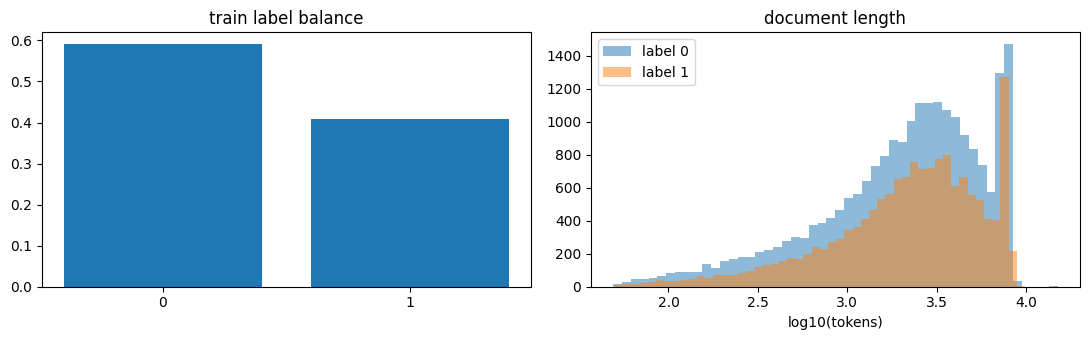

In [ ]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

def iter_json_list(path):
    try:
        import ijson
        with open(path, "rb") as f:
            for d in ijson.items(f, "item"): yield d
    except ImportError:                      # fallback: loads the whole file (several GB RAM)
        for d in json.load(open(path, encoding="utf-8")): yield d

KEEP_HEAD, KEEP_TAIL = 4096, 12288          # long docs: keep head + tail tokens (verdicts are at the end)
def _enc(text):
    ids = tokenizer.encode(clean_text(text)); n = len(ids)
    if n > KEEP_HEAD + KEEP_TAIL: ids = ids[:KEEP_HEAD] + ids[-KEEP_TAIL:]
    return np.asarray(ids, dtype=np.int32), n

def build_cache(split, fname, keep_tail_text=False):
    p = f"{CACHE}/{split}"
    if os.path.exists(p + "_off.npy"): return
    toks, off, orig, ys, ids, tails, buf = [], [0], [], [], [], [], []
    pool = mp.get_context("fork").Pool(max(1, (os.cpu_count() or 2) - 1))
    def flush():
        res = pool.map(_enc, [d["text"] for d in buf], chunksize=8)
        for d, (a, n) in zip(buf, res):
            toks.append(a); off.append(off[-1] + len(a)); orig.append(n); ids.append(str(d["id"]))
            ys.append(int(d["label"]) if d.get("label") is not None else -1)
            if keep_tail_text: tails.append(d["text"][-400:])
        buf.clear()
    for d in tqdm(iter_json_list(hf(f"{P4}/{fname}")), desc=split):
        buf.append(d)
        if len(buf) >= 2000: flush()
    if buf: flush()
    pool.close()
    np.save(p + "_tok.npy", np.concatenate(toks)); np.save(p + "_off.npy", np.array(off, np.int64))
    np.save(p + "_y.npy", np.array(ys, np.int8)); np.save(p + "_orig.npy", np.array(orig, np.int64))
    json.dump(ids, open(p + "_ids.json", "w"))
    if keep_tail_text: json.dump(tails, open(p + "_tails.json", "w"))

build_cache("train", "Train/train.json"); build_cache("dev", "Train/dev.json", keep_tail_text=True); build_cache("test", "Test/test.json")

class Split:
    def __init__(s, name):
        p = f"{CACHE}/{name}"; s.tok = np.load(p + "_tok.npy", mmap_mode="r"); s.off = np.load(p + "_off.npy")
        s.y = np.load(p + "_y.npy"); s.orig = np.load(p + "_orig.npy"); s.ids = json.load(open(p + "_ids.json")); s.n = len(s.ids)
        s.tails = json.load(open(p + "_tails.json")) if os.path.exists(p + "_tails.json") else None
    def doc(s, i): return s.tok[s.off[i]:s.off[i + 1]]
TRAIN, DEV, TEST = Split("train"), Split("dev"), Split("test")

# ---- EDA ----
print(pd.DataFrame([dict(split=n, docs=s.n, pos_frac=float((s.y == 1).mean()) if s.y[0] >= 0 else np.nan,
                         median_tokens=int(np.median(s.orig)), p90_tokens=int(np.percentile(s.orig, 90)),
                         frac_over_512=float((s.orig > 512).mean()), frac_over_4096=float((s.orig > 4096).mean()))
                    for n, s in [("train", TRAIN), ("dev", DEV), ("test", TEST)]]).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(["0", "1"], [(TRAIN.y == 0).mean(), (TRAIN.y == 1).mean()]); ax[0].set_title("train label balance")
for c in (0, 1): ax[1].hist(np.log10(TRAIN.orig[TRAIN.y == c] + 1), bins=50, alpha=.5, label=f"label {c}")
ax[1].set_xlabel("log10(tokens)"); ax[1].legend(); ax[1].set_title("document length"); plt.tight_layout(); plt.savefig(f"{WORK}/eda.png", dpi=150); plt.show()

In [ ]:
# kind=flat: one sequence per doc | kind=hier: K chunks per doc (cut from the END so the last chunk is full)
VIEWS = {
    "head512":    dict(kind="flat", L=512,  part="head", mbs=16),
    "tail512":    dict(kind="flat", L=512,  part="tail", mbs=16),
    "tail1024":   dict(kind="flat", L=1024, part="tail", mbs=8),
    "ht1024":     dict(kind="flat", L=1024, part="ht", head=256, mbs=8),     # first 256 + last 768 tokens
    "hier8":      dict(kind="hier", K=8, L=512, pick="ht",   mbs=2),         # first K/4 + last 3K/4 chunks
    "hier8_tail": dict(kind="hier", K=8, L=512, pick="tail", mbs=2),
    "hier8_even": dict(kind="hier", K=8, L=512, pick="even", mbs=2),
}
VIEWS.update({
    "hier4":      dict(kind="hier", K=4, L=256, pick="ht",   mbs=8),   # 1 head chunk + 3 tail chunks, 4x256 tokens
    "hier4_tail": dict(kind="hier", K=4, L=256, pick="tail", mbs=8),
})
def flat_seq(ids, v):
    L = v["L"] - 2
    if len(ids) <= L: seg = ids
    elif v["part"] == "head": seg = ids[:L]
    elif v["part"] == "tail": seg = ids[-L:]
    else: h = v["head"]; seg = np.concatenate([ids[:h], ids[-(L - h):]])
    return [BOS] + list(map(int, seg)) + [EOS]

def hier_chunks(ids, v):
    L, K, n = v["L"] - 2, v["K"], len(ids)
    chunks = [ids[max(0, e - L):e] for e in range(n, 0, -L)][::-1]
    nc = len(chunks)
    if nc > K:
        if v["pick"] == "tail": sel = range(nc - K, nc)
        elif v["pick"] == "ht": h = K // 4; sel = list(range(h)) + list(range(nc - (K - h), nc))
        else: sel = np.linspace(0, nc - 1, K).round().astype(int)
        chunks = [chunks[i] for i in sel]
    return [[BOS] + list(map(int, c)) + [EOS] for c in chunks]

class DocDS(torch.utils.data.Dataset):
    def __init__(s, sp, idx, v): s.sp, s.idx, s.v = sp, np.asarray(idx), v
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        j = int(s.idx[k]); ids = np.asarray(s.sp.doc(j))
        return j, (flat_seq(ids, s.v) if s.v["kind"] == "flat" else hier_chunks(ids, s.v)), int(s.sp.y[j])

def collate_fn(v):
    def f(items):
        B = len(items); js = [x[0] for x in items]; y = torch.tensor([x[2] for x in items])
        if v["kind"] == "flat":
            Lm = max(len(x[1]) for x in items); ids = torch.full((B, Lm), PAD, dtype=torch.long); lens = torch.zeros(B, dtype=torch.long)
            for b, x in enumerate(items): ids[b, :len(x[1])] = torch.tensor(x[1]); lens[b] = len(x[1])
            return dict(j=js, y=y, ids=ids, lens=lens)
        K = v["K"]; Lm = max(len(c) for x in items for c in x[1])
        ids = torch.full((B, K, Lm), PAD, dtype=torch.long); lens = torch.ones(B, K, dtype=torch.long); cm = torch.zeros(B, K, dtype=torch.bool)
        for b, x in enumerate(items):
            off = K - len(x[1])                                  # right-align: last chunk always at index K-1
            for q, c in enumerate(x[1]): ids[b, off + q, :len(c)] = torch.tensor(c); lens[b, off + q] = len(c); cm[b, off + q] = True
        return dict(j=js, y=y, ids=ids, lens=lens, cm=cm)
    return f
def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [ ]:
def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"])
    sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}

    if layers_keep is None:
        lm = LegalLM(**cfg)
        if not random_init:
            lm.load_state_dict(sd)
    else:
        # Student: subset of Phase-1 layers, initialised from their weights
        sub_cfg = dict(cfg, layers=len(layers_keep))
        lm = LegalLM(**sub_cfg)
        new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None:
                new[k] = v
            elif int(m[1]) in layers_keep:
                new[f"blocks.{layers_keep.index(int(m[1]))}.{m[2]}"] = v
        lm.load_state_dict(new, strict=True)
    return lm

# class LMBackbone(nn.Module):                     # interface for ANY Phase-1 arch: wte, blocks, ln_f, dim
#     def __init__(s, lm): super().__init__(); s.wte, s.blocks, s.ln_f, s.dim = lm.wte, lm.blocks, lm.ln_f, lm.cfg["dim"]
#     def hidden(s, x, gc=False):
#         for b in s.blocks:
#             x = ckpt_util.checkpoint(lambda t, b=b: b(t)[0], x, use_reentrant=False) if (gc and s.training and torch.is_grad_enabled()) else b(x)[0]
#         return s.ln_f(x)

class LMBackbone(nn.Module):
    def __init__(s, lm):
        super().__init__()
        s.wte = lm.wte
        s.blocks = lm.blocks
        s.ln_f = lm.norm_f
        s.dim = lm.wte.embedding_dim
        s.n_frozen_prefix = 0
        s.slopes = lm.slopes
        s.heads = lm.heads

    def hidden(s, x, gc=False):
        t = x.size(1)
        bias = alibi_causal_bias(s.slopes, t, t, x.device)
        for i, b in enumerate(s.blocks):
            if i < s.n_frozen_prefix:
                with torch.no_grad():
                    x = b(x, bias)[0]
            elif gc and s.training and torch.is_grad_enabled():
                x = ckpt_util.checkpoint(
                    lambda z, block=b: block(z, bias)[0],
                    x, use_reentrant=False
                )
            else:
                x = b(x, bias)[0]
        return s.ln_f(x)


class CJPEModel(nn.Module):
    """sequence/chunk -> pooled vector -> (hier: chunk-position emb + 1-layer transformer + attention pool) -> 2 logits"""
    def __init__(s, bb, view, pool="last_mean", drop=0.1):
        super().__init__(); s.bb, D = bb, bb.dim; s.pool, s.kind, s.gc = pool, view["kind"], False
        pd_ = 2 * D if pool == "last_mean" else D
        if pool == "attn": s.tatt = nn.Linear(D, 1)
        s.proj = nn.Sequential(nn.LayerNorm(pd_), nn.Dropout(drop), nn.Linear(pd_, D), nn.GELU())
        if s.kind == "hier":
            s.cpos = nn.Embedding(view["K"], D); nn.init.normal_(s.cpos.weight, std=0.02)
            s.denc = nn.TransformerEncoder(nn.TransformerEncoderLayer(D, 8, 2 * D, drop, batch_first=True, norm_first=True, activation="gelu"), 1)
            s.catt = nn.Linear(D, 1)
        s.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, 2)); s.ada = None
    def _pool(s, h, lens):
        m = torch.arange(h.size(1), device=h.device)[None] < lens[:, None]; last = h[torch.arange(len(lens)), lens - 1]
        if s.pool == "last": return last
        if s.pool == "attn":
            w = torch.softmax(s.tatt(h).squeeze(-1).float().masked_fill(~m, -1e4), -1); return (w[..., None] * h).sum(1)
        mean = (h * m[..., None]).sum(1) / lens[:, None]
        return mean if s.pool == "mean" else torch.cat([last, mean], -1)
    def seq_rep(s, ids, lens):
        h = s.bb.hidden(s.bb.wte(ids[:, :int(lens.max())]), s.gc).float(); return s.proj(s._pool(h, lens))
    def forward(s, b):
        if s.kind == "flat": z = s.seq_rep(b["ids"], b["lens"])
        else:
            cm = b["cm"]; B, K = cm.shape; zr = s.seq_rep(b["ids"][cm], b["lens"][cm])      # only real chunks are encoded
            z = zr.new_zeros(B, K, zr.size(-1)); z[cm] = zr
            z = s.denc(z + s.cpos.weight[None], src_key_padding_mask=~cm)
            w = torch.softmax(s.catt(z).squeeze(-1).float().masked_fill(~cm, -1e4), -1); z = (w[..., None] * z).sum(1)
        return s.cls(z), z

# ---------------- adapters ----------------
class LoRMALinear(nn.Module):                    # multiplicative low-rank:  W' = (I + B A) W  ->  y = h + B A h,  h = W x
    def __init__(s, base, r=16, alpha=16):
        super().__init__(); s.base = base
        s.A = nn.Parameter(torch.empty(r, base.out_features)); s.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(s.A, a=math.sqrt(5)); s.scale = alpha / r
    def forward(s, x): h = s.base(x); return h + F.linear(F.linear(h, s.A), s.B) * s.scale

class AdaLoRALinear(nn.Module):
    def __init__(s, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); s.base = base
        s.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); s.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        s.E = nn.Parameter(torch.zeros(r)); s.register_buffer("mask", torch.ones(r)); s.scale = alpha / r; s.drop = nn.Dropout(dropout)
    def forward(s, x): return s.base(x) + F.linear(F.linear(s.drop(x), s.A) * (s.E * s.mask).to(x.dtype), s.B) * s.scale
    def orth(s):
        I = torch.eye(s.E.numel(), device=s.A.device); return ((s.A @ s.A.t() - I) ** 2).sum() + ((s.B.t() @ s.B - I) ** 2).sum()

class AdaLoRAManager:                            # sensitivity-based rank pruning with a cubic budget schedule
    def __init__(s, model, total, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        s.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]; s.T, s.beta, s.ti, s.tf, s.dt = total, beta, ti, tf, dt
        s.b0 = sum(m.E.numel() for m in s.mods); s.bT = target_rank * len(s.mods); s.I, s.U = {}, {}
    def budget(s, t):
        ti, tf = int(s.ti * s.T), int(s.tf * s.T)
        if t < ti: return s.b0
        if t >= s.T - tf: return s.bT
        return int(s.bT + (s.b0 - s.bT) * (1 - (t - ti) / max(1, s.T - tf - ti)) ** 3)
    def orth_loss(s): return sum(m.orth() for m in s.mods)
    @torch.no_grad()
    def update(s, t):
        for k, m in enumerate(s.mods):
            if m.E.grad is None or m.A.grad is None: return
            sc = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in s.I: s.I[k], s.U[k] = sc.clone(), torch.zeros_like(sc)
            else: s.I[k] = s.beta * s.I[k] + (1 - s.beta) * sc; s.U[k] = s.beta * s.U[k] + (1 - s.beta) * (sc - s.I[k]).abs()
        if t % s.dt == 0 and len(s.I) == len(s.mods):
            sc = torch.cat([s.I[k] * s.U[k] for k in range(len(s.mods))]); mk = torch.zeros_like(sc); mk[sc.topk(min(s.budget(t), sc.numel())).indices] = 1; o = 0
            for m in s.mods: r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(s): return float(sum(m.mask.sum().item() for m in s.mods) / len(s.mods))

class BitFitLinear(nn.Module):                   # Phase-1 Linears are probably bias-free -> add zero-init trainable bias
    def __init__(s, base):
        super().__init__(); s.base = base; s.bias = nn.Parameter(torch.zeros(base.out_features))
        if base.bias is not None: s.bias.data.copy_(base.bias.data)
    def forward(s, x): return F.linear(x, s.base.weight) + s.bias.to(x.dtype)

class AdapterBlock(nn.Module):                   # serial bottleneck adapter after each transformer block (zero-init up-projection)
    def __init__(s, blk, D, r=64):
        super().__init__(); s.blk = blk; s.down, s.up = nn.Linear(D, r), nn.Linear(r, D); nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x, *a, **k):
        o = s.blk(x, *a, **k); y = o[0] if isinstance(o, tuple) else o; y = y + s.up(F.gelu(s.down(y)))
        return (y,) + tuple(o[1:]) if isinstance(o, tuple) else y

TARGETS = ("attn.q", "attn.kv", "attn.proj", "mlp.w1", "mlp.w3", "mlp.w2")
def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            if isinstance(ch, nn.Linear) and (suffixes is None or any(full.endswith(s) for s in suffixes)): setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb; L = len(bb.blocks)
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m == "lorma": replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "bitfit":
        replace_linears(bb, None, lambda n, l: BitFitLinear(l))
        for mod in bb.modules():
            if type(mod).__name__.lower().endswith("norm"):
                for p in mod.parameters(): p.requires_grad = True
        for mod in bb.modules():
            if isinstance(mod, BitFitLinear): mod.bias.requires_grad = True
    elif m == "adapter":
        for i in range(L): bb.blocks[i] = AdapterBlock(bb.blocks[i], bb.dim, cfg.get("r_ad", 64))
    elif m == "partial":                         # layer freezing: only top-n blocks (+final norm) trainable; optional gradual unfreezing
        keep = L if cfg.get("gradual") else cfg["n_unfreeze"]
        for i, b in enumerate(bb.blocks):
            for p in b.parameters(): p.requires_grad = (i >= L - (1 if cfg.get("gradual") else keep))
        for p in bb.ln_f.parameters(): p.requires_grad = True
        if not cfg.get("gradual"): bb.n_frozen_prefix = L - cfg["n_unfreeze"]
    elif m == "linear_probe": bb.n_frozen_prefix = L
    elif m != "full": raise ValueError(m)

def unfreeze_upto(model, step, every):           # gradual unfreezing: one more layer (top-down) every `every` steps
    L = len(model.bb.blocks); k = min(L, 1 + step // every)
    for i, b in enumerate(model.bb.blocks):
        if i >= L - k:
            for p in b.parameters(): p.requires_grad = True

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    m = CJPEModel(bb, VIEWS[cfg["view"]], cfg["pool"]); m.gc = cfg.get("gc", False); apply_method(m, cfg); return m.to(DEVICE)

def model_stats(m):
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad); tot = sum(p.numel() for p in m.parameters())
    return tr, tot, sum(p.numel() * p.element_size() for p in m.parameters()) / 2**20

In [ ]:
RES_PATH = f"{WORK}/results.json"; RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def save_results(): json.dump(RESULTS, open(RES_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
def save_ckpt(path, st): torch.save(st, path + ".tmp"); os.replace(path + ".tmp", path)      # atomic: a killed session never leaves a corrupt file

def stratified_subset(sp, n, seed):
    if n is None or n >= sp.n: return np.arange(sp.n)
    rs = np.random.RandomState(seed); out = []
    for c in (0, 1):
        ix = np.where(sp.y == c)[0]; out.append(rs.choice(ix, min(len(ix), int(n * len(ix) / sp.n)), replace=False))
    return np.sort(np.concatenate(out))
SUB, DEV_SUB = stratified_subset(TRAIN, TRAIN_N, SEED), stratified_subset(DEV, DEV_FREQ_N, 1)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p))

@torch.no_grad()
def predict_logits(model, sp, idx, v, bs):
    model.eval(); idx = np.asarray(idx); o = np.argsort(sp.orig[idx])                    # length-sorted batches = less padding
    dl = torch.utils.data.DataLoader(DocDS(sp, idx[o], v), batch_size=bs, collate_fn=collate_fn(v), num_workers=NW)
    res = []
    for b in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): lg, _ = model(to_dev(b))
        res.append(lg.float().cpu().numpy())
    out = np.zeros((len(idx), 2), np.float32); out[o] = np.concatenate(res); return out

def best_bias(lg, y, grid=np.linspace(-3, 3, 121)):            # decision-threshold shift maximising macro-F1
    d = lg[:, 1] - lg[:, 0]; f = [f1_score(y, (d + g > 0).astype(int), average="macro", zero_division=0) for g in grid]; return float(grid[int(np.argmax(f))]), float(max(f))

def cls_loss(lg, y, kind, w):
    lg = lg.float()
    if kind == "focal": lpt = F.log_softmax(lg, -1).gather(1, y[:, None])[:, 0]; return (-(1 - lpt.exp()) ** 2 * lpt * w[y]).mean()
    return F.cross_entropy(lg, y, weight=w if kind == "wce" else None)

def param_groups(model, cfg):
    lr, bb = cfg["lr"], model.bb; L = len(bb.blocks); d = cfg.get("llrd"); gs = []
    bbp = [(n, p) for n, p in model.named_parameters() if n.startswith("bb.") and (p.requires_grad or cfg.get("gradual"))]
    if d:                                                                   # layer-wise LR decay (deeper = larger LR)
        for n, p in bbp:
            m = re.match(r"bb\.blocks\.(\d+)\.", n); depth = (L - 1 - int(m[1])) if m else (L if n.startswith("bb.wte") else 0)
            gs.append(dict(params=[p], lr=lr * d ** depth, base=lr * d ** depth))
    elif bbp: gs.append(dict(params=[p for _, p in bbp], lr=lr, base=lr))
    hp = [p for n, p in model.named_parameters() if not n.startswith("bb.") and p.requires_grad]
    gs.append(dict(params=hp, lr=cfg["head_lr"], base=cfg["head_lr"])); return [g for g in gs if g["params"]]

TEACHER_LOGITS = {}
def get_teacher_logits(tname):
    if tname in TEACHER_LOGITS: return TEACHER_LOGITS[tname]
    f = f"{CK}/{tname}_trainlogits.npy"
    if not os.path.exists(f):
        tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}_best.pt", map_location=DEVICE), strict=False)
        TL = np.full((TRAIN.n, 2), np.nan, np.float32); TL[SUB] = predict_logits(t, TRAIN, SUB, VIEWS[tc["view"]], VIEWS[tc["view"]]["mbs"] * 2)
        np.save(f, TL); del t; gc.collect(); torch.cuda.empty_cache()
    TEACHER_LOGITS[tname] = np.load(f); return TEACHER_LOGITS[tname]

def make_order(total, balanced, seed):
    rs = np.random.RandomState(seed); y = TRAIN.y[SUB]
    if balanced: p = np.where(y == 1, 0.5 / (y == 1).sum(), 0.5 / (y == 0).sum()); return rs.choice(SUB, total, p=p)
    out = []
    while sum(map(len, out)) < total: out.append(rs.permutation(SUB))
    return np.concatenate(out)[:total]

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | view={cfg['view']} | pool={cfg['pool']} | loss={cfg['loss']} ===")
    set_seed(cfg["seed"]); v = VIEWS[cfg["view"]]; mbs = v["mbs"]; accum = max(1, EFF_BS // mbs); total = cfg["steps"]
    if USE_AMP: torch.cuda.reset_peak_memory_stats()
    model = build_model(cfg); tr, tot, mb = model_stats(model); print(f"trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M")
    w = None
    if cfg["loss"] in ("wce", "focal"):
        c = np.bincount(TRAIN.y[SUB], minlength=2).astype(float); w = torch.tensor((c.sum() / (2 * c)) ** 0.5, dtype=torch.float32, device=DEVICE); w = w / w.mean()
    kd = cfg.get("kd"); TL = get_teacher_logits(kd["teacher"]) if kd else None
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    if cfg.get("gradual"): unfreeze_upto(model, 0, cfg["gradual"])
    opt = torch.optim.AdamW(param_groups(model, cfg), weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    warm = max(1, int(0.06 * total)); step, best, bad, hist, best_state, elapsed = 0, -1, 0, [], None, 0.0
    last = f"{CK}/{name}_last.pt"
    if not os.path.exists(f"{CK}/{name}_last.pt"):
        last = f"{CK}/{name}_best.pt"
    print(last)
    if os.path.exists(last):                                                                # ---- resume ----
        st = torch.load(last, map_location="cpu", weights_only=False); step = st["step"]
        if cfg.get("gradual"): unfreeze_upto(model, step, cfg["gradual"])
        model.load_state_dict(st["train"], strict=False); opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
        best, bad, hist, best_state, elapsed = st["best"], st["bad"], st["hist"], st["best_state"], st["elapsed"]
        if model.ada is not None and st.get("ada"): model.ada.I, model.ada.U = st["ada"]
        print(f"resumed from step {step}")
    def tracked(): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                           if k in {n for n, p in model.named_parameters() if p.requires_grad} or k.endswith(".mask")}
    def dump():
        save_ckpt(last, dict(step=step, train=tracked(), opt=opt.state_dict(), scaler=scaler.state_dict(), best=best, bad=bad, hist=hist,
                             best_state=best_state, elapsed=elapsed, ada=(model.ada.I, model.ada.U) if model.ada else None))
    order = make_order(total * EFF_BS, cfg.get("balanced", False), cfg["seed"])[step * EFF_BS:]
    dl = torch.utils.data.DataLoader(DocDS(TRAIN, order, v), batch_size=mbs, collate_fn=collate_fn(v), num_workers=NW, pin_memory=USE_AMP, prefetch_factor=4 if NW else None)
    it = iter(dl); t0 = time.time(); run_loss, nb = 0.0, 0; pbar = tqdm(total=total, initial=step, desc=name)
    while step < total:
        model.train()
        if cfg.get("gradual"): unfreeze_upto(model, step, cfg["gradual"])
        for _ in range(accum):
            b = to_dev(next(it))
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, _z = model(b); loss = cls_loss(lg, b["y"], cfg["loss"], w)
                if kd:
                    tl = torch.tensor(TL[b["j"]], device=DEVICE); T = kd["T"]
                    kdl = F.kl_div(F.log_softmax(lg.float() / T, -1), F.softmax(tl / T, -1), reduction="batchmean") * T * T
                    loss = kd["alpha"] * loss + (1 - kd["alpha"]) * kdl
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / accum).backward(); run_loss += loss.item(); nb += 1
        f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
        for g in opt.param_groups: g["lr"] = g["base"] * max(f, 0.02)
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 1.0)
        if model.ada is not None: model.ada.update(step)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1; pbar.update(1)
        pbar.set_postfix(loss=f"{run_loss/max(1,nb):.3f}")
        stop = False
        if step % cfg.get("eval_every", EVAL_EVERY) == 0 or step == total:
            m = metrics(DEV.y[DEV_SUB], predict_logits(model, DEV, DEV_SUB, v, mbs * 2).argmax(1))
            hist.append(dict(step=step, loss=run_loss / max(1, nb), **m)); run_loss, nb = 0.0, 0
            print(f" step {step}: dev-sub macro-F1 {m['f1']:.4f} P {m['P']:.3f} R {m['R']:.3f}")
            if m["f1"] > best: best, bad, best_state = m["f1"], 0, tracked()
            else:
                bad += 1; stop = bad >= PATIENCE
        capped = MAX_MIN_PER_RUN and (elapsed + time.time() - t0) / 60 > MAX_MIN_PER_RUN
        if step % CKPT_EVERY == 0 or stop or capped:
            elapsed += time.time() - t0; t0 = time.time(); dump()
        if stop or capped: print("early stop" if stop else "time cap reached"); break
    pbar.close(); elapsed += time.time() - t0
    if best_state is None: best_state = tracked()
    model.load_state_dict(best_state, strict=False); torch.save(best_state, f"{CK}/{name}_best.pt")

    # ---- final: full dev, test, latency, memory ----
    alld = np.arange(DEV.n); dl_ = predict_logits(model, DEV, alld, v, mbs * 2); ydev = DEV.y
    t1 = time.time(); predict_logits(model, DEV, alld[:300], v, mbs * 2); dps = 300 / (time.time() - t1)
    bias, f1_tuned = best_bias(dl_, ydev); tl_ = predict_logits(model, TEST, np.arange(TEST.n), v, mbs * 2)
    np.save(f"{PRED_DIR}/{name}_dev.npy", dl_); np.save(f"{PRED_DIR}/{name}_test.npy", tl_)
    json.dump([dict(id=i, pred=int(p)) for i, p in zip(TEST.ids, tl_.argmax(1))], open(f"{PRED_DIR}/{name}_test.json", "w"))
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=elapsed / 60, steps=step, hist=hist,
               dev=metrics(ydev, dl_.argmax(1)), f1=metrics(ydev, dl_.argmax(1))["f1"], f1_tuned=f1_tuned, bias=bias, docs_per_s=dps,
               peak_mem_mb=(torch.cuda.max_memory_allocated() / 2**20 if USE_AMP else 0))
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    RESULTS[name] = res; save_results()
    print(f"-> {name}: dev macro-F1 {res['f1']:.4f} (threshold-tuned {f1_tuned:.4f}) | {res['train_min']:.1f} min | {dps:.1f} docs/s | peak {res['peak_mem_mb']:.0f} MB")
    if os.path.exists(last): os.remove(last)
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return res

In [ ]:
def sec_per_step(cfg, n_micro=3):
    v = VIEWS[cfg["view"]]; mbs = v["mbs"]; accum = max(1, EFF_BS // mbs)
    model = build_model(cfg); model.train(); model.gc = cfg.get("gc", False)
    params = [p for p in model.parameters() if p.requires_grad]; opt = torch.optim.AdamW(params, lr=1e-6)
    dl = torch.utils.data.DataLoader(DocDS(TRAIN, SUB[:mbs * (n_micro + 1)], v), batch_size=mbs, collate_fn=collate_fn(v))
    ts = []
    for k, b in enumerate(dl):
        b = to_dev(b); torch.cuda.synchronize() if USE_AMP else None; t = time.time()
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): lg, _ = model(b); loss = F.cross_entropy(lg.float(), b["y"])
        loss.backward(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize() if USE_AMP else None
        if k > 0: ts.append(time.time() - t)                                      # first batch = warm-up
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return float(np.mean(ts)) * accum

def fit_steps(cfg, budget_min=TARGET_MIN, n_evals=4):
    sps = sec_per_step(cfg); fwd_doc = sps / EFF_BS / 3                          # forward-only cost per doc ~ 1/3 of fwd+bwd
    fixed = (n_evals * DEV_FREQ_N + DEV.n + TEST.n) * fwd_doc                    # in-training evals + final dev + test
    steps = int(max(60, min(MAX_STEPS, (budget_min * 60 - fixed) / sps)))
    print(f"{cfg['name']:18s} {sps:5.2f}s/step | eval overhead ~{fixed/60:4.1f} min | -> {steps} steps (~{(steps*sps+fixed)/60:.1f} min)")
    return steps

def common_steps(names):                                                         # same steps inside a group = fair comparison
    s = min(fit_steps(EXPS[n]) for n in names)
    for n in names: EXPS[n]["steps"] = s; EXPS[n]["eval_every"] = max(25, s // 4)
    return s

In [ ]:
BASE = dict(pool="last_mean", loss="wce", lr=5e-4, head_lr=1e-3, steps=MAX_STEPS, seed=SEED, balanced=False)

METHOD_HP = {
    "linear_probe": dict(head_lr=2e-3),
    "full":    dict(lr=3e-5, llrd=0.9),                       # slightly lower lr for 75M ALiBi+GQA model
    "partial": dict(lr=2e-4, n_unfreeze=3),
    "bitfit":  dict(lr=2e-3),
    "adapter": dict(lr=1e-3, r_ad=64),
    "lorma":   dict(r=16, alpha=16, lr=5e-4),
    "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
}

def E(name, group, method, view, **kw):
    c = dict(BASE)
    c.update(METHOD_HP.get(method, {}))
    # Enable gradient checkpointing for full fine-tuning or hierarchical views to optimize memory for GQA layers
    c.update(name=name, group=group, method=method, view=view, gc=(VIEWS[view]["kind"] == "hier" or method == "full"))
    c.update(kw)
    return c

EXPS = {}
def reg(c):
    EXPS[c["name"]] = c
    return c

# Registering baseline and primary LoRMA run for your best view
for v in VIEWS:
    reg(E(f"v_{v}", "view", "lorma", v))

# Select the optimal variant for production execution
BEST_VARIANT = "v_hier8_tail"  # Leveraging the 1024-token context window which maps well to ALiBi's linear distance bias

# Register the BitFit experiment using the ht1024 view and LoRMA as a base or bitfit method override
reg(E("v_hier8_tail_bitfit", "method", "bitfit", "hier8_tail"))

# Run the experiment
train_run(EXPS["v_hier8_tail_bitfit"])

skip (done): v_hier8_tail_bitfit


{'name': 'v_hier8_tail_bitfit',
 'group': 'method',
 'cfg': {'pool': 'last_mean',
  'loss': 'wce',
  'lr': 0.002,
  'head_lr': 0.001,
  'steps': 300,
  'seed': 42,
  'balanced': False,
  'name': 'v_hier8_tail_bitfit',
  'group': 'method',
  'method': 'bitfit',
  'view': 'hier8_tail',
  'gc': True},
 'trainable': 6024195,
 'total': 108456963,
 'size_mb': 413.7304801940918,
 'train_min': 130.35440904299418,
 'steps': 300,
 'hist': [{'step': 200,
   'loss': 0.802446076029446,
   'f1': 0.3333333333333333,
   'P': 0.25,
   'R': 0.5,
   'acc': 0.5},
  {'step': 300,
   'loss': 0.6830253148730844,
   'f1': 0.3996279384407238,
   'P': 0.6736111111111112,
   'R': 0.5266666666666667,
   'acc': 0.5266666666666666}],
 'dev': {'f1': 0.3991506531808154,
  'P': 0.6693134171907756,
  'R': 0.5261569416498995,
  'acc': 0.5261569416498993},
 'f1': 0.3991506531808154,
 'f1_tuned': 0.6129911424029071,
 'bias': 0.4500000000000002,
 'docs_per_s': 3.4389854557365123,
 'peak_mem_mb': 3059.84912109375}

In [ ]:
# RESULTS_ALIAS = {"m_lorma": BEST_RUN}
def results_df():
    if not RESULTS:
        print("WARNING: RESULTS dictionary is empty! Run training/evaluation cells first.")
        return pd.DataFrame()

    rows = []
    for n, r in RESULTS.items():
        rows.append(dict(
            name=n,
            group=r.get("group", "unknown"),
            method=r["cfg"]["method"],
            view=r["cfg"]["view"],
            loss=r["cfg"]["loss"],
            pool=r["cfg"]["pool"],
            trainable_M=r["trainable"] / 1e6,
            total_M=r["total"] / 1e6,
            size_MB=r["size_mb"],
            train_min=r["train_min"],
            docs_per_s=r["docs_per_s"],
            peak_mem_MB=r["peak_mem_mb"],
            F1=r["f1"],
            P=r["dev"]["P"],
            R=r["dev"]["R"],
            acc=r["dev"]["acc"],
            F1_tuned=r.get("f1_tuned", r["f1"])
        ))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1"], ascending=[True, False]).round(4).to_string(index=False)); df.to_csv(f"{WORK}/summary.csv", index=False)


               name  group method       view loss      pool  trainable_M  total_M  size_MB  train_min  docs_per_s  peak_mem_MB     F1      P      R    acc  F1_tuned
v_hier8_tail_bitfit method bitfit hier8_tail  wce last_mean       6.0242  108.457 413.7305   130.3544       3.439    3059.8491 0.3992 0.6693 0.5262 0.5262     0.613


In [ ]:
# import os, zipfile, json, numpy as np

# def tune_threshold(probs, labels):
#     grid = np.arange(0.05, 0.96, 0.01)
#     f1s = [f1_score(labels, (probs >= t).astype(int), average="macro") for t in grid]
#     best = int(np.argmax(f1s))
#     return float(grid[best]), float(f1s[best])

# for exp_name, result in RESULTS.items():
#     if result is None:
#         continue

#     cfg = result["cfg"]
#     v = VIEWS[cfg["view"]]
#     mbs = v["mbs"]

#     # Build and load model
#     model = build_model(cfg)
#     model.load_state_dict(torch.load(f"{CK}/{exp_name}_best.pt", map_location=DEVICE), strict=False)
#     model.eval()

#     # Generate logits
#     dev_logits = predict_logits(model, DEV, np.arange(DEV.n), v, mbs * 2)
#     test_logits = predict_logits(model, TEST, np.arange(TEST.n), v, mbs * 2)

#     # Tune threshold
#     threshold, val_f1 = tune_threshold(dev_logits[:,1], DEV.y)
#     print(f"{exp_name}: tuned threshold={threshold:.3f}, dev macro-F1={val_f1:.4f}")

#     # Apply threshold
#     final_test_preds = (test_logits[:,1] >= threshold).astype(int)

#     # Save raw logits
#     np.save(f"{PRED_DIR}/{exp_name}_dev_tuned.npy", dev_logits)
#     np.save(f"{PRED_DIR}/{exp_name}_test_tuned.npy", test_logits)

#     # Prepare submission folder + JSON
#     sub_dir = os.path.join(PRED_DIR, f"submission_{exp_name}")
#     os.makedirs(sub_dir, exist_ok=True)
#     pred_path = os.path.join(sub_dir, "prediction.json")

#     with open(pred_path, "w") as f:
#         json.dump([{"id": str(i), "pred": int(p)} for i, p in zip(TEST.ids, final_test_preds)], f)

#     # Zip it (Changed arcname to "prediction.json" so it sits at the root of the archive)
#     zip_path = os.path.join(PRED_DIR, f"submission_{exp_name}.zip")
#     with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
#         zf.write(pred_path, arcname="prediction.json")

#     print(f"Zipped submission for {exp_name} → {zip_path}")

---
## Architecture: `gqa_conv`

Source: `legal-gqa-conv.ipynb`


In [ ]:
# ── Activate backbone: gqa_conv ──────────────────────────────────────────────
BACKBONE = "gqa_conv"
TOKENIZER_PATH = TOK_PATHS["gqa_conv"]
PHASE1_CKPT = CKPTS["gqa_conv"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")


[active] BACKBONE=gqa_conv
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt  exists=True


### Phase-1 classes for `gqa_conv` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


In [ ]:
import os, sys, re, gc, json, math, time, heapq, random, hashlib, unicodedata, zipfile, subprocess
import multiprocessing as mp
from collections import Counter, defaultdict, deque
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from tqdm.auto import tqdm

try:
    import ijson
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "ijson"])
    import ijson
from huggingface_hub import hf_hub_download, login

# ------------------------------- Configuration -------------------------------
SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = {
    "acts":          "Phase_1_Pretraining/Train/train_acts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "high_courts":   "Phase_1_Pretraining/Train/train_high_courts.json",
    "tribunals":     "Phase_1_Pretraining/Train/train_tribunals.json",
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

SOURCE_TOKENS = {"acts": 15_000_000, "supreme_court": 35_000_000, "high_courts": 35_000_000, "tribunals": 25_000_000}
SAMPLE_MIX = {"acts": 1.0, "supreme_court": 1.0, "high_courts": 0.30, "tribunals": 0.40}
VAL_TOKENS_PER_SOURCE = 500_000
VAL_MOD = 50
BYTES_PER_TOKEN = 4.0
NUM_WORKERS = 4

VOCAB_SIZE = 30000
TOK_CHARS_PER_SOURCE = 4_000_000

# Model: Decoder-only GQA + RoPE + Dual-path FFN
BLOCK_SIZE = 1024
N_EMBD = 768
N_LAYER = 8
N_HEAD = 12
KV_HEADS = 4                          # Grouped-Query Attention: 12 Q-heads share 4 KV-heads (3x KV reduction)
QK_NORM = True                        # QK-Norm via RMSNorm per head

FFN_MULT = 3                          # SwiGLU expansion multiplier
CONV_K = 4                            # Causal depthwise 1D conv kernel size
DUAL_PATH = True                      # Enable Dual-Path FFN (SwiGLU + lambda * DWConv)
LAMBDA_PER_CHANNEL = True             # Learnable lambda vector per channel (vs single scalar)
LAMBDA_INIT = 0.0                     # Initial sigmoid(a) = 0.5

# Training / Optimization Schedule
P_DOC_START = 0.5                     # 50% windows start at doc beginning, 50% mid-document
TOKENS_PER_STEP = 65_536
MICRO_TOKENS = 16_384
STAGES = [(1024, 0.50)]  # Context curriculum
TRAIN_TOKENS = 150_000_000
LR, MIN_LR, WEIGHT_DECAY, WARMUP_STEPS = 6e-4, 6e-5, 0.1, 100
EVAL_EVERY, EVAL_WINDOWS, LOG_EVERY, CKPT_EVERY = 10, 48, 10, 50
MAX_TRAIN_HOURS = 8.0
USE_GRAD_CKPT = False
DO_TRAIN = True

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
# TOKENIZER_PATH = os.path.join(OUT_DIR, "legal_bpe_v2.json")
# MODEL_PATH = os.path.join(OUT_DIR, "legal_lm_v3_fixed.pt")
# CKPT_PATH = os.path.join(OUT_DIR, "latest_checkpoint_v3_fixed.pt")

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

def init_distributed():
    if "RANK" in os.environ and "WORLD_SIZE" in os.environ:
        dist.init_process_group(backend="nccl")
        local_rank = int(os.environ["LOCAL_RANK"])
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)
        return device, local_rank, True
    elif torch.cuda.device_count() > 1:
        # Fallback multi-GPU single-process using DataParallel
        return torch.device("cuda:0"), 0, False
    else:
        return torch.device("cuda" if torch.cuda.is_available() else "cpu"), 0, False

DEVICE, LOCAL_RANK, IS_DISTRIBUTED = init_distributed()
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
try:
    if HF_TOKEN: login(token=HF_TOKEN)
except Exception as e:
    print("HF login skipped:", e)

In [ ]:
# ------------------------------- 1. Tokenizer -------------------------------
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)
    t = _DOTS.sub("...", t)
    t = _RULE.sub(" ", t)
    t = _PAGE.sub("", t)
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def keep_doc(c):
    if len(c) < 600: return False
    head = c[:5000]
    if sum(ch.isalpha() for ch in head) / len(head) < 0.6: return False
    if sum(ord(ch) > 127 for ch in head) / len(head) > 0.2: return False
    w = c.split()
    if len(w) < 100: return False
    w = w[:3000]
    return len(set(w)) / len(w) >= 0.15

def extract_text(rec):
    if isinstance(rec, str): return rec
    if isinstance(rec, dict):
        for k in ("text", "train_text", "content", "body", "judgment", "document"):
            v = rec.get(k)
            if isinstance(v, str) and v.strip(): return v
        for v in rec.values():
            if isinstance(v, (dict, list)):
                s = extract_text(v)
                if s: return s
    if isinstance(rec, list):
        return "\n".join(filter(None, map(extract_text, rec)))
    return ""

def iter_docs(path):
    with open(path, "rb") as f:
        head = f.read(256).lstrip(b"\xef\xbb\xbf \n\r\t")[:1]
        f.seek(0)
        it = (v for _, v in ijson.kvitems(f, "")) if head == b"{" else ijson.items(f, "item")
        for rec in it:
            t = extract_text(rec)
            if t: yield t

In [ ]:
class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def train(self, texts, max_unique_words=200_000, min_freq=2):
        counts = Counter()
        for t in tqdm(texts, desc="counting pre-tokens"):
            counts.update(self._split.findall(t))
        if len(counts) > max_unique_words:
            counts = Counter(dict(counts.most_common(max_unique_words)))
        words, freqs = [], []
        pair_counts, pair_words = defaultdict(int), defaultdict(set)
        for wid, (w, c) in enumerate(counts.items()):
            toks = [bytes([b]) for b in w.encode("utf-8")]
            words.append(toks); freqs.append(c)
            for p in zip(toks, toks[1:]):
                pair_counts[p] += c; pair_words[p].add(wid)
        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)
        self.merges = []
        n_target = self.vocab_size - (4 + 256)
        seen = set(bytes([i]) for i in range(256))
        pbar = tqdm(total=n_target, desc="BPE merges")
        while len(self.merges) < n_target and heap:
            best = None
            while heap:
                negc, p = heapq.heappop(heap)
                cur = pair_counts.get(p, 0)
                if cur <= 0: continue
                if cur != -negc:
                    heapq.heappush(heap, (-cur, p)); continue
                best = p; break
            if best is None or pair_counts[best] < min_freq: break
            a, b = best; merged = a + b
            self.merges.append(best); seen.add(merged)
            for wid in list(pair_words.pop(best, ())):
                w, f = words[wid], freqs[wid]
                new, i = [], 0
                while i < len(w):
                    if i < len(w) - 1 and w[i] == a and w[i + 1] == b:
                        new.append(merged); i += 2
                    else:
                        new.append(w[i]); i += 1
                if len(new) == len(w): continue
                for p in zip(w, w[1:]): pair_counts[p] -= f
                for p in zip(new, new[1:]):
                    pair_counts[p] += f; pair_words[p].add(wid)
                    heapq.heappush(heap, (-pair_counts[p], p))
                words[wid] = new
            pbar.update(1)
        pbar.close()
        self._build()
        return self

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi[t] for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = [self.bos_id] if add_bos else []
        for ch in self._split.findall(text): ids.extend(self._word(ch))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        return b"".join(self.itos[i] for i in ids if 4 <= i < len(self.itos)).decode("utf-8", errors="replace")

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"vocab_size": self.vocab_size, "merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        d = json.load(open(path))
        t = cls(d["vocab_size"]); t.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in d["merges"]]
        t._build(); return t

In [ ]:
# ------------------------------- 3. Architecture Modules -------------------------------
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.w).type_as(x)

class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False); self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos, sin = self.cos[start:start + t].to(x.dtype), self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)

class GQAAttention(nn.Module):
    """Grouped-query attention + RoPE (+ QK-norm). The cache stores K/V with only `kv_heads` heads."""
    def __init__(self, c):
        super().__init__()
        d, self.h, self.hk = c["dim"], c["heads"], c["kv_heads"]
        assert self.h % self.hk == 0
        self.hd = d // self.h
        self.q = nn.Linear(d, self.h * self.hd, bias=False)
        self.kv = nn.Linear(d, 2 * self.hk * self.hd, bias=False)
        self.o = nn.Linear(self.h * self.hd, d, bias=False)
        self.qn = RMSNorm(self.hd) if c["qk_norm"] else nn.Identity()
        self.kn = RMSNorm(self.hd) if c["qk_norm"] else nn.Identity()
        self.rope = RoPE(self.hd, c["block_size"])

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.hk, self.hd).permute(2, 0, 3, 1, 4)
        q, k = self.rope(self.qn(q), start), self.rope(self.kn(k), start)
        if cache is not None:
            if cache[0] is not None: k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
            cache = (k, v)
        r = self.h // self.hk
        if t == 1 and cache is not None:           # decode step: fold query group into length axis
            y = F.scaled_dot_product_attention(q.reshape(b, self.hk, r, self.hd), k, v, attn_mask=mask)
            y = y.reshape(b, self.h, 1, self.hd)
        else:
            k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
            if mask is not None: y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
            else:               y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.o(y.transpose(1, 2).reshape(b, t, self.h * self.hd)), cache

class DualPathFFN(nn.Module):
    """Y = Wo[ SwiGLU(X) + lambda * DWConv(X) ],  lambda = sigmoid(a)   (Wo = self.w2)."""
    def __init__(self, c):
        super().__init__()
        d, self.k, self.dual = c["dim"], c["conv_k"], c["dual_path"]
        h = d * c["ffn_mult"]
        self.w13 = nn.Linear(d, 2 * h, bias=False)          # SwiGLU gate + value
        self.w2 = nn.Linear(h, d, bias=False)               # shared output projection Wo
        if self.dual:
            # depthwise (groups = d) with `ffn_mult` filters per input channel -> h channels
            self.dwconv = nn.Conv1d(d, h, self.k, groups=d, bias=False)
            nn.init.normal_(self.dwconv.weight, 0.0, 0.02 * math.sqrt(d / self.k))
            self.lam_logit = nn.Parameter(torch.full((h,) if c["lambda_per_channel"] else (1,), float(c["lambda_init"])))

    def lam(self):
        return torch.sigmoid(self.lam_logit.float()) if self.dual else None

    def forward(self, x, valid=None, state=None, want_state=False):
        a, g = self.w13(x).chunk(2, dim=-1)
        s = F.silu(a) * g                                    # nonlinear path
        new_state = None
        if self.dual:
            xm = x if valid is None else x * valid[..., None].to(x.dtype)
            xt = xm.transpose(1, 2)
            xt = F.pad(xt, (self.k - 1, 0)) if state is None else torch.cat([state.transpose(1, 2).to(xt.dtype), xt], 2)
            local = self.dwconv(xt).transpose(1, 2)          # local path, (b,t,h)
            if want_state: new_state = xt[:, :, -(self.k - 1):].transpose(1, 2)
            s = s + self.lam().to(s.dtype) * local
        return self.w2(s), new_state

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c["dim"]), RMSNorm(c["dim"])
        self.attn, self.ffn = GQAAttention(c), DualPathFFN(c)

    def forward(self, x, mask=None, cache=None, start=0):
        a_c, f_c = (None, None) if cache is None else (cache[:2], cache[2] if len(cache) > 2 else None)
        h, a_c = self.attn(self.n1(x), mask, a_c, start)
        x = x + h
        valid = mask[:, 0, -1, :] if (cache is not None and mask is not None and x.size(1) > 1) else None
        y, f_c = self.ffn(self.n2(x), valid, f_c, want_state=cache is not None)
        return x + y, (None if cache is None else (*a_c, f_c))

    def train_fwd(self, x): return self.forward(x)[0]

class DualPathLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg, self.block_size = cfg, cfg["block_size"]
        self.wte = nn.Embedding(cfg["vocab_size"], cfg["dim"])
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg["layers"])])
        self.ln_f = RMSNorm(cfg["dim"])
        self.lm_head = nn.Linear(cfg["dim"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.wte.weight                                          # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():
            if n.endswith("attn.o.weight") or n.endswith("ffn.w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg["layers"]))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, reduce=True):
        x = self.wte(idx)
        for blk in self.blocks:
            x = torch.utils.checkpoint.checkpoint(blk.train_fwd, x, use_reentrant=False) if (self.training and USE_GRAD_CKPT) else blk(x)[0]
        logits = self.lm_head(self.ln_f(x))
        if targets is None: return logits, None
        l = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100, reduction="none").view(targets.shape)
        if not reduce: return logits, l
        return logits, l.sum() / (targets != -100).sum().clamp_min(1)

    def step(self, idx, caches, start, mask):
        x = self.wte(idx); new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start); new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new

    def lambda_report(self):
        return [(b.ffn.lam().mean().item(), b.ffn.lam().min().item(), b.ffn.lam().max().item()) if b.ffn.dual else None for b in self.blocks]

def make_cfg(vocab_size):
    return dict(vocab_size=vocab_size, dim=N_EMBD, layers=N_LAYER, heads=N_HEAD, kv_heads=KV_HEADS, block_size=BLOCK_SIZE,
                ffn_mult=FFN_MULT, conv_k=CONV_K, dual_path=DUAL_PATH, lambda_per_channel=LAMBDA_PER_CHANNEL,
                lambda_init=LAMBDA_INIT, qk_norm=QK_NORM)


def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    routed = sum(p.numel() for n, p in m.named_parameters() if ".experts." in n)
    c = m.cfg
    return total, total - routed * (1 - c["topk_experts"] / c["n_routed"])


@torch.inference_mode()
def generate_batch(model, tok, prompts, max_new, temperature, top_p, top_k, rep_pen, target_words):
    """Batched sampling with left-padding on the MLA latent cache. Returns a list of generated id-lists."""
    model.eval()
    dev = next(model.parameters()).device
    b, L = len(prompts), max(len(p) for p in prompts)
    assert L + max_new <= model.block_size, "prompt too long for the context window"
    idx = torch.full((b, L), tok.pad_id, dtype=torch.long)
    valid = torch.zeros(b, L, dtype=torch.bool)
    for i, p in enumerate(prompts):
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(dev), valid.to(dev)
    causal = torch.ones(L, L, dtype=torch.bool, device=dev).tril()
    eye = torch.eye(L, dtype=torch.bool, device=dev)
    mask = causal[None, None] & (valid[:, None, None, :] | eye[None, None])   # pad rows attend to themselves (no NaN)
    V = len(tok.itos)
    seen = torch.zeros(b, V, dtype=torch.bool, device=dev)
    gen = []
    with torch.autocast(device_type=dev.type, dtype=AMP_DTYPE, enabled=dev.type == "cuda"):
        logits, caches = model.step(idx, [(None, None)] * len(model.blocks), 0, mask)
        for n in range(max_new):
            lg = logits.float()
            lg[:, [tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id]] = float("-inf")   # always keep writing text
            if rep_pen != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_pen, lg * rep_pen), lg)
            lg = lg / max(temperature, 1e-5)
            if top_k:
                kth = lg.topk(min(top_k, V), dim=-1).values[:, -1:]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                sl, si = lg.sort(descending=True)
                cp = sl.softmax(-1).cumsum(-1)
                rm = cp - sl.softmax(-1) > top_p
                lg = lg.masked_fill(rm.scatter(1, si, rm), float("-inf"))
            nxt = torch.multinomial(lg.softmax(-1), 1)
            gen.append(nxt); seen.scatter_(1, nxt, True)
            valid = torch.cat([valid, torch.ones(b, 1, dtype=torch.bool, device=dev)], 1)
            if (n + 1) % 32 == 0:
                g = torch.cat(gen, 1).tolist()
                if all(len(tok.decode(r).split()) >= target_words + 8 for r in g): break
            if n + 1 < max_new:
                logits, caches = model.step(nxt, caches, L + n, valid[:, None, None, :])
    return torch.cat(gen, 1).tolist()

In [ ]:
# Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
if os.path.exists(TOKENIZER_PATH):
    try:
        tokenizer = BPETokenizer.load(TOKENIZER_PATH)
        print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
    except Exception as e:
        print("Tokenizer load failed:", e)
else:
    print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


Loaded tokenizer vocab=30000 from /kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json


In [ ]:
TARGET_WORDS, CHUNK_TOKENS, GEN_BATCH = 128, 192, 16
MAX_NEW_TOKENS = 768
TEMPERATURE = 0.8
TOP_P = 0.95
TOP_K = 50
REP_PENALTY = 1.1
def load_model(path=MODEL_PATH):
    if not os.path.exists(path):
        path = "/kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt"
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = DualPathLM(ck["config"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()
samples = ["The respondent submits that the appeal should be dismissed.",
           "Section 302 of the Indian Penal Code shall apply.",
           "The Court, having considered the evidence, hereby orders"]
for p, o in zip(samples, continue_texts(model, samples, progress=False)):
    print(f"PROMPT: {p}\n -> [{len(o.split())} words] {o}\n")

PROMPT: The respondent submits that the appeal should be dismissed.
 -> [128 words] This is a petition to this Court for disposal of the petitions under Article 32 of the Constitution. Heard on 17th September, 2017. It appears that the petitioner has not filed the application for restoration of the petition but the same will be taken up for hearing. In view of the aforesaid decision, there is no merit in this appeal. The writ petition is disposed of accordingly. (Justice M.K. Joshi) Judge. (M.B. Singh) (S.N. Verma), J.) S.N. Sharma, J.) 1. A.G.D.,J. C.R. Case No.3/2010-ST dated 18.06.2008. 7. As the matter was heard by Hon'ble Apex Court vide judgment dated 22.03.2018. He has filed the present petition challenging the order dated 6.04.2020 passed by the High Court. The petitioner is in custody since 23.05.2009 before the Appellate Authority and

PROMPT: Section 302 of the Indian Penal Code shall apply.
 -> [128 words] In the case of Criminal Appeal No. 34/2001 of 2002 (In Criminal Appe